# SmokeGuard: Smoking Activity Detection from Wi-Fi Channel State Information

SmokeGuard is a research prototype that recognises smoking and a small set of competing daily activities from Wi-Fi Channel State Information (CSI) captured with commodity hardware. The active task is **seven-class classification**: `smoke`, `eat`, `drink`, `sit`, `stand`, `random`, and `static`.

The eight annotation labels are still parsed as-is, but the model uses them differently:

- `static` is now a real class (index 6) as well as the calibration state used to build per-window backgrounds. Static windows are model samples and split members; when a static window is its own nearest background candidate, that candidate is excluded so the sample is not trivially self-centered.
- `hand-wave` is merged into the `random` wildcard (as is the annotation label `random`).
- `sit` and `stand` are their own active classes.

**Active protocol**

- **Frozen date-stratified, class-balanced split.** All 2,076 windows (1,919 activity + 157 static) are used exactly once. Train receives **1,628 windows (78.4%)**; validation and test receive **224 each (10.8% / 10.8%)**. Validation and test are **class-balanced at 32 windows per class** across all seven classes. The 32/class held-out count is pinned to preserve the six-class activity held-out windows exactly; the static class adds 32 windows to each held-out split. The exact segment keys and date-stratified held-out composition are stored in `splits/date_stratified_balanced_7class_32perclass_frozen.json` with a canonical hash. Validation and test assignments are frozen; changing the segment set, class list, fractions, targets, or target window length requires a deliberate config edit and a new frozen file.
  - This is a **within-session split**: a recording date can contribute windows to all three splits. The reported metrics therefore measure within-session generalisation and are optimistic compared with a held-out recording date. A **100% unseen recording session is reserved for the final generalisation test** and is not part of this split.
- **Nearest static background.** For every activity window, the static window closest in time on the same date is selected; its time-mean `(52,)` is subtracted. For a static-class sample, its own window is excluded and the nearest other same-date static window is used; if that date has no other static window, all static windows excluding self are considered. If a date has no static window, all static windows are considered (recorded in `BACKGROUND_TABLE`).
- **No STFT, no feature z-score.** The denoised, background-subtracted CSI window is used directly as a 1D feature map. There is no spectrogram conversion and no per-window per-subcarrier z-score. The network's input `LayerNormalization` is retained; BatchNorm layers remain.
- **No energy or amplitude branch.** The model is a single-branch 1D ResNet-LSTM.
- **Training-only 1D augmentation.** Each window is rolled along time (±12 packets), scaled (0.9–1.1), and receives Gaussian noise at 5% of its per-window standard deviation. This is active only during training.
- **Split-quantile smoke threshold.** The smoke gate is calibrated by matching the validation smoke prevalence at the same quantile of the test split's unlabeled `P(smoke)` scores. No test labels are used. Static windows count as non-smoke in this prior.
- **Platt calibration for late fusion.** The seven-class softmax is post-hoc calibrated on the validation split with one-vs-rest Platt scaling plus renormalisation (and a dedicated binary Platt calibrator for the smoke logit), so its probabilities can be combined with other models by weighted late fusion. Test labels are never used to fit the calibrator.

**Active pipeline**

```
CSI amplitude -> Hampel -> timestamp resampling (420 packets)
  -> Butterworth low-pass (5 Hz) -> Gaussian smoothing (sigma=2)
  -> nearest-in-time static background subtraction (per window; static samples exclude self)
  -> background-subtracted CSI window (420 packets, 52 subcarriers)
  -> 1D ResNet (32/64/128 filters)
  -> LSTM(160) -> Dropout(0.6) -> Dense(64) -> Dense(7, softmax)
  -> Platt scaling (validation-fit; multiclass + binary smoke)
```

The tuned model has **319,271 parameters** (above the 200k target); the LSTM layer alone has **184,960** parameters. Dropout is 0.6 and L2 weight decay is `5e-4`. The count is printed when the model is built in Section 3.

- Active checkpoint: `models/csi_resnet_lstm_7class.keras`
- Metadata: `models/csi_resnet_lstm_7class.meta.json`
- Calibrator: `models/csi_resnet_lstm_7class.platt.json`
- The seven-class run uses a new base name so the earlier six-class checkpoint, metadata, and calibrator are not overwritten. The experiment tag (`datestrat_balanced_nearestbg_1dresnet_7class`) is recorded in the metadata and history archives.

**Notebook map**

1. **Environment setup** — Drive mount, dependencies, configuration, frozen date-stratified split.
2. **Data preparation** — segments, recording-date metadata, denoising, nearest static background, background-subtracted CSI windows, class balance, one-example-per-class inspection.
3. **Model architecture** — 1D ResNet -> LSTM -> seven-class head.
4. **Training** — seven-class baseline, live per-epoch progress, checkpoint reuse, validation-macro-F1 selection.
5. **Evaluation results** — seven-class results/confusion matrix, smoke metrics, binary confusion matrix, ROC.
6. **Probability calibration** — Platt scaling (multiclass one-vs-rest + binary smoke) for weighted late fusion; calibration diagnostics and saved calibrator parameters.


## 1. Environment setup

SmokeGuard runs in Google Colab with a GPU runtime. The dataset, frozen date-stratified split, and trained checkpoints live in Google Drive so the notebook resumes cleanly after a runtime restart.

The configuration cell collects every path and training constant used later. This copy uses the **frozen date-stratified, class-balanced seven-class split**, **nearest-static background subtraction**, and **background-subtracted CSI windows** `(420, 52)` fed to a **1D ResNet–LSTM**. There is no STFT conversion, no per-window z-score, and no energy branch; the input `LayerNormalization` is retained. The seven-class model is saved as `models/csi_resnet_lstm_7class.keras`, with the `datestrat_balanced_nearestbg_1dresnet_7class` experiment tag recorded in its metadata and history. A retrain writes a new split-specific checkpoint instead of loading a model trained on a different split.


In [ ]:
from google.colab import drive

# Mounting Drive provides persistent storage for the dataset and model checkpoints.
# If the mount times out, rerun this cell and complete the Google authorization prompt.
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import glob
import hashlib
import json
import os
import shutil
import time
import warnings
from collections import defaultdict, deque
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.signal import butter, filtfilt
from scipy.ndimage import gaussian_filter1d
from numpy.lib.stride_tricks import sliding_window_view

from IPython.display import clear_output, display

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

warnings.filterwarnings('ignore')
sns.set_theme(style='darkgrid')


In [ ]:
BASE_DIR = '/content/drive/MyDrive/CSI_TRAINING'
CSI_DIR = os.path.join(BASE_DIR, 'csi_data')
TIMESTAMP_DIR = os.path.join(BASE_DIR, 'timestamps')

# ---------------------------------------------------------------------------
# Active feature pipeline. Each activity window is denoised, the static
# background window closest in time is subtracted, and the resulting
# background-subtracted CSI window is fed directly to a 1D ResNet. There is no
# STFT conversion, no per-window z-score, and no energy branch. The model's
# input LayerNormalization is retained.
# ---------------------------------------------------------------------------
FEATURE_PIPELINE = 'nearest_bg_1dresnet'
BACKGROUND_MODE = 'nearest_static'

# ---------------------------------------------------------------------------
# Window construction and denoising. Each segment is resampled over its own
# duration.
# ---------------------------------------------------------------------------
CUTOFF_FREQ = 5
SIGMA = 2.0
DEFAULT_TARGET_PACKETS = 420

# ---------------------------------------------------------------------------
# Frozen date-stratified, class-balanced seven-class split.
#
# Every window (activity + static) is used exactly once: train receives
# everything except the balanced validation and test samples. Validation and
# test each receive 32 windows per class (224 each, 7 classes), allocated
# across recording dates proportional to each class's availability. Pinning
# 32/class preserves the previous benchmark's activity held-out windows; the
# static class adds 32 held-out windows to each split. Actual fractions are
# 78.4 / 10.8 / 10.8 because static has only 157 windows.
#
# This is a within-session split: a recording date can contribute windows to
# all three splits. The reported metrics therefore measure within-session
# generalisation and are optimistic compared with a held-out recording date.
# A future 100% unseen session is reserved for the final generalisation test.
# ---------------------------------------------------------------------------
SPLIT_DIR = os.path.join(BASE_DIR, 'splits')
SPLIT_SCHEME = 'date_stratified_balanced_7class_32perclass'
SPLIT_LABEL = 'date-stratified class-balanced split (7 classes, 32/class held out)'
SPLIT_PATH = os.path.join(
    SPLIT_DIR, 'date_stratified_balanced_7class_32perclass_frozen.json'
)
SESSION_TZ = 'Asia/Manila'  # local dates; stratified sampling + backgrounds
TRAIN_FRACTION = 0.80
VAL_FRACTION = 0.10
TEST_FRACTION = 0.10
REQUIRE_ALL_CLASSES_PER_SPLIT = True
ALLOW_MISSING_FROZEN_HELD_OUT = False

# 32 pins the per-class held-out count so the previous benchmark's activity
# val/test windows are preserved exactly when static is added. An integer must
# leave enough windows per class for both validation and test.
HELD_OUT_SAMPLES_PER_CLASS = 32

RANDOM_SEED = 42

# ---------------------------------------------------------------------------
# Active model persistence. The seven-class run uses its own base name so
# the previous checkpoint, metadata, and Platt calibrator are not overwritten.
# EXPERIMENT_TAG identifies the run in metadata, history archives, and
# printouts; the 7-class suffix is appended by the training cell.
# ---------------------------------------------------------------------------
MODEL_DIR = os.path.join(BASE_DIR, 'models')
EXPERIMENT_TAG = 'datestrat_balanced_nearestbg_1dresnet'
MODEL_BASENAME = 'csi_resnet_lstm_7class'
MODEL_PATH = os.path.join(MODEL_DIR, f'{MODEL_BASENAME}.keras')
MODEL_META_PATH = os.path.join(
    MODEL_DIR, f'{MODEL_BASENAME}.meta.json'
)
PLATT_PATH = os.path.join(MODEL_DIR, f'{MODEL_BASENAME}.platt.json')
MODEL_HISTORY_DIR = os.path.join(MODEL_DIR, 'history')
MODEL_HISTORY_JSON = os.path.join(
    MODEL_HISTORY_DIR, f'{EXPERIMENT_TAG}_7class_history.json'
)

# ---------------------------------------------------------------------------
# Model capacity and regularization. The 1D ResNet extractor operates on the
# (target_packets, 52) CSI window; the LSTM consumes its time axis. The tuned
# configuration keeps the total model above 200k parameters while reducing the
# LSTM from 192 to 160 units and adding dropout, L2, and 1D augmentation.
# ---------------------------------------------------------------------------
L2_WEIGHT = 5e-4
SPATIAL_DROPOUT_RATE = 0.2
DROPOUT_RATE = 0.6
LABEL_SMOOTHING = 0.05
RESNET_FILTERS = (32, 64, 128)
LSTM_UNITS = 96
DENSE_UNITS = 64

# 1D augmentation applied after the input LayerNorm, training only.
USE_AUGMENTATION = True
AUGMENT_SHIFT_MAX = 12
AUGMENT_SCALE_MIN = 0.9
AUGMENT_SCALE_MAX = 1.1
AUGMENT_NOISE_STD = 0.05

# ---------------------------------------------------------------------------
# Training switches.
# ---------------------------------------------------------------------------
FORCE_RETRAIN = False
ALLOW_SKIPPED_SEGMENTS = True
INITIAL_LR = 1e-3
TRAIN_EPOCHS = 300

SMOKING_WEIGHT_MULTIPLIER = 6.0
# Deployment policy: the CSI model gates smoking candidates and the PMS5003
# smoke-sensor SVM confirms them, so false positives are cheap and false
# negatives are not. The validation threshold is still computed for reference.
SMOKING_THRESHOLD_OBJECTIVE = 'recall'  # 'f1', 'precision', or 'recall'
SMOKING_PRECISION_TARGET = 0.80
SMOKING_RECALL_TARGET = 0.90

# The deployed operating point is calibrated by matching the validation smoke
# prevalence at the same quantile of the test split's unlabeled P(smoke)
# scores. No test labels are used. Set to 'validation_threshold' to apply the
# absolute validation threshold instead.
SMOKING_THRESHOLD_POLICY = 'session_quantile'

# ---------------------------------------------------------------------------
# Task labels. The annotation table still has eight behaviours. `static` is
# now a real class (index 6) and remains the background source; `hand-wave`
# is merged into the `random` wildcard, and `sit`/`stand` are active classes.
# ---------------------------------------------------------------------------
CLASSES = [
    'static', 'smoking', 'hand-wave', 'drink', 'eat', 'sit', 'stand', 'random',
]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASSES)}
STATIC_LABEL_INDEX = CLASS_TO_IDX['static']

SEVEN_CLASSES = ['smoke', 'eat', 'drink', 'sit', 'stand', 'random', 'static']
SEVEN_CLASS_TO_IDX = {name: idx for idx, name in enumerate(SEVEN_CLASSES)}
STATIC_CLASS_INDEX = SEVEN_CLASS_TO_IDX['static']
# Original CLASSES order -> SEVEN_CLASSES order. static maps to 6;
# hand-wave and random both map to random (5); smoking maps to smoke (0).
MAP8_TO_7 = np.array([6, 0, 5, 2, 1, 3, 4, 5], dtype=int)

print(f'Feature pipeline: {FEATURE_PIPELINE} '
      '(nearest static background -> background-subtracted CSI window -> '
      '1D ResNet -> LSTM; no STFT, no z-score, no energy branch)')
print(f'Annotation classes ({len(CLASSES)}): {CLASSES}')
print(f'Active task ({len(SEVEN_CLASSES)}): {SEVEN_CLASSES}')
print(f'Background: {BACKGROUND_MODE} '
      '(same-date static window nearest in time; static samples exclude '
      'themselves; mean over packets)')
print(f'Split: {SPLIT_SCHEME} '
      f'(train={TRAIN_FRACTION:.2f}, val={VAL_FRACTION:.2f}, '
      f'test={TEST_FRACTION:.2f}); frozen at {SPLIT_PATH}')
print(f'Date metadata: local dates in {SESSION_TZ} '
      '(stratified held-out sampling and background matching)')
print(f'Model:            {MODEL_PATH}')
print(f'Model metadata:   {MODEL_META_PATH}')
print(f'Platt calibrator: {PLATT_PATH}')
print(f'Experiment tag:   {EXPERIMENT_TAG}')
print(f'Window: resampled over each segment duration; '
      f'cutoff={CUTOFF_FREQ} Hz, sigma={SIGMA}')
print(f'Model: filters={RESNET_FILTERS}, LSTM={LSTM_UNITS}, '
      f'dense={DENSE_UNITS}, dropout={DROPOUT_RATE}, l2={L2_WEIGHT}; '
      '1D ResNet-LSTM')
print(f'Augmentation: roll +/-{AUGMENT_SHIFT_MAX} packets, '
      f'scale {AUGMENT_SCALE_MIN}-{AUGMENT_SCALE_MAX}, '
      f'noise {AUGMENT_NOISE_STD} (training only)')
print(f'Selection: validation macro-F1; '
      f'smoking multiplier={SMOKING_WEIGHT_MULTIPLIER}; '
      f'label_smoothing={LABEL_SMOOTHING}')
if SMOKING_THRESHOLD_OBJECTIVE == 'recall':
    print(f'Validation threshold objective: recall (target '
          f'{SMOKING_RECALL_TARGET:.2f})')
elif SMOKING_THRESHOLD_OBJECTIVE == 'precision':
    print(f'Validation threshold objective: precision (target '
          f'{SMOKING_PRECISION_TARGET:.2f})')
else:
    print(f'Validation threshold objective: {SMOKING_THRESHOLD_OBJECTIVE}')
print(f'Deployed threshold policy: {SMOKING_THRESHOLD_POLICY}')
print(f'Retraining: FORCE_RETRAIN={FORCE_RETRAIN}')


Feature pipeline: nearest_bg_1dresnet (nearest static background -> background-subtracted CSI window -> 1D ResNet -> LSTM; no STFT, no z-score, no energy branch)
Annotation classes (8): ['static', 'smoking', 'hand-wave', 'drink', 'eat', 'sit', 'stand', 'random']
Active task (7): ['smoke', 'eat', 'drink', 'sit', 'stand', 'random', 'static']
Background: nearest_static (same-date static window nearest in time; static samples exclude themselves; mean over packets)
Split: date_stratified_balanced_7class_32perclass (train=0.80, val=0.10, test=0.10); frozen at /content/drive/MyDrive/CSI_TRAINING/splits/date_stratified_balanced_7class_32perclass_frozen.json
Date metadata: local dates in Asia/Manila (stratified held-out sampling and background matching)
Model:            /content/drive/MyDrive/CSI_TRAINING/models/csi_resnet_lstm_7class.keras
Model metadata:   /content/drive/MyDrive/CSI_TRAINING/models/csi_resnet_lstm_7class.meta.json
Platt calibrator: /content/drive/MyDrive/CSI_TRAINING/models/

In [ ]:
# ---------------------------------------------------------------------------
# Frozen date-stratified, class-balanced seven-class split manifest.
#
# The exact train/val/test segment keys are persisted once to SPLIT_PATH and
# validated on every run. Every window is assigned exactly once;
# validation and test assignments are frozen and class-balanced. Changing the
# data, class list, fractions, targets, or target window length requires a
# deliberate rename of the manifest.
# ---------------------------------------------------------------------------
SPLIT_SCHEMA_VERSION = 4

print(f'Split:  {SPLIT_LABEL}')
print('Unit:   window (activity + static); val/test class-balanced and '
      'date-stratified')
print(f'Frozen: {SPLIT_PATH}')
print(f'Model:  {MODEL_PATH}')


Split:  date-stratified class-balanced split (7 classes, 32/class held out)
Unit:   window (activity + static); val/test class-balanced and date-stratified
Frozen: /content/drive/MyDrive/CSI_TRAINING/splits/date_stratified_balanced_7class_32perclass_frozen.json
Model:  /content/drive/MyDrive/CSI_TRAINING/models/csi_resnet_lstm_7class.keras


## 2. Data preparation

### Raw data model

Each CSI packet carries the in-phase (`i`) and quadrature (`q`) components of 64 OFDM subcarriers. The amplitude of a subcarrier is `sqrt(i^2 + q^2)` after removing the null subcarriers of the legacy long training field (LLTF).

The timestamp CSVs annotate behavioural intervals with `START` / `STOP` rows. All annotation files are merged into one logical, time-sorted table. START/STOP pairing stays scoped to each source file, so a missing STOP in one recording can never attach to an unrelated START in another.

The annotation table still uses eight behaviours: `static`, `smoking`, `hand-wave`, `drink`, `eat`, `sit`, `stand`, and `random`. The model maps them to seven classes:

- `static` is a real class (index 6) and remains the background source. Static windows are model samples and split members; a static sample never uses itself as its background.
- `smoking` becomes the active class `smoke`; `hand-wave` and `random` both map to `random`; `eat`, `drink`, `sit`, and `stand` keep their own classes.

### Recording dates (stratification metadata)

A **recording date** is one local date (`Asia/Manila`, UTC+8) derived from a segment's start time. Dates drive the **date-stratified held-out sampling**, static-background matching, and per-date reporting. They are **not held out**: a recording date can contribute windows to train, validation, and test, which keeps all training data available. The final generalisation test will use a future 100% unseen session.

| date | smoke | eat | drink | sit | stand | random | activity | static | all windows |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 2026-10-13 | 60 | 0 | 20 | 20 | 20 | 35 | 155 | 8 | 163 |
| 2026-10-15 | 62 | 25 | 25 | 25 | 25 | 29 | 191 | 26 | 217 |
| 2026-10-16 | 226 | 185 | 180 | 108 | 108 | 212 | 1,019 | 41 | 1,060 |
| 2026-10-23 | 155 | 45 | 48 | 43 | 42 | 221 | 554 | 82 | 636 |
| **total** | **503** | **255** | **273** | **196** | **195** | **497** | **1,919** | **157** | **2,076** |

`2026-10-13` is the only date missing an activity class (`eat`); it has eight static windows. Because held-out slots are allocated per class across the dates where that class exists, the missing class does not prevent a balanced split. The 157 static windows are both class samples (93 train / 32 val / 32 test) and background candidates.

### Frozen date-stratified, class-balanced split

The split is built once and frozen. Its rules:

1. **Every window is used exactly once.** Train receives every window that is not a balanced held-out sample, so no training data is discarded.
2. **Validation and test are class-balanced and equally sized.** Each held-out split receives exactly `n = 32` windows per class across all seven classes, i.e. 224 windows each. The count is pinned rather than auto-selected so the six-class activity validation/test windows are preserved exactly when `static` is added; the extra held-out slots are static windows. This makes the actual fractions 78.4% / 10.8% / 10.8%, not exactly 80/10/10.
3. **Held-out samples are date-stratified.** For each class, the `2n` held-out slots are allocated across recording dates proportional to that class's availability on each date, then split evenly between validation and test. Both held-out sets therefore span all four sessions in the same proportion as the dataset.
4. **Train is the remainder.** All non-held-out windows go to train; validation/test windows are not reused or discarded.

On the current data:

| split | windows | per-class composition | share of all windows |
|---|---:|---|---:|
| train | 1,628 | smoke=439, eat=191, drink=209, sit=132, stand=131, random=433, static=93 | 78.4% |
| validation | 224 | 32 per class (7 classes) | 10.8% |
| test | 224 | 32 per class (7 classes) | 10.8% |

The activity held-out windows are unchanged from the six-class split: validation has 18 / 20 / 106 / 48 activity windows and test has 13 / 20 / 109 / 50 on `2026-10-13 / 10-15 / 10-16 / 10-23`. The 32 static validation windows are 2 / 5 / 9 / 16 by date and the 32 static test windows are 1 / 6 / 8 / 17; combined held-out totals are 20 / 25 / 115 / 64 (validation) and 14 / 26 / 117 / 67 (test). The exact segment keys, per-date held-out composition, and a canonical hash are stored in `splits/date_stratified_balanced_7class_32perclass_frozen.json`. The loader raises if the segment set, class list, configured fractions, targets, or `target_packets` changes; delete or rename the file deliberately to start a new benchmark.

**Leakage note.** This is a within-session split: windows from the same recording date appear in train, validation, and test. The reported metrics measure within-session generalisation and are optimistic. The reserved 100% unseen session will provide the unbiased final accuracy estimate; the within-session split is used now so no training data is lost. Backgrounds are chosen by time only, so a static window used as a background for a train activity sample may belong to another split. This is the existing transductive background policy (now relevant because static is a labelled class); the manifest records it under `policy`.

### Nearest static background

Static segments are denoised with the same pipeline as activity segments. For each sample window:

1. Candidate static windows are those from the **same local date**. If none exist, all static windows are considered; the chosen tier is recorded.
2. A **static-class sample excludes its own window** from the candidate set. Activity windows do not need this exclusion.
3. Distance is the **interval gap** in seconds: `max(0, bg_start - seg_stop, seg_start - bg_stop)`.
4. Ties break on absolute midpoint distance, then earlier static start.
5. The background vector is the chosen static window's **time mean**, shape `(52,)`.

`BACKGROUND_TABLE` records the chosen background, its date, the gap, the tier, and whether the sample is static. The cell prints tier counts and the gap median/p90/max, and warns about backgrounds more than 10 minutes away. The gap distribution matters: static calibration is sparse on some dates, especially `2026-10-16`.

### Denoising

Each segment is denoised with:

**amplitude → Hampel → timestamp-based resampling → Butterworth low-pass → Gaussian smoothing**

The low-pass cutoff is `CUTOFF_FREQ` (currently 5 Hz) and the Gaussian sigma is 2; both are recorded in the training fingerprint. The target window length is frozen at `target_packets=420`, so every window is `(420 packets, 52 subcarriers)`.

### Active feature path: background subtraction + 1D CSI window

Each window is background-subtracted and used directly as a 1D feature map:

`(420, 52) → subtract nearest static background → (420, 52)`

For an activity window the background is the nearest static window's time mean. For a static window the background is the nearest *other* static window's time mean. There is **no STFT conversion** and **no per-window per-subcarrier z-score**: the residual window keeps its time-domain shape and is consumed by the 1D ResNet as a `(time, subcarrier)` sequence. The network's `LayerNormalization` remains part of the model.

The following two code cells display class balance per split and per date, and visualise one seeded random window per class as a denoised CSI time series plus its background-subtracted residual heatmap.


In [ ]:
def get_active_subcarriers():
    """Return the active LLTF subcarriers of a 64-subcarrier CSI frame."""
    lltf_null = [0] + list(range(27, 38))
    return [i for i in range(64) if i not in lltf_null]


ACTIVE_SUBCARRIERS = get_active_subcarriers()
print(f'Active subcarriers: {len(ACTIVE_SUBCARRIERS)} of 64')


def load_timestamp_table(timestamp_dir=TIMESTAMP_DIR):
    """Merge every timestamp CSV into one time-sorted table.

    All files are treated as one logical dataset. Rows are still paired only
    within the same source file (see ``extract_segments``), so a file boundary
    can never produce a bogus START/STOP pair.
    """
    ts_files = sorted(glob.glob(os.path.join(timestamp_dir, '*.csv')))
    if not ts_files:
        raise FileNotFoundError(f'No timestamp CSV files found in {timestamp_dir}.')

    frames = []
    for path in ts_files:
        df = pd.read_csv(path)
        df['source_file'] = os.path.basename(path)
        frames.append(df)

    table = pd.concat(frames, ignore_index=True)
    return table.sort_values('Time', kind='stable').reset_index(drop=True)


def session_key_from_starts(start_times):
    """Local date bucket for each segment start (epoch seconds).

    A recording date is one local date in SESSION_TZ. Dates drive the
    date-stratified held-out sampling (validation and test slots are
    allocated across dates proportional to class availability), static
    background matching, and per-date reporting. They are not held out.
    """
    local = pd.to_datetime(
        np.asarray(start_times, dtype=np.float64), unit='s', utc=True
    ).tz_convert(SESSION_TZ)
    return local.strftime('%Y-%m-%d').to_numpy()


def segment_key_from_times(start_time, stop_time, label):
    """Stable identity for a labelled interval: microseconds + class name.

    Source filenames are deliberately excluded, so renaming or re-exporting a
    CSV does not change a segment's identity.
    """
    return (
        f'{int(round(float(start_time) * 1e6))}|'
        f'{int(round(float(stop_time) * 1e6))}|{CLASSES[int(label)]}'
    )


def extract_segments(timestamp_df):
    """Pair START/STOP rows into a stable segment table.

    Pairing stays scoped to ``(source_file, behavior)``. All files are merged
    for sessions and labels, but a missing STOP in one recording can never
    attach to an unrelated START in another recording.

    Returns a DataFrame with columns:
    ``source_file, start, stop, label, session_key, segment_key``.
    Exact duplicate segments (same start/stop/label) collapse to one row.
    """
    if 'source_file' not in timestamp_df.columns:
        timestamp_df = timestamp_df.assign(source_file='<all>')

    times = timestamp_df['Time'].to_numpy(dtype=np.float64)
    event_types = (
        timestamp_df['Behavior type'].astype(str).str.strip().str.upper().to_numpy()
    )
    behaviors = (
        timestamp_df['Behavior'].astype(str).str.strip().str.lower().to_numpy()
    )
    sources = timestamp_df['source_file'].to_numpy()

    records = []
    open_starts = defaultdict(deque)
    skipped_unknown = 0
    starts = stops = unmatched_stop = 0

    for event_time, event_type, behavior, source in zip(
        times, event_types, behaviors, sources
    ):
        if behavior not in CLASS_TO_IDX:
            skipped_unknown += 1
            continue

        key = (source, behavior)
        if event_type == 'START':
            starts += 1
            open_starts[key].append(event_time)
        elif event_type == 'STOP':
            stops += 1
            if open_starts[key]:
                start_time = open_starts[key].popleft()
                if event_time > start_time:
                    records.append({
                        'source_file': source,
                        'start': float(start_time),
                        'stop': float(event_time),
                        'label': CLASS_TO_IDX[behavior],
                    })
            else:
                unmatched_stop += 1

    unmatched_start = sum(len(queue) for queue in open_starts.values())
    if skipped_unknown:
        print(f'[segments] ignored {skipped_unknown} row(s) with an unknown '
              'behavior label.')
    if unmatched_start or unmatched_stop:
        print(f'[segments] WARNING: unmatched events: '
              f'START={unmatched_start}, STOP={unmatched_stop}')

    segments = pd.DataFrame(
        records, columns=['source_file', 'start', 'stop', 'label']
    )
    if segments.empty:
        segments = segments.assign(session_key=[], segment_key=[])
        print(f'[segments] timestamp rows: START={starts} STOP={stops} paired=0')
        return segments

    segments['session_key'] = session_key_from_starts(
        segments['start'].to_numpy()
    )
    segments['segment_key'] = [
        segment_key_from_times(start, stop, label)
        for start, stop, label in zip(
            segments['start'], segments['stop'], segments['label']
        )
    ]

    segments = (
        segments.sort_values(['start', 'stop', 'label'], kind='stable')
        .reset_index(drop=True)
    )
    paired = len(segments)
    segments = segments.drop_duplicates('segment_key', keep='first').reset_index(
        drop=True
    )
    if len(segments) != paired:
        print(f'[segments] deduplicated {paired - len(segments)} duplicate '
              'segment(s).')

    print(f'[segments] timestamp rows: START={starts} STOP={stops} '
          f'paired={paired} unique={len(segments)} '
          f'sessions={segments["session_key"].nunique()} '
          f'unmatched_START={unmatched_start} unmatched_STOP={unmatched_stop}')
    return segments

Active subcarriers: 52 of 64


In [ ]:
def parse_amplitude_matrix(df, active_subcarriers=ACTIVE_SUBCARRIERS):
    """Vectorised extraction of per-subcarrier amplitude from I/Q rows."""
    imag = np.stack(df['i'].to_numpy()).astype(np.float32, copy=False)
    real = np.stack(df['q'].to_numpy()).astype(np.float32, copy=False)
    amplitude = np.sqrt(real ** 2 + imag ** 2)
    return amplitude[:, active_subcarriers]


def hampel_filter_time(matrix, window_size=7, n_sigmas=3):
    """Hampel filter along the time axis, independently per subcarrier.

    For every packet the median and MAD of a sliding temporal window are
    computed. Samples deviating from the median by more than ``n_sigmas * MAD``
    are replaced by the window median. Edge samples are left unchanged.
    """
    num_packets, _ = matrix.shape
    if num_packets < window_size:
        return matrix.copy()
    if window_size % 2 == 0:
        raise ValueError('window_size must be odd')

    k = (window_size - 1) // 2
    filtered = matrix.copy()

    windows = sliding_window_view(matrix, window_size, axis=0)
    medians = np.median(windows, axis=-1)
    mads = np.median(np.abs(windows - medians[..., None]), axis=-1)

    centers = matrix[k:num_packets - k]
    outliers = np.abs(centers - medians) > n_sigmas * mads
    filtered[k:num_packets - k] = np.where(outliers, medians, centers)
    return filtered


def resample_to_uniform_grid(matrix, timestamps, target_packets):
    """Resample onto a uniform grid spanning the segment's own duration.

    Each window keeps its own physical duration; the effective sampling rate is
    measured from the resulting grid and recorded with the window so plots can
    use a physical time axis.
    """
    timestamps = np.asarray(timestamps, dtype=np.float64)
    order = np.argsort(timestamps, kind='stable')
    timestamps = timestamps[order]
    matrix = matrix[order]

    keep = np.concatenate(([True], np.diff(timestamps) > 0))
    timestamps = timestamps[keep]
    matrix = matrix[keep]

    num_packets = len(timestamps)
    if num_packets < 2 or target_packets < 2:
        return np.repeat(matrix[:1], target_packets, axis=0), None

    duration = timestamps[-1] - timestamps[0]
    if duration <= 0:
        return np.repeat(matrix[:1], target_packets, axis=0), None

    grid = np.linspace(timestamps[0], timestamps[-1], target_packets)

    right = np.searchsorted(timestamps, grid, side='right')
    lower = np.clip(right - 1, 0, num_packets - 2)
    weight = (grid - timestamps[lower]) / (
        timestamps[lower + 1] - timestamps[lower]
    )
    weight = np.clip(weight, 0.0, 1.0)[:, None]

    resampled = (1.0 - weight) * matrix[lower] + weight * matrix[lower + 1]
    effective_fs = (target_packets - 1) / duration
    return resampled, effective_fs


def butterworth_lowpass(matrix, cutoff_freq, fs, order=4):
    """Zero-phase Butterworth low-pass along time (axis=0)."""
    nyquist = 0.5 * fs
    if matrix.shape[0] < 3 or cutoff_freq <= 0 or cutoff_freq >= 0.99 * nyquist:
        return matrix.copy()
    b, a = butter(order, cutoff_freq / nyquist, btype='low', analog=False)
    padlen = min(3 * max(len(a), len(b)), matrix.shape[0] - 1)
    return filtfilt(b, a, matrix, axis=0, padlen=padlen)


def preprocess_csi_data(df, active_subcarriers=ACTIVE_SUBCARRIERS,
                        target_packets=DEFAULT_TARGET_PACKETS,
                        cutoff_freq=CUTOFF_FREQ, sigma=SIGMA, return_fs=False):
    """Denoise one segment and resample it over its own duration."""
    amplitude = parse_amplitude_matrix(df, active_subcarriers)
    amplitude = hampel_filter_time(amplitude)

    timestamps = df['time'].astype(np.int64).to_numpy(dtype=np.float64) / 1e9
    resampled, effective_fs = resample_to_uniform_grid(
        amplitude, timestamps, target_packets
    )
    if effective_fs is None:
        effective_fs = 100.0

    filtered = butterworth_lowpass(resampled, cutoff_freq, effective_fs)
    smoothed = gaussian_filter1d(filtered, sigma=sigma, axis=0)
    smoothed = smoothed.astype(np.float32, copy=False)
    if return_fs:
        return smoothed, float(effective_fs)
    return smoothed


In [ ]:
def _load_csi_parquet_files(csi_files):
    """Load all parquet files, reading only the needed columns when possible."""
    frames = []
    for path in csi_files:
        print(f'Loading: {os.path.basename(path)}')
        try:
            frames.append(pd.read_parquet(path, columns=['time', 'i', 'q']))
        except Exception:
            try:
                frames.append(pd.read_parquet(path))
            except Exception as exc:
                print(f'[WARNING] Failed to load {os.path.basename(path)}: '
                      f'{exc}. Skipping.')
    if not frames:
        raise ValueError('No CSI parquet files could be successfully loaded.')
    return pd.concat(frames, ignore_index=True)


def preprocess_all_data(csi_dir=CSI_DIR, timestamp_dir=TIMESTAMP_DIR,
                        active_subcarriers=ACTIVE_SUBCARRIERS):
    """Build denoised windows for activity and static classes, keep the
    static background pool, and freeze the date-stratified, class-balanced
    seven-class split.

    Order matters:
      1. Timestamp metadata -> stable segments and local-date metadata.
      2. Load or create the frozen date-stratified split before expensive work.
      3. Denoise every segment (static included) over its own duration.
      4. Keep every window as a sample (static included) and keep the static
         windows available as background resources.
      5. Resolve the train/validation/test indices and run the integrity guard.
    """
    # 1. Timestamp metadata -> stable segments and date metadata.
    timestamp_df = load_timestamp_table(timestamp_dir)
    segment_table = extract_segments(timestamp_df)
    if len(segment_table) == 0:
        raise RuntimeError('No labelled segments found.')
    activity_segments = segment_table[
        segment_table['label'] != STATIC_LABEL_INDEX
    ]
    print(f'Timestamp files merged: {len(timestamp_df)} rows, '
          f'{len(segment_table)} unique segments, '
          f'{activity_segments["session_key"].nunique()} activity dates, '
          f'{len(activity_segments)} activity segments, '
          f'{len(segment_table) - len(activity_segments)} static segments')

    # 2. Resolve the frozen date-stratified split before any expensive work.
    split, _created = load_or_create_split(segment_table)
    target_packets = int(split['target_packets'])
    print(f'Target packets per window (frozen in the split): '
          f'{target_packets}')

    # 3. Load the CSI timeline in deterministic order.
    print('Collecting and combining all CSI parquet files...')
    csi_files = sorted(set(
        glob.glob('/content/*.parquet')
        + glob.glob(os.path.join(csi_dir, '**/*.parquet'), recursive=True)
    ))
    if not csi_files:
        raise FileNotFoundError(
            'No CSI parquet files found in the runtime or Drive.'
        )

    master_csi_df = _load_csi_parquet_files(csi_files)
    master_csi_df['timestamp_real'] = (
        master_csi_df['time'].astype(np.int64).to_numpy(dtype=np.float64) / 1e9
    )
    master_csi_df = master_csi_df.sort_values(
        'timestamp_real', kind='stable'
    ).reset_index(drop=True)
    packet_times = master_csi_df['timestamp_real'].to_numpy()
    print(f'Total packets: {len(master_csi_df)}')

    # 4. Denoise every labelled segment with the frozen window length.
    all_windows = []
    all_labels = []
    all_sessions = []
    all_segments = []
    all_fs = []
    all_starts = []
    all_stops = []
    skipped = []

    for segment_number, row in enumerate(
        segment_table.itertuples(index=False), start=1
    ):
        if segment_number % 20 == 0 or segment_number == len(segment_table):
            clear_output(wait=True)
            print(f'Target packets per window: {target_packets}')
            print(f'Preprocessing segment {segment_number}/'
                  f'{len(segment_table)}...')

        start_idx = np.searchsorted(packet_times, float(row.start), side='left')
        stop_idx = np.searchsorted(packet_times, float(row.stop), side='right')
        segment_df = master_csi_df.iloc[start_idx:stop_idx]

        if len(segment_df) <= 10:
            skipped.append((row.session_key, row.segment_key, 'too few packets'))
            continue
        try:
            window, effective_fs = preprocess_csi_data(
                segment_df,
                active_subcarriers,
                target_packets=target_packets,
                return_fs=True,
            )
        except Exception as exc:
            skipped.append((row.session_key, row.segment_key, str(exc)))
            continue

        all_windows.append(window)
        all_labels.append(int(row.label))
        all_sessions.append(row.session_key)
        all_segments.append(row.segment_key)
        all_fs.append(effective_fs)
        all_starts.append(float(row.start))
        all_stops.append(float(row.stop))

    if skipped:
        print(f'[preprocess] WARNING: {len(skipped)} segment(s) produced no '
              'window.')
        if not ALLOW_SKIPPED_SEGMENTS:
            details = '; '.join(
                f'{session_key}:{segment_key} ({reason})'
                for session_key, segment_key, reason in skipped[:10]
            )
            raise RuntimeError(
                'Preprocessing did not produce one window per labelled '
                f'segment. Refusing to save an incomplete split. {details}'
            )

    if not all_windows:
        raise RuntimeError('No preprocessed windows were produced.')

    X_all = np.array(all_windows)
    y_all = np.array(all_labels, dtype=int)
    sessions_all = np.array(all_sessions, dtype=object)
    segments_all = np.array(all_segments, dtype=object)
    fs_all = np.array(all_fs, dtype=np.float64)
    starts_all = np.array(all_starts, dtype=np.float64)
    stops_all = np.array(all_stops, dtype=np.float64)

    # 5. Static windows are both class samples and background resources.
    static_mask = y_all == STATIC_LABEL_INDEX
    activity_mask = ~static_mask
    if not static_mask.any():
        raise RuntimeError(
            'No static windows were produced. Static calibration data is '
            'required for nearest-static background removal.'
        )
    if not activity_mask.any():
        raise RuntimeError('No activity windows were produced.')

    X_STATIC_OUT = X_all[static_mask].astype(np.float32, copy=False)
    STATIC_STARTS_OUT = starts_all[static_mask]
    STATIC_STOPS_OUT = stops_all[static_mask]
    STATIC_SESSIONS_OUT = sessions_all[static_mask]
    STATIC_SEGMENT_KEYS_OUT = segments_all[static_mask]

    X_OUT = X_all.astype(np.float32, copy=False)
    y_OUT = y_all
    SESSION_KEYS_OUT = sessions_all
    SEGMENT_KEYS_OUT = segments_all
    SAMPLE_STARTS_OUT = starts_all
    SAMPLE_STOPS_OUT = stops_all
    FS_VALUES_OUT = fs_all

    # 6. Resolve the frozen split and run the hard integrity guard.
    y7_OUT = MAP8_TO_7[y_OUT]
    if (y7_OUT < 0).any() or (y7_OUT >= len(SEVEN_CLASSES)).any():
        raise RuntimeError('Seven-class label mapping produced an invalid id.')
    split_indices = dict(zip(
        ('train', 'val', 'test'),
        resolve_split_indices(SEGMENT_KEYS_OUT, split),
    ))
    assert_split_integrity(
        y7_OUT, SEGMENT_KEYS_OUT,
        split_indices['train'], split_indices['val'],
        split_indices['test'], split,
    )

    # 7. Report skipped segments by split and static/activity.
    if skipped:
        assignments = {
            str(key): name
            for name in ('train', 'val', 'test')
            for key in split['segments'][name]
        }
        skipped_split = defaultdict(int)
        skipped_static = 0
        for session_key, _segment_key, _reason in skipped:
            if str(_segment_key) in assignments:
                skipped_split[assignments[str(_segment_key)]] += 1
            else:
                skipped_split['unknown'] += 1
            if str(_segment_key).endswith('|static'):
                skipped_static += 1
        print(f'[preprocess] skipped {len(skipped)} segment(s): '
              f'split={dict(skipped_split)}; static skips={skipped_static}')
        if skipped_split.get('val') or skipped_split.get('test'):
            print('[preprocess] WARNING: skipped windows inside held-out '
                  'split(s); the frozen split is intact but its window count '
                  'is smaller.')

    print(f'\n=== {SPLIT_LABEL} ===')
    print_split_summary(
        y7_OUT, SESSION_KEYS_OUT, SEGMENT_KEYS_OUT, split,
        split_indices['train'], split_indices['val'], split_indices['test'],
    )

    return {
        'X': X_OUT,
        'y': y_OUT,
        'X_STATIC': X_STATIC_OUT,
        'STATIC_STARTS': STATIC_STARTS_OUT,
        'STATIC_STOPS': STATIC_STOPS_OUT,
        'STATIC_SESSIONS': STATIC_SESSIONS_OUT,
        'STATIC_SEGMENT_KEYS': STATIC_SEGMENT_KEYS_OUT,
        'FS_VALUES': FS_VALUES_OUT,
        'SESSION_KEYS': SESSION_KEYS_OUT,
        'SEGMENT_KEYS': SEGMENT_KEYS_OUT,
        'SAMPLE_STARTS': SAMPLE_STARTS_OUT,
        'SAMPLE_STOPS': SAMPLE_STOPS_OUT,
        'segment_table': segment_table,
        'target_packets': target_packets,
        'split': split,
        'split_indices': split_indices,
        'skipped': skipped,
    }


In [ ]:
# ---------------------------------------------------------------------------
# Frozen date-stratified, class-balanced seven-class split.
#
# Every window (activity + static) is assigned exactly once: train receives
# every window that is not part of the balanced validation/test samples, so no
# data is wasted. Validation and test each receive the same number of windows per
# class, and those slots are allocated across recording dates proportional to
# each class's availability on that date. Both held-out sets therefore span
# all sessions and classes while keeping train as large as possible.
#
# The exact segment keys for train/val/test are persisted to SPLIT_PATH and
# validated on every run. A changed segment set, class list, fraction, or
# target window length raises instead of silently reshuffling the benchmark.
#
# This is a within-session split: a recording date can contribute windows to
# all three splits, so the reported metrics measure within-session
# generalisation and are optimistic compared with a held-out recording date.
# A future 100% unseen session is reserved for the final generalisation test.
# ---------------------------------------------------------------------------
class SplitError(RuntimeError):
    """Raised when the frozen date-stratified split would be corrupted."""


def utc_now_iso():
    return datetime.now(timezone.utc).strftime('%Y-%m-%dT%H:%M:%SZ')


def _atomic_write_json(path, payload):
    directory = os.path.dirname(path) or '.'
    os.makedirs(directory, exist_ok=True)
    tmp_path = f'{path}.tmp.{os.getpid()}'
    with open(tmp_path, 'w', encoding='utf-8') as f:
        json.dump(payload, f, indent=2, sort_keys=True)
        f.write('\n')
        f.flush()
        os.fsync(f.fileno())
    os.replace(tmp_path, path)


def _all_segment_table(segment_table):
    """Return every annotated segment; static is a real class."""
    return segment_table


def _configured_fractions():
    return {
        'train': float(TRAIN_FRACTION),
        'val': float(VAL_FRACTION),
        'test': float(TEST_FRACTION),
    }


def _split_identity(split):
    return {
        'scheme': split['scheme'],
        'seed': split['seed'],
        'fractions': split['fractions'],
        'classes': split['classes'],
        'target_packets': split['target_packets'],
        'segments': {
            name: sorted(str(key) for key in keys)
            for name, keys in split['segments'].items()
        },
    }


def split_sha256(split):
    """Canonical hash of the frozen split assignment."""
    payload = json.dumps(
        _split_identity(split), sort_keys=True, separators=(',', ':')
    )
    return hashlib.sha256(payload.encode('utf-8')).hexdigest()


def _class_counts_for_segment_keys(segment_table, segment_keys):
    """Seven-class segment counts for a set of stable segment keys."""
    rows = segment_table[
        segment_table['segment_key'].isin(set(segment_keys))
    ]
    labels = MAP8_TO_7[rows['label'].to_numpy(dtype=int)]
    counts = np.bincount(labels, minlength=len(SEVEN_CLASSES))
    return {name: int(counts[idx]) for idx, name in enumerate(SEVEN_CLASSES)}


def _seven_class_labels(table):
    """Seven-class label array for all annotated segments."""
    labels = MAP8_TO_7[table['label'].to_numpy(dtype=int)]
    if (labels < 0).any() or (labels >= len(SEVEN_CLASSES)).any():
        raise SplitError('Seven-class label mapping produced an invalid id.')
    return labels


def _date_class_counts(activity):
    """Seven-class segment counts per local recording date."""
    labels = _seven_class_labels(activity)
    sessions = activity['session_key'].astype(str).to_numpy()
    counts = {}
    for date in sorted(set(sessions.tolist())):
        mask = sessions == date
        counts[date] = [
            int(value) for value in np.bincount(
                labels[mask], minlength=len(SEVEN_CLASSES)
            )
        ]
    return counts


def _date_class_counts_for_segment_keys(activity, segment_keys):
    """Per-date seven-class counts for a set of frozen segment keys."""
    rows = activity[
        activity['segment_key'].isin(set(segment_keys))
    ]
    labels = MAP8_TO_7[rows['label'].to_numpy(dtype=int)]
    sessions = rows['session_key'].astype(str).to_numpy()
    counts = {}
    for date in sorted(set(sessions.tolist())):
        mask = sessions == date
        counts[date] = [
            int(value) for value in np.bincount(
                labels[mask], minlength=len(SEVEN_CLASSES)
            )
        ]
    return counts


def _largest_remainder_quotas(counts, total_slots):
    """Allocate total_slots across buckets proportional to counts."""
    counts = np.asarray(counts, dtype=np.int64)
    total = int(counts.sum())
    total_slots = int(total_slots)
    if total_slots < 0 or total_slots > total:
        raise SplitError(
            f'Cannot allocate {total_slots} slot(s) from {total} sample(s).'
        )
    if total_slots == 0:
        return np.zeros(len(counts), dtype=np.int64)

    quotas = counts.astype(np.float64) * (float(total_slots) / total)
    result = np.minimum(
        np.floor(quotas).astype(np.int64), counts
    )
    remainder = total_slots - int(result.sum())
    order = sorted(
        range(len(counts)),
        key=lambda index: (
            -(quotas[index] - np.floor(quotas[index])), index
        ),
    )
    for index in order:
        if remainder == 0:
            break
        if result[index] < counts[index]:
            result[index] += 1
            remainder -= 1
    while remainder > 0:
        index = int(np.argmax(counts - result))
        if counts[index] - result[index] <= 0:
            raise SplitError(
                'Held-out allocation exceeds the available samples.'
            )
        result[index] += 1
        remainder -= 1
    return result


def _split_heldout_quotas(heldout):
    """Split each date's held-out quota evenly between val and test."""
    heldout = np.asarray(heldout, dtype=np.int64)
    val = heldout // 2
    test = heldout // 2
    odd = [index for index, value in enumerate(heldout) if value % 2]
    if len(odd) % 2:
        raise SplitError('Held-out date allocation is not even.')
    for position, index in enumerate(odd):
        if position % 2 == 0:
            val[index] += 1
        else:
            test[index] += 1
    return val, test


def _balanced_date_stratified_keys(activity, labels, n_per_class):
    """Draw n_per_class windows per class, stratified by recording date."""
    sessions = activity['session_key'].astype(str).to_numpy()
    keys = activity['segment_key'].astype(str).to_numpy()
    rng = np.random.default_rng(int(RANDOM_SEED))
    val_keys = []
    test_keys = []
    for class_idx in range(len(SEVEN_CLASSES)):
        class_mask = labels == class_idx
        class_keys = keys[class_mask]
        class_sessions = sessions[class_mask]
        dates = sorted(set(class_sessions.tolist()))
        date_counts = np.array(
            [int((class_sessions == date).sum()) for date in dates],
            dtype=np.int64,
        )
        heldout = _largest_remainder_quotas(date_counts, 2 * n_per_class)
        val_quotas, test_quotas = _split_heldout_quotas(heldout)
        for date, val_count, test_count in zip(
            dates, val_quotas, test_quotas
        ):
            val_count = int(val_count)
            test_count = int(test_count)
            if val_count + test_count == 0:
                continue
            date_keys = class_keys[class_sessions == date]
            order = rng.permutation(len(date_keys))
            val_keys.extend(
                date_keys[order[:val_count]].tolist()
            )
            test_keys.extend(
                date_keys[order[val_count:val_count + test_count]].tolist()
            )
    return (
        sorted(str(key) for key in val_keys),
        sorted(str(key) for key in test_keys),
    )


def _select_per_class_count(class_totals):
    """Choose the held-out windows per class that best match 80/10/10."""
    total = int(sum(class_totals.values()))
    max_n = int(min(class_totals.values())) // 2
    if max_n < 1:
        raise SplitError(
            'At least two windows per class are required for val and test.'
        )
    if HELD_OUT_SAMPLES_PER_CLASS is not None:
        requested = int(HELD_OUT_SAMPLES_PER_CLASS)
        if 0 < requested <= max_n:
            return requested
        raise SplitError(
            f'HELD_OUT_SAMPLES_PER_CLASS={requested} is infeasible; the '
            f'largest supported value is {max_n}.'
        )

    targets = np.array(
        [TRAIN_FRACTION, VAL_FRACTION, TEST_FRACTION], dtype=float
    )
    best_n = 1
    best_error = np.inf
    for n in range(1, max_n + 1):
        n_classes = len(SEVEN_CLASSES)
        kept = np.array(
            [total - 2 * n_classes * n, n_classes * n, n_classes * n],
            dtype=float,
        )
        error = float(np.abs(kept / kept.sum() - targets).sum())
        if error < best_error - 1e-12 or (
            abs(error - best_error) <= 1e-12 and n > best_n
        ):
            best_n, best_error = n, error
    return best_n


def _make_split_payload(segment_table):
    """Create the date-stratified, class-balanced seven-class assignment once."""
    samples = _all_segment_table(segment_table)
    if len(samples) == 0:
        raise SplitError('No segments are available for a split.')

    labels = _seven_class_labels(samples)
    present = set(np.unique(labels).tolist())
    missing = [
        name for index, name in enumerate(SEVEN_CLASSES)
        if index not in present
    ]
    if missing:
        raise SplitError(f'Cannot stratify: missing classes {missing}.')

    keys = samples['segment_key'].astype(str).to_numpy()
    if len(set(keys)) != len(keys):
        raise SplitError('Segment keys are not unique.')

    class_totals = {
        name: int((labels == index).sum())
        for index, name in enumerate(SEVEN_CLASSES)
    }
    n_per_class = _select_per_class_count(class_totals)
    val_keys, test_keys = _balanced_date_stratified_keys(
        samples, labels, n_per_class
    )
    heldout_keys = set(val_keys) | set(test_keys)
    train_keys = sorted(
        str(key) for key in keys if str(key) not in heldout_keys
    )

    now = utc_now_iso()
    split = {
        'schema_version': SPLIT_SCHEMA_VERSION,
        'scheme': SPLIT_SCHEME,
        'created_at_utc': now,
        'updated_at_utc': now,
        'revision': 0,
        'seed': RANDOM_SEED,
        'fractions': _configured_fractions(),
        'classes': list(SEVEN_CLASSES),
        'target_packets': int(DEFAULT_TARGET_PACKETS),
        'policy': {
            'unit': 'window (stable segment key; activity + static)',
            'assignment': 'class-balanced val/test; remaining windows train',
            'date_stratification': 'held-out slots per class allocated '
                                   'across recording dates proportional to '
                                   'availability',
            'data_use': 'every window assigned exactly once; static windows '
                        'are both class samples and background candidates',
            'leakage': 'within-session; dates may span all three splits',
        },
        'balance': {
            'per_class_per_heldout_split': n_per_class,
            'heldout_split_size': len(SEVEN_CLASSES) * n_per_class,
        },
        'date_class_counts': _date_class_counts(samples),
        'heldout_date_class_counts': {
            'val': _date_class_counts_for_segment_keys(samples, val_keys),
            'test': _date_class_counts_for_segment_keys(samples, test_keys),
        },
        'segments': {
            'train': train_keys,
            'val': val_keys,
            'test': test_keys,
        },
    }
    split['class_counts'] = {
        name: _class_counts_for_segment_keys(samples, split['segments'][name])
        for name in ('train', 'val', 'test')
    }
    split['counts'] = {
        name: int(len(split['segments'][name]))
        for name in ('train', 'val', 'test')
    }
    total = max(sum(split['counts'].values()), 1)
    split['actual_fractions'] = {
        name: float(count / total)
        for name, count in split['counts'].items()
    }
    split['initial_split_sha256'] = split_sha256(split)
    return split


def _validate_loaded_split(split, segment_table):
    """Validate the frozen split against the current segments."""
    required = {
        'schema_version', 'scheme', 'seed', 'fractions', 'classes',
        'target_packets', 'revision', 'segments', 'balance',
        'heldout_date_class_counts', 'initial_split_sha256',
    }
    missing = sorted(required - set(split))
    if missing:
        raise SplitError(f'Frozen split is missing fields: {missing}.')
    if split['schema_version'] != SPLIT_SCHEMA_VERSION:
        raise SplitError(
            f'Frozen split schema {split["schema_version"]!r} does not match '
            f'{SPLIT_SCHEMA_VERSION}.'
        )
    if split['scheme'] != SPLIT_SCHEME:
        raise SplitError(
            f'Frozen split scheme {split["scheme"]!r} is not supported.'
        )
    if split['classes'] != list(SEVEN_CLASSES):
        raise SplitError('Class list changed; refusing to reuse the split.')
    if int(split['target_packets']) != int(DEFAULT_TARGET_PACKETS):
        raise SplitError(
            'Frozen split target_packets changed; refusing to reuse the split.'
        )
    if split['fractions'] != _configured_fractions():
        raise SplitError(
            'Configured split fractions differ from the frozen split. '
            'Restore the fractions or rename the frozen file deliberately.'
        )
    if split['seed'] != RANDOM_SEED:
        print(f'[split] WARNING: split was drawn with seed={split["seed"]}; '
              f'current RANDOM_SEED={RANDOM_SEED} is ignored while the file '
              'exists.')
    if not isinstance(split['revision'], int) or split['revision'] < 0:
        raise SplitError('Frozen split has an invalid revision value.')
    if (
        not isinstance(split['initial_split_sha256'], str)
        or len(split['initial_split_sha256']) != 64
    ):
        raise SplitError('Frozen split has an invalid initial_split_sha256.')

    balance = split['balance']
    if not isinstance(balance, dict):
        raise SplitError('Frozen split has a malformed balance block.')
    n_per_class = balance.get('per_class_per_heldout_split')
    if not isinstance(n_per_class, int) or n_per_class < 1:
        raise SplitError('Frozen split has an invalid held-out balance.')

    segments = split['segments']
    if set(segments) != {'train', 'val', 'test'}:
        raise SplitError('Frozen split must contain train/val/test segments.')
    all_keys = []
    for name in ('train', 'val', 'test'):
        if not isinstance(segments[name], list) or not segments[name]:
            raise SplitError(f'Frozen split {name} is empty or malformed.')
        all_keys.extend(str(key) for key in segments[name])
    if len(set(all_keys)) != len(all_keys):
        raise SplitError('Frozen split assigns a segment to multiple splits.')

    samples = _all_segment_table(segment_table)
    current_keys = {str(key) for key in samples['segment_key']}
    frozen_keys = set(all_keys)
    new_keys = current_keys - frozen_keys
    if new_keys:
        raise SplitError(
            f'{len(new_keys)} current segment(s) are absent from the '
            f'frozen split: {sorted(new_keys)[:5]}. Refusing to guess; rename '
            'the frozen file deliberately to create a new split.'
        )
    missing_keys = frozen_keys - current_keys
    if missing_keys:
        held_out_missing = sorted(
            key for name in ('val', 'test')
            for key in segments[name] if str(key) in missing_keys
        )
        if held_out_missing and not ALLOW_MISSING_FROZEN_HELD_OUT:
            raise SplitError(
                f'{len(held_out_missing)} frozen held-out segment(s) '
                f'disappeared from the data: {held_out_missing[:5]}.'
            )
        print(f'[split] WARNING: {len(missing_keys)} frozen segment(s) are '
              'absent from the current data; they keep their assignment.')

    for name in ('val', 'test'):
        counts = _class_counts_for_segment_keys(samples, segments[name])
        if set(counts.values()) != {n_per_class}:
            raise SplitError(
                f'{name} is not balanced: expected {n_per_class} segment(s) '
                f'per class, got {counts}.'
            )

    recorded_heldout = split['heldout_date_class_counts']
    if (
        not isinstance(recorded_heldout, dict)
        or set(recorded_heldout) != {'val', 'test'}
    ):
        raise SplitError(
            'Frozen split has malformed heldout_date_class_counts.'
        )
    for name in ('val', 'test'):
        actual = _date_class_counts_for_segment_keys(
            samples, segments[name]
        )
        if actual != recorded_heldout[name]:
            raise SplitError(
                f'Frozen {name} date composition does not match its segment '
                'keys; restore the file or rename it deliberately.'
            )

    for name in ('train', 'val', 'test'):
        counts = _class_counts_for_segment_keys(samples, segments[name])
        absent = [label for label, count in counts.items() if count == 0]
        if absent and REQUIRE_ALL_CLASSES_PER_SPLIT:
            raise SplitError(
                f'{name} is missing classes {absent}. Refusing to train on a '
                f'split without all {len(SEVEN_CLASSES)} classes.'
            )
        if absent:
            print(f'[split] WARNING: {name} is missing classes {absent}.')

    if split['initial_split_sha256'] != split_sha256(split):
        raise SplitError(
            'Frozen split hash does not match its assignment; restore it or '
            'rename the file deliberately.'
        )
    return True


def load_or_create_split(segment_table):
    """Load the frozen date-stratified split, or create and persist it once."""
    if not os.path.exists(SPLIT_PATH):
        split = _make_split_payload(segment_table)
        _validate_loaded_split(split, segment_table)
        _atomic_write_json(SPLIT_PATH, split)
        print(f'[split] created and froze {sum(split["counts"].values())} '
              f'segment(s) at {SPLIT_PATH} '
              f'(sha256={split["initial_split_sha256"][:16]}...).')
        print(f'[split] counts: {split["counts"]}; '
              f'actual fractions={split["actual_fractions"]}')
        print(f'[split] held-out balance: '
              f'{split["balance"]["per_class_per_heldout_split"]}/class '
              f'({split["balance"]["heldout_split_size"]} windows each)')
        return split, True

    try:
        with open(SPLIT_PATH, 'r', encoding='utf-8') as f:
            split = json.load(f)
    except (OSError, json.JSONDecodeError) as exc:
        raise SplitError(
            f'Could not read the frozen split at {SPLIT_PATH}: {exc}. '
            'Restore it or rename it deliberately to create a new split.'
        ) from exc
    _validate_loaded_split(split, segment_table)
    print(f'[split] reusing the frozen split '
          f'(revision {split["revision"]}, '
          f'sha256={split_sha256(split)[:16]}..., '
          f'counts={split["counts"]}, '
          f'held-out balance='
          f'{split["balance"]["per_class_per_heldout_split"]}/class).')
    return split, False


def resolve_split_indices(segment_keys, split):
    """Map every produced window to train/val/test by segment key."""
    lookup = {
        str(key): name
        for name in ('train', 'val', 'test')
        for key in split['segments'][name]
    }
    segment_keys = np.asarray(segment_keys, dtype=object)
    produced = {str(key) for key in segment_keys}
    unknown = sorted(produced - set(lookup))
    if unknown:
        raise SplitError(
            f'{len(unknown)} produced window(s) are absent from the frozen '
            f'split: {unknown[:5]}.'
        )

    for name in ('val', 'test'):
        missing = {
            str(key) for key in split['segments'][name]
        } - produced
        if missing and not ALLOW_MISSING_FROZEN_HELD_OUT:
            raise SplitError(
                f'{len(missing)} frozen {name} segment(s) produced no '
                f'windows: {sorted(missing)[:5]}. Refusing to shrink the '
                'benchmark.'
            )
        if missing:
            print(f'[split] WARNING: {len(missing)} {name} segment(s) '
                  'produced no windows; their assignment is unchanged.')

    split_labels = np.array(
        [lookup[str(key)] for key in segment_keys], dtype=object
    )
    return tuple(
        np.flatnonzero(split_labels == name)
        for name in ('train', 'val', 'test')
    )


def assert_split_integrity(y7, segment_keys, train_idx, val_idx, test_idx,
                           split):
    """Hard guard: disjoint splits, full coverage, balanced held-out sets."""
    segment_keys = np.asarray(segment_keys, dtype=object)
    split_indices = {'train': train_idx, 'val': val_idx, 'test': test_idx}
    frozen = {
        name: {str(key) for key in split['segments'][name]}
        for name in ('train', 'val', 'test')
    }

    for name, idx in split_indices.items():
        produced = {str(key) for key in segment_keys[idx]}
        extra = produced - frozen[name]
        if extra:
            raise SplitError(
                f'{len(extra)} produced {name} window(s) are not in the '
                f'frozen assignment: {sorted(extra)[:5]}.'
            )
        missing = frozen[name] - produced
        if missing and name in ('val', 'test') and not (
            ALLOW_MISSING_FROZEN_HELD_OUT
        ):
            raise SplitError(
                f'{len(missing)} frozen {name} segment(s) produced no '
                f'windows: {sorted(missing)[:5]}.'
            )

    all_idx = np.concatenate([train_idx, val_idx, test_idx])
    if len(all_idx) != len(y7) or len(np.unique(all_idx)) != len(all_idx):
        raise SplitError(
            'Split indices do not cover every window exactly once.'
        )

    required = set(range(len(SEVEN_CLASSES)))
    for name, idx in split_indices.items():
        present = {int(value) for value in np.unique(y7[idx])}
        missing = sorted(required - present)
        if missing and REQUIRE_ALL_CLASSES_PER_SPLIT:
            raise SplitError(
                f'{name} is missing classes '
                f'{[SEVEN_CLASSES[i] for i in missing]}.'
            )

    n_per_class = int(split['balance']['per_class_per_heldout_split'])
    for name in ('val', 'test'):
        counts = np.bincount(
            y7[split_indices[name]], minlength=len(SEVEN_CLASSES)
        )
        if not np.all(counts == n_per_class):
            raise SplitError(
                f'{name} is not balanced after preprocessing: expected '
                f'{n_per_class} per class, got '
                f'{dict(zip(SEVEN_CLASSES, counts.astype(int)))}.'
            )
    print(f'[split] integrity OK: disjoint splits; every window assigned '
          f'exactly once; val/test balanced at {n_per_class}/class; all '
          f'{len(SEVEN_CLASSES)} classes in train/val/test.')


def print_split_summary(y7, session_keys, segment_keys, split, train_idx,
                        val_idx, test_idx):
    split_indices = {'train': train_idx, 'val': val_idx, 'test': test_idx}
    split_labels = np.empty(len(segment_keys), dtype=object)
    for name, idx in split_indices.items():
        split_labels[idx] = name

    n_per_class = split['balance']['per_class_per_heldout_split']
    print(f'[split] held-out balance: {n_per_class}/class '
          f'({split["balance"]["heldout_split_size"]} windows each); '
          'dates may span splits')
    for name, idx in split_indices.items():
        counts = np.bincount(y7[idx], minlength=len(SEVEN_CLASSES))
        print(f'{name:>5}: {len(idx):4d} windows; classes present '
              f'{int((counts > 0).sum())}/{len(SEVEN_CLASSES)}')
        print('       class counts: ' + ', '.join(
            f'{class_name}={int(count)}'
            for class_name, count in zip(SEVEN_CLASSES, counts)
        ))
    print('[split] per-date composition (dates can span splits):')
    for key in sorted(set(session_keys.tolist())):
        mask = session_keys == key
        composition = {
            name: int((split_labels[mask] == name).sum())
            for name in ('train', 'val', 'test')
        }
        print(f'       {key}: {int(mask.sum())} windows; '
              f'train={composition["train"]} val={composition["val"]} '
              f'test={composition["test"]}')
    print(f'[split] revision {split["revision"]}; current hash: '
          f'{split_sha256(split)}')
    print(f'[split] base hash: {split["initial_split_sha256"]}')


In [ ]:
DATA = preprocess_all_data()

X = DATA['X']
y = DATA['y']
X_STATIC = DATA['X_STATIC']
STATIC_STARTS = DATA['STATIC_STARTS']
STATIC_STOPS = DATA['STATIC_STOPS']
STATIC_SESSIONS = DATA['STATIC_SESSIONS']
STATIC_SEGMENT_KEYS = DATA['STATIC_SEGMENT_KEYS']
FS_VALUES = DATA['FS_VALUES']
SESSION_KEYS = DATA['SESSION_KEYS']
SEGMENT_KEYS = DATA['SEGMENT_KEYS']
SAMPLE_STARTS = DATA['SAMPLE_STARTS']
SAMPLE_STOPS = DATA['SAMPLE_STOPS']
TARGET_PACKETS = DATA['target_packets']
SPLIT = DATA['split']
SPLIT_INDICES = DATA['split_indices']

print(f'Dataset ready. Sample X: {X.shape}, y: {y.shape}; '
      f'static background windows: {X_STATIC.shape}; '
      f'target_packets: {TARGET_PACKETS}')
print(f'Split revision {SPLIT["revision"]}, '
      f'hash {split_sha256(SPLIT)[:16]}...')

# ---------------------------------------------------------------------------
# Feature construction: nearest static background subtraction -> 1D CSI
# windows. No STFT conversion and no residual-energy branch. Static windows
# are model samples and background resources; a static sample never uses its
# own window as its background.
# ---------------------------------------------------------------------------
y7 = MAP8_TO_7[y]
if (y7 < 0).any() or (y7 >= len(SEVEN_CLASSES)).any():
    raise RuntimeError('Seven-class label mapping produced an invalid id.')

SEGMENT_TO_SPLIT = {
    str(key): name
    for name in ('train', 'val', 'test')
    for key in SPLIT['segments'][name]
}
SAMPLE_SPLITS = np.array(
    [SEGMENT_TO_SPLIT[str(key)] for key in SEGMENT_KEYS], dtype=object
)


def select_nearest_static_backgrounds(
        sample_starts, sample_stops, sample_sessions, sample_keys,
        sample_splits, static_windows, static_starts, static_stops,
        static_sessions, static_keys):
    """Pick the static window closest in time to each sample window.

    Candidates are restricted to the same local date; if that date has no
    static window, all static windows are used. A static-class sample excludes
    its own segment from the candidate set, so it is never background-subtracted
    with its own mean. Distance is the interval gap in seconds; ties break on
    midpoint distance and then earlier static start. The background vector is
    the chosen static window's mean over time, shape ``(52,)``.
    """
    if len(static_windows) == 0:
        raise RuntimeError(
            'No static windows are available for background removal.'
        )
    static_windows = np.asarray(static_windows, dtype=np.float32)
    static_starts = np.asarray(static_starts, dtype=np.float64)
    static_stops = np.asarray(static_stops, dtype=np.float64)
    static_sessions = np.asarray(static_sessions, dtype=object)
    static_keys_str = [str(key) for key in static_keys]
    if len(set(static_keys_str)) != len(static_keys_str):
        raise RuntimeError('Static segment keys are not unique.')
    static_index_by_key = {
        key: position for position, key in enumerate(static_keys_str)
    }

    backgrounds = np.empty(
        (len(sample_starts), static_windows.shape[2]), dtype=np.float32
    )
    rows = []
    for index in range(len(sample_starts)):
        session = str(sample_sessions[index])
        same_date = np.flatnonzero(static_sessions == session)
        if len(same_date):
            candidates = same_date
            tier = 'date'
        else:
            candidates = np.arange(len(static_windows))
            tier = 'global'

        sample_key_str = str(sample_keys[index])
        self_static = static_index_by_key.get(sample_key_str)
        if sample_key_str.endswith('|static') and self_static is None:
            raise RuntimeError(
                f'Static sample {sample_key_str} is missing from the static '
                'background pool.'
            )
        if self_static is not None:
            candidates = candidates[candidates != self_static]
            if len(candidates) == 0:
                candidates = np.array(
                    [position for position in range(len(static_windows))
                     if position != self_static],
                    dtype=np.int64,
                )
                tier = f'{tier}_no_self'
            if len(candidates) == 0:
                raise RuntimeError(
                    'A static sample has no other static window available '
                    'for background removal.'
                )

        gaps = np.maximum(
            0.0,
            np.maximum(
                static_starts[candidates] - sample_stops[index],
                sample_starts[index] - static_stops[candidates],
            ),
        )
        midpoints = 0.5 * (
            static_starts[candidates] + static_stops[candidates]
        )
        sample_midpoint = 0.5 * (
            sample_starts[index] + sample_stops[index]
        )
        order = np.lexsort((
            static_starts[candidates],
            np.abs(midpoints - sample_midpoint),
            gaps,
        ))
        chosen_local = int(order[0])
        chosen = int(candidates[chosen_local])
        backgrounds[index] = static_windows[chosen].mean(axis=0)
        rows.append({
            'sample_index': int(index),
            'segment_key': str(sample_keys[index]),
            'original_label': str(sample_keys[index]).split('|')[-1],
            'sample_is_static': bool(self_static is not None),
            'session': session,
            'split': str(sample_splits[index]),
            'background_segment_key': str(static_keys[chosen]),
            'background_session': str(static_sessions[chosen]),
            'background_start': float(static_starts[chosen]),
            'background_stop': float(static_stops[chosen]),
            'gap_s': float(gaps[chosen_local]),
            'tier': tier,
        })
    return backgrounds, pd.DataFrame(rows)


BACKGROUNDS, BACKGROUND_TABLE = select_nearest_static_backgrounds(
    SAMPLE_STARTS, SAMPLE_STOPS, SESSION_KEYS, SEGMENT_KEYS, SAMPLE_SPLITS,
    X_STATIC, STATIC_STARTS, STATIC_STOPS, STATIC_SESSIONS,
    STATIC_SEGMENT_KEYS,
)

X_BG = (X - BACKGROUNDS[:, None, :]).astype(np.float32, copy=False)

SESSION_DATA = {
    'X_train': X_BG[SPLIT_INDICES['train']],
    'y_train': y7[SPLIT_INDICES['train']],
    'X_val': X_BG[SPLIT_INDICES['val']],
    'y_val': y7[SPLIT_INDICES['val']],
    'X_test': X_BG[SPLIT_INDICES['test']],
    'y_test': y7[SPLIT_INDICES['test']],
    'val_mask': np.ones(len(SPLIT_INDICES['val']), dtype=bool),
    'test_mask': np.ones(len(SPLIT_INDICES['test']), dtype=bool),
}

print('Nearest static background:')
print('  tier counts:', BACKGROUND_TABLE['tier'].value_counts().to_dict())
_gap_values = BACKGROUND_TABLE['gap_s'].to_numpy(dtype=np.float64)
print(f'  gap seconds: median={np.median(_gap_values):.1f}, '
      f'p90={np.percentile(_gap_values, 90):.1f}, '
      f'max={_gap_values.max():.1f}')
if (_gap_values > 600).any():
    print(f'  WARNING: {int((_gap_values > 600).sum())} window(s) use a '
          'static background more than 10 minutes away.')
print('  worst five gaps:')
print(BACKGROUND_TABLE.sort_values('gap_s', ascending=False)
      .head(5).to_string(index=False))
print()
print('Seven-class counts:')
for _split in ('train', 'val', 'test'):
    _counts = np.bincount(
        SESSION_DATA[f'y_{_split}'], minlength=len(SEVEN_CLASSES)
    )
    print(f'  {_split}: ' + ', '.join(
        f'{name}={int(count)}'
        for name, count in zip(SEVEN_CLASSES, _counts)
    ))
print(f'Features: {X_BG.shape} (background-subtracted CSI windows, no STFT); '
      f'static background windows: {X_STATIC.shape[0]}')


Target packets per window: 420
Preprocessing segment 2076/2076...
[split] integrity OK: disjoint splits; every window assigned exactly once; val/test balanced at 32/class; all 7 classes in train/val/test.

=== date-stratified class-balanced split (7 classes, 32/class held out) ===
[split] held-out balance: 32/class (224 windows each); dates may span splits
train: 1628 windows; classes present 7/7
       class counts: smoke=439, eat=191, drink=209, sit=132, stand=131, random=433, static=93
  val:  224 windows; classes present 7/7
       class counts: smoke=32, eat=32, drink=32, sit=32, stand=32, random=32, static=32
 test:  224 windows; classes present 7/7
       class counts: smoke=32, eat=32, drink=32, sit=32, stand=32, random=32, static=32
[split] per-date composition (dates can span splits):
       2026-10-13: 163 windows; train=129 val=20 test=14
       2026-10-15: 217 windows; train=166 val=25 test=26
       2026-10-16: 1060 windows; train=828 val=115 test=117
       2026-10-23: 6

In [ ]:
# ---------------------------------------------------------------------------
# 3. Model architecture: 1D ResNet over background-subtracted CSI windows
# -> LSTM -> seven-class head. No STFT, no energy/amplitude branch.
# ---------------------------------------------------------------------------
@tf.keras.utils.register_keras_serializable(package='smokeguard')
class TimeSeriesAugment(layers.Layer):
    """Light 1D augmentation, active only during training.

    Input shape is (batch, time, subcarriers). Each sample is scaled by a
    small random factor, receives additive Gaussian noise relative to its own
    standard deviation, and is rolled along the time axis.
    """

    def __init__(self, shift_max=12, scale_min=0.9, scale_max=1.1,
                 noise_std=0.05, **kwargs):
        super().__init__(**kwargs)
        self.shift_max = shift_max
        self.scale_min = scale_min
        self.scale_max = scale_max
        self.noise_std = noise_std

    def call(self, x, training=False):
        if not training:
            return x

        batch = tf.shape(x)[0]
        scale = tf.random.uniform(
            [batch, 1, 1], self.scale_min, self.scale_max
        )
        x = x * scale

        std = tf.math.reduce_std(x, axis=[1, 2], keepdims=True)
        x = x + tf.random.normal(
            tf.shape(x), stddev=self.noise_std
        ) * std

        if self.shift_max > 0:
            shift = tf.random.uniform(
                [], -self.shift_max, self.shift_max + 1, dtype=tf.int32
            )
            x = tf.roll(x, shift=shift, axis=1)
        return x

    def get_config(self):
        config = super().get_config()
        config.update({
            'shift_max': self.shift_max,
            'scale_min': self.scale_min,
            'scale_max': self.scale_max,
            'noise_std': self.noise_std,
        })
        return config


def residual_block_1d(x, filters, kernel_size=3, l2=L2_WEIGHT):
    """Two Conv1D layers with a projected shortcut and L2 weight decay."""
    shortcut = x
    x = layers.Conv1D(
        filters, kernel_size, padding='same',
        kernel_regularizer=tf.keras.regularizers.l2(l2),
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Conv1D(
        filters, kernel_size, padding='same',
        kernel_regularizer=tf.keras.regularizers.l2(l2),
    )(x)
    x = layers.BatchNormalization()(x)
    if shortcut.shape[-1] != filters:
        shortcut = layers.Conv1D(
            filters, 1, padding='same',
            kernel_regularizer=tf.keras.regularizers.l2(l2),
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)
    x = layers.Add()([x, shortcut])
    x = layers.Activation('relu')(x)
    return x


def build_resnet1d_extractor(input_shape, filters=RESNET_FILTERS,
                             l2=L2_WEIGHT,
                             spatial_dropout_rate=SPATIAL_DROPOUT_RATE,
                             use_augmentation=USE_AUGMENTATION,
                             augment_shift_max=AUGMENT_SHIFT_MAX,
                             augment_scale_min=AUGMENT_SCALE_MIN,
                             augment_scale_max=AUGMENT_SCALE_MAX,
                             augment_noise_std=AUGMENT_NOISE_STD):
    """Residual 1D extractor over a (target_packets, subcarriers) window.

    A strided stem and two max-pooling stages reduce the 420-packet time axis
    to 52 steps; the LSTM then models those steps. Augmentation is applied
    after input LayerNorm and is active only during training.
    """
    inputs = layers.Input(shape=input_shape)
    x = layers.LayerNormalization(
        axis=(1, 2), center=False, scale=False, name='per_window_norm'
    )(inputs)
    if use_augmentation:
        x = TimeSeriesAugment(
            name='time_augment',
            shift_max=augment_shift_max,
            scale_min=augment_scale_min,
            scale_max=augment_scale_max,
            noise_std=augment_noise_std,
        )(x)
    x = layers.Conv1D(
        filters[0], 7, strides=2, padding='same',
        kernel_regularizer=tf.keras.regularizers.l2(l2),
        name='stem_conv',
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.SpatialDropout1D(spatial_dropout_rate)(x)
    x = residual_block_1d(x, filters[0], l2=l2)
    x = layers.MaxPooling1D(2)(x)
    x = residual_block_1d(x, filters[1], l2=l2)
    x = layers.MaxPooling1D(2)(x)
    x = residual_block_1d(x, filters[2], l2=l2)
    return models.Model(inputs=inputs, outputs=x)


def build_activity_model(input_shape, num_classes=len(SEVEN_CLASSES),
                         filters=RESNET_FILTERS,
                         lstm_units=LSTM_UNITS, dense_units=DENSE_UNITS,
                         l2=L2_WEIGHT,
                         spatial_dropout_rate=SPATIAL_DROPOUT_RATE,
                         dropout_rate=DROPOUT_RATE,
                         use_augmentation=USE_AUGMENTATION,
                         augment_shift_max=AUGMENT_SHIFT_MAX,
                         augment_scale_min=AUGMENT_SCALE_MIN,
                         augment_scale_max=AUGMENT_SCALE_MAX,
                         augment_noise_std=AUGMENT_NOISE_STD):
    """1D ResNet-LSTM seven-class model (input LayerNorm retained)."""
    window_input = layers.Input(shape=input_shape, name='csi_window')

    extractor = build_resnet1d_extractor(
        input_shape, filters=filters, l2=l2,
        spatial_dropout_rate=spatial_dropout_rate,
        use_augmentation=use_augmentation,
        augment_shift_max=augment_shift_max,
        augment_scale_min=augment_scale_min,
        augment_scale_max=augment_scale_max,
        augment_noise_std=augment_noise_std,
    )
    features = extractor(window_input)
    x = LSTM(
        lstm_units, return_sequences=False, name='temporal_lstm'
    )(features)
    x = Dropout(dropout_rate)(x)

    x = Dense(
        dense_units, activation='relu',
        kernel_regularizer=tf.keras.regularizers.l2(l2),
        name='dense_features',
    )(x)
    activity = Dense(num_classes, activation='softmax', name='activity')(x)
    return models.Model(window_input, activity)


MODEL_INPUT_SHAPE = tuple(X_BG.shape[1:])
_MODEL_PREVIEW = build_activity_model(MODEL_INPUT_SHAPE)
_MODEL_PARAM_COUNT = _MODEL_PREVIEW.count_params()
_LSTM_PARAM_COUNT = _MODEL_PREVIEW.get_layer('temporal_lstm').count_params()
print(f'Feature pipeline: {FEATURE_PIPELINE} '
      '(background-subtracted CSI window; no STFT, no z-score, no energy '
      'branch)')
print(f'Model input shape: {MODEL_INPUT_SHAPE} (time, subcarriers)')
print(f'Model parameters: {_MODEL_PARAM_COUNT:,} '
      f'({len(SEVEN_CLASSES)}-class head); LSTM layer: '
      f'{_LSTM_PARAM_COUNT:,} parameters')
if _MODEL_PARAM_COUNT < 200_000:
    print('[model] WARNING: parameter count is below the 200k target.')


Feature pipeline: nearest_bg_1dresnet (background-subtracted CSI window; no STFT, no z-score, no energy branch)
Model input shape: (420, 52) (time, subcarriers)
Model parameters: 216,615 (7-class head); LSTM layer: 86,400 parameters


### Data checks

The two cells below show class counts per split/date and one seeded random example per class (seven classes, including `static`). The model architecture begins in the cell that defines `build_activity_model`.


Class counts by split (windows = segments):


,total,train,val,test
class,,,,
smoke,503,439,32,32
eat,255,191,32,32
drink,273,209,32,32
sit,196,132,32,32
stand,195,131,32,32
random,497,433,32,32
static,157,93,32,32



Class counts by recording date (dates can span splits):


,windows,train,val,test,smoke,eat,drink,sit,stand,random,static,missing
date,,,,,,,,,,,,
2026-10-13,163,129,20,14,60,0,20,20,20,35,8,eat
2026-10-15,217,166,25,26,62,25,25,25,25,29,26,-
2026-10-16,1060,828,115,117,226,185,180,108,108,212,41,-
2026-10-23,636,505,64,67,155,45,48,43,42,221,82,-



Static windows (class samples + background pool): 157
Background tiers: {'date': 2076}


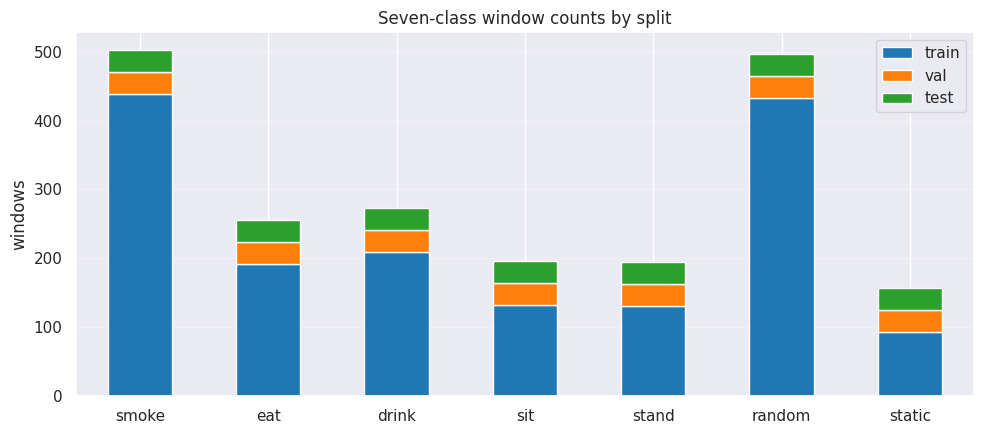

In [ ]:
# ---------------------------------------------------------------------------
# Class counts: total, per split, and per recording date.
# Windows = segments (one window per annotated interval). The split is
# class-balanced at the window level and date-stratified: every window is
# assigned exactly once, and a recording date can contribute to all three
# splits.
# ---------------------------------------------------------------------------
count_rows = []
for class_name, class_idx in SEVEN_CLASS_TO_IDX.items():
    row = {
        'class': class_name,
        'total': int((y7 == class_idx).sum()),
    }
    for split_name in ('train', 'val', 'test'):
        row[split_name] = int(
            (y7[SPLIT_INDICES[split_name]] == class_idx).sum()
        )
    count_rows.append(row)
CLASS_COUNTS = pd.DataFrame(count_rows).set_index('class')

print('Class counts by split (windows = segments):')
display(CLASS_COUNTS)

date_rows = []
for date in sorted(set(SESSION_KEYS.tolist())):
    mask = SESSION_KEYS == date
    row = {
        'date': date,
        'windows': int(mask.sum()),
    }
    for split_name in ('train', 'val', 'test'):
        row[split_name] = int((SAMPLE_SPLITS[mask] == split_name).sum())
    missing = []
    for class_name, class_idx in SEVEN_CLASS_TO_IDX.items():
        count = int(((y7 == class_idx) & mask).sum())
        row[class_name] = count
        if count == 0:
            missing.append(class_name)
    row['missing'] = ', '.join(missing) if missing else '-'
    date_rows.append(row)
DATE_CLASS_COUNTS = pd.DataFrame(date_rows).set_index('date')

print('\nClass counts by recording date (dates can span splits):')
display(DATE_CLASS_COUNTS)
print(f'\nStatic windows (class samples + background pool): {X_STATIC.shape[0]}')
print('Background tiers:', BACKGROUND_TABLE['tier'].value_counts().to_dict())

ax = CLASS_COUNTS[['train', 'val', 'test']].plot(
    kind='bar', stacked=True, figsize=(10, 4.5),
    color=['tab:blue', 'tab:orange', 'tab:green'],
)
ax.set_title('Seven-class window counts by split')
ax.set_xlabel('')
ax.set_ylabel('windows')
ax.grid(True, axis='y', alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


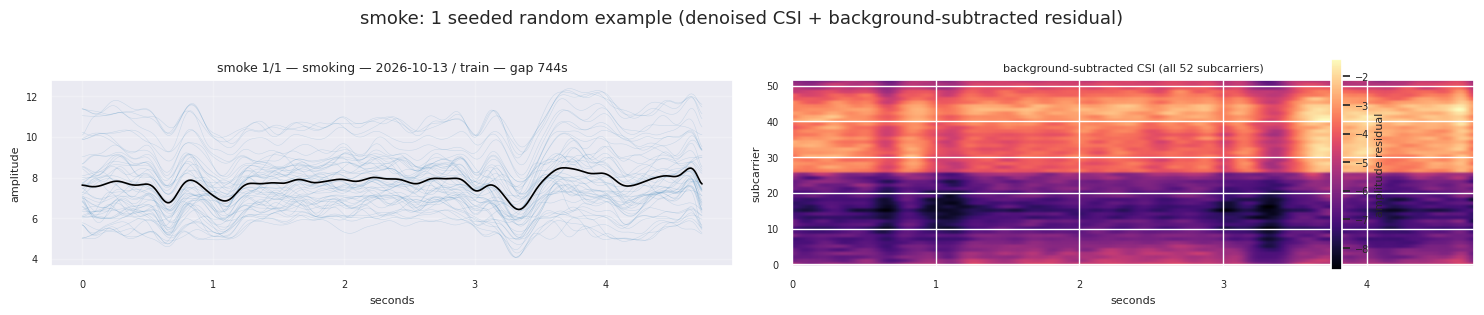

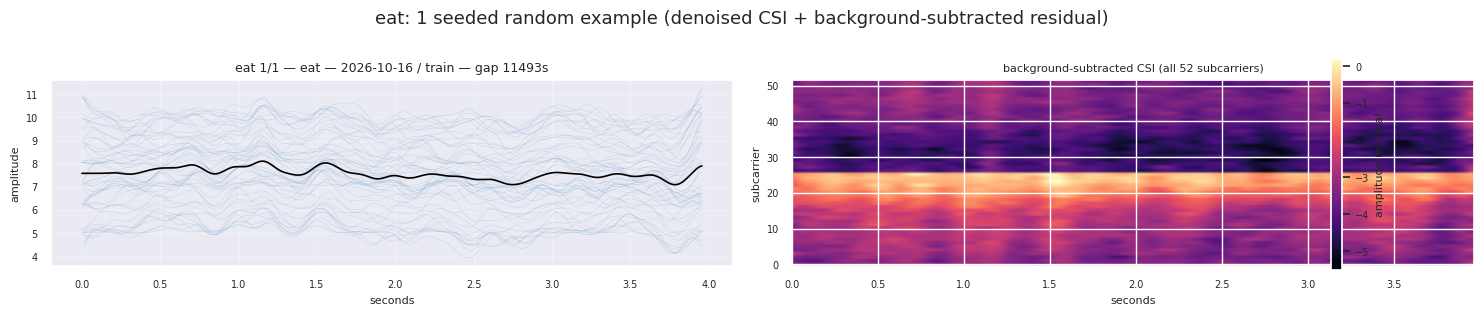

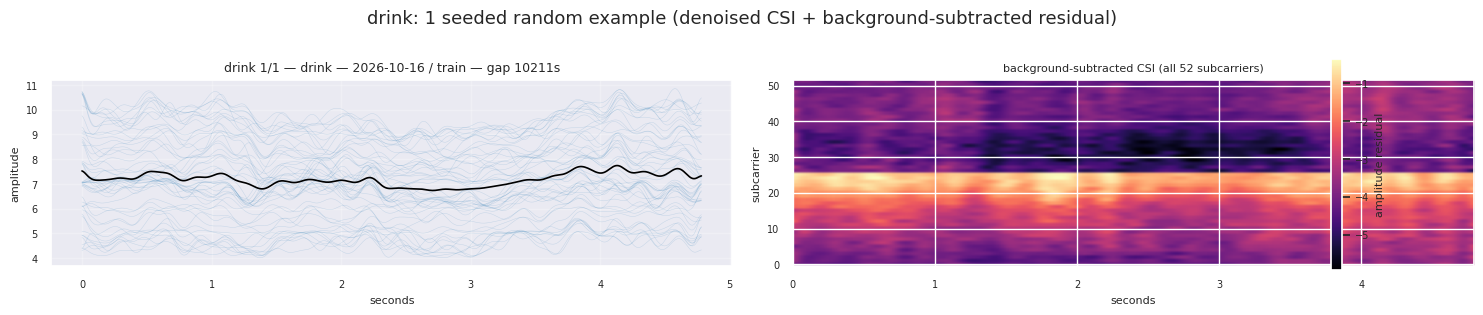

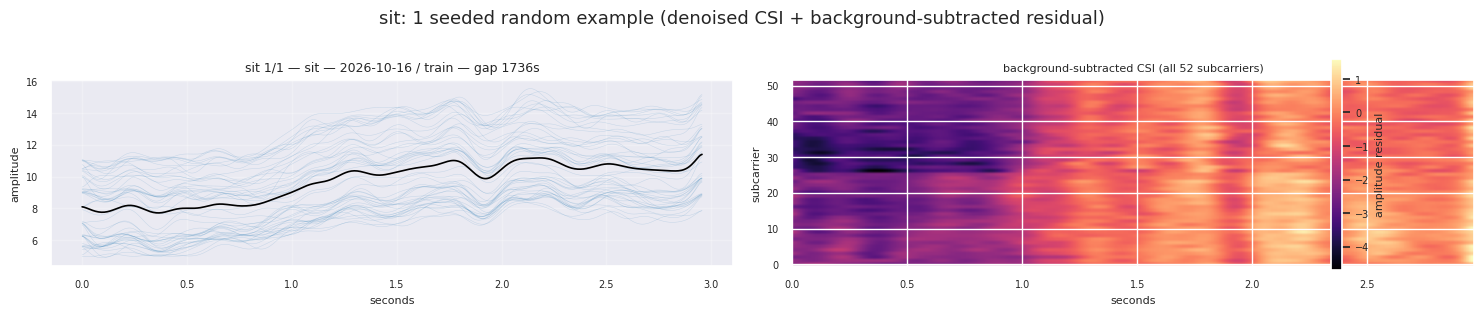

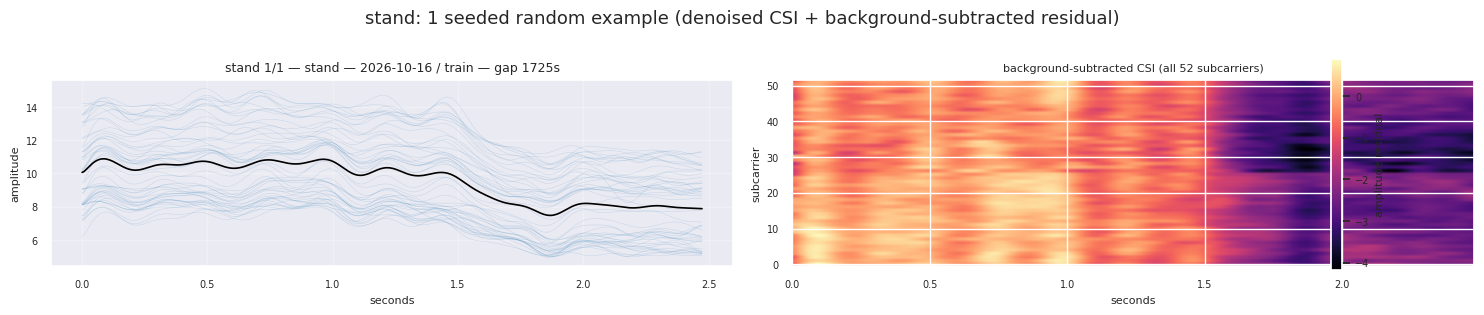

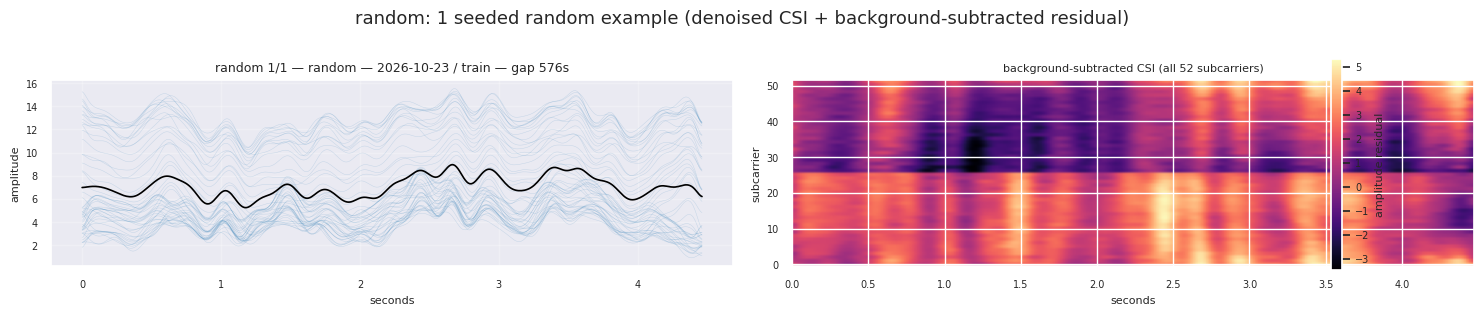

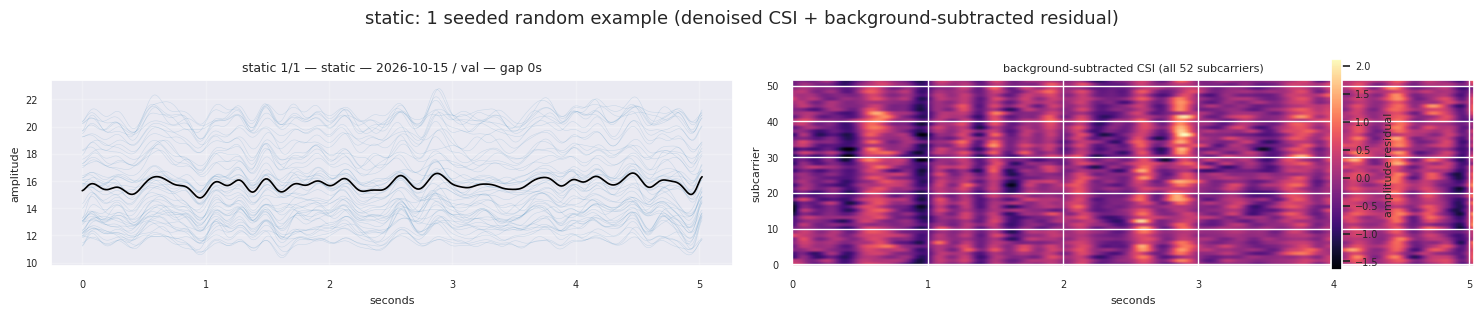

Selected examples by class and date:


date,2026-10-13,2026-10-15,2026-10-16,2026-10-23
class,,,,
drink,0,0,1,0
eat,0,0,1,0
random,0,0,0,1
sit,0,0,1,0
smoke,1,0,0,0
stand,0,0,1,0
static,0,1,0,0


Total selected: 7 windows (1 requested per class)


In [ ]:
# ---------------------------------------------------------------------------
# One seeded random sample per class:
# denoised CSI time series + background-subtracted CSI residual.
# One figure per class (1 row x 2 columns). Run this cell in the Colab UI;
# the 7 figures still exceed the MCP plot-output path.
# ---------------------------------------------------------------------------
N_EXAMPLES_PER_CLASS = 1
rng = np.random.default_rng(RANDOM_SEED)

selected_rows = []

for class_name, class_idx in SEVEN_CLASS_TO_IDX.items():
    candidates = np.flatnonzero(y7 == class_idx)
    if len(candidates) == 0:
        print(f'No samples for {class_name}')
        continue
    picks = rng.choice(
        candidates,
        size=min(N_EXAMPLES_PER_CLASS, len(candidates)),
        replace=False,
    ).tolist()

    residuals = [X_BG[pick] for pick in picks]
    vmin = min(float(residual.min()) for residual in residuals)
    vmax = max(float(residual.max()) for residual in residuals)

    fig, axes = plt.subplots(
        len(picks), 2, figsize=(15, max(3.2, 2.2 * len(picks))),
        squeeze=False,
    )
    last_image = None
    for row, pick in enumerate(picks):
        date = str(SESSION_KEYS[pick])
        split_name = str(SAMPLE_SPLITS[pick])
        original = str(SEGMENT_KEYS[pick]).split('|')[-1]
        gap = float(BACKGROUND_TABLE.loc[pick, 'gap_s'])
        selected_rows.append({
            'class': class_name,
            'original_annotation': original,
            'date': date,
            'split': split_name,
            'segment_key': str(SEGMENT_KEYS[pick]),
            'background_gap_s': gap,
        })

        # Left: denoised CSI, all 52 subcarriers faint plus their mean.
        t = np.arange(TARGET_PACKETS) / float(FS_VALUES[pick])
        axes[row, 0].plot(
            t, X[pick], color='tab:blue', linewidth=0.35, alpha=0.18
        )
        axes[row, 0].plot(
            t, X[pick].mean(axis=1), color='black', linewidth=1.2,
            label='subcarrier mean',
        )
        axes[row, 0].set_title(
            f'{class_name} {row + 1}/{len(picks)} — {original} — '
            f'{date} / {split_name} — gap {gap:.0f}s',
            fontsize=9,
        )
        axes[row, 0].set_xlabel('seconds', fontsize=8)
        axes[row, 0].set_ylabel('amplitude', fontsize=8)
        axes[row, 0].tick_params(labelsize=7)
        axes[row, 0].grid(True, alpha=0.25)

        # Right: background-subtracted CSI residual (time x subcarrier).
        residual = residuals[row]
        last_image = axes[row, 1].imshow(
            residual.T, origin='lower', aspect='auto', cmap='magma',
            vmin=vmin, vmax=vmax,
            extent=[
                0.0, TARGET_PACKETS / float(FS_VALUES[pick]),
                -0.5, residual.shape[1] - 0.5,
            ],
        )
        axes[row, 1].set_title(
            'background-subtracted CSI (all 52 subcarriers)',
            fontsize=8,
        )
        axes[row, 1].set_xlabel('seconds', fontsize=8)
        axes[row, 1].set_ylabel('subcarrier', fontsize=8)
        axes[row, 1].tick_params(labelsize=7)

    if last_image is not None:
        cbar = fig.colorbar(
            last_image, ax=axes[:, 1].tolist(),
            fraction=0.02, pad=0.01,
        )
        cbar.set_label('amplitude residual', fontsize=8)
        cbar.ax.tick_params(labelsize=7)

    _example_label = 'example' if len(picks) == 1 else 'examples'
    fig.suptitle(
        f'{class_name}: {len(picks)} seeded random {_example_label} '
        '(denoised CSI + background-subtracted residual)',
        fontsize=13,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.985])
    plt.show()

SELECTED_EXAMPLES = pd.DataFrame(selected_rows)
print('Selected examples by class and date:')
display(pd.crosstab(SELECTED_EXAMPLES['class'], SELECTED_EXAMPLES['date']))
print(f'Total selected: {len(SELECTED_EXAMPLES)} windows '
      f'({N_EXAMPLES_PER_CLASS} requested per class)')


### Class balance and sample inspection

The next two cells audit the seven-class dataset before modelling:

- **Class counts** — total and per-split window counts, per-date class counts (including any date missing a class), and the static background count. `static` is both a class and a background resource; its 157 windows are split 93/32/32 across train/val/test, and the same windows remain candidates for background subtraction.
- **Sample inspection** — one seeded random example per class, each shown as a denoised CSI time series (all 52 subcarriers faint plus their mean) and its background-subtracted CSI residual heatmap (time × subcarrier). One figure is produced per class with 1 row × 2 columns; the title records the original annotation label, recording date, split, and background gap, so a `random` sample drawn from `hand-wave` is visible as such. For `static` samples the residual is relative to the nearest *other* static window, never the sample itself.

The sample choice uses `RANDOM_SEED`, so it is reproducible across reruns. Run the visualization cell in the Colab UI; the seven figures exceed the MCP plot-output path.


In [ ]:
# ---------------------------------------------------------------------------
# 4. Training machinery: single-seed seven-class baseline.
# Checkpoint selection uses validation macro-F1; the best weights are restored
# before saving. A compact progress line is printed after every epoch.
# ---------------------------------------------------------------------------
ACTIVITY_TAG = f'{EXPERIMENT_TAG}_7class'


@tf.keras.utils.register_keras_serializable(package='smokeguard')
def sparse_crossentropy_with_smoothing(y_true, y_pred):
    """Sparse categorical cross-entropy with label smoothing."""
    y_true = tf.cast(y_true, tf.int32)
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0)
    nll = -tf.math.log(tf.gather(y_pred, y_true, batch_dims=1))
    smooth = -tf.reduce_mean(tf.math.log(y_pred), axis=-1)
    return (1.0 - LABEL_SMOOTHING) * nll + LABEL_SMOOTHING * smooth


class SmokeValidationCallback(tf.keras.callbacks.Callback):
    """Validation macro-F1 plus smoke ranking and thresholded metrics."""

    def __init__(self, X_val, y_val, mask=None):
        super().__init__()
        self.X_val = X_val
        self.y_val = y_val
        self.mask = mask
        self.smoke_idx = SEVEN_CLASS_TO_IDX['smoke']

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        probs = self.model.predict(self.X_val, verbose=0, batch_size=64)
        y_true = self.y_val
        if self.mask is not None:
            probs = probs[self.mask]
            y_true = self.y_val[self.mask]

        pred = np.argmax(probs, axis=1)
        logs['val_macro_f1'] = float(
            f1_score(y_true, pred, average='macro')
        )
        logs['val_balanced_accuracy'] = float(
            balanced_accuracy_score(y_true, pred)
        )

        smoke_pos = probs[:, self.smoke_idx]
        smoke_binary = (y_true == self.smoke_idx).astype(int)
        logs['val_smoke_ap'] = float(
            average_precision_score(smoke_binary, smoke_pos)
        )
        logs['val_smoke_auc'] = float(
            roc_auc_score(smoke_binary, smoke_pos)
        )

        precision, recall, thresholds = precision_recall_curve(
            smoke_binary, smoke_pos
        )
        precision, recall = precision[:-1], recall[:-1]
        f1_curve = 2.0 * precision * recall / (precision + recall + 1e-12)
        if len(f1_curve):
            idx = int(np.argmax(f1_curve))
            logs['val_smoke_f1'] = float(f1_curve[idx])
            logs['val_smoke_precision'] = float(precision[idx])
            logs['val_smoke_recall'] = float(recall[idx])
            logs['val_smoke_threshold'] = float(thresholds[idx])
        else:
            logs['val_smoke_f1'] = 0.0
            logs['val_smoke_precision'] = 0.0
            logs['val_smoke_recall'] = 0.0
            logs['val_smoke_threshold'] = 0.5


class BestWeightsCallback(tf.keras.callbacks.Callback):
    """Keep the weights from the best validation-macro-F1 epoch."""

    def __init__(self, monitor='val_macro_f1'):
        super().__init__()
        self.monitor = monitor
        self.best_score = None
        self.best_epoch = None
        self.best_weights = None
        self.best_logs = None

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        score = logs.get(self.monitor)
        if score is None:
            return
        score = float(score)
        if self.best_score is None or score > self.best_score:
            self.best_score = score
            self.best_epoch = int(epoch) + 1
            self.best_weights = [
                weight.copy() for weight in self.model.get_weights()
            ]
            self.best_logs = {}
            for key, value in logs.items():
                try:
                    self.best_logs[key] = float(value)
                except (TypeError, ValueError):
                    pass

    def restore_best(self, model):
        if self.best_weights is None:
            return False
        model.set_weights(self.best_weights)
        return True


class EpochProgressCallback(tf.keras.callbacks.Callback):
    """Print training/validation progress at the end of every epoch.

    Must be placed after SmokeValidationCallback and BestWeightsCallback in
    the callback list so the validation metrics and the best-epoch bookkeeping
    are available when the line is printed.
    """

    def __init__(self, best_weights_callback=None):
        super().__init__()
        self.best_weights_callback = best_weights_callback
        self.total_epochs = None
        self.epoch_start = None

    def on_train_begin(self, logs=None):
        self.total_epochs = int(self.params.get('epochs', 0))
        print(f'[training] fit start: up to {self.total_epochs} epochs; '
              'one summary line per epoch', flush=True)

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start = time.time()

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}

        def _fmt(key):
            value = logs.get(key)
            if value is None:
                return 'n/a'
            try:
                return f'{float(value):.4f}'
            except (TypeError, ValueError):
                return 'n/a'

        elapsed = (
            time.time() - self.epoch_start
            if self.epoch_start is not None else 0.0
        )
        lr = float(
            tf.keras.backend.get_value(self.model.optimizer.learning_rate)
        )
        best_text = ''
        callback = self.best_weights_callback
        if callback is not None and callback.best_score is not None:
            best_text = (
                f' | best val macro-F1 {callback.best_score:.4f} '
                f'@ epoch {callback.best_epoch}'
            )
            if callback.best_epoch == epoch + 1:
                best_text += ' (new best)'
        print(
            f'Epoch {epoch + 1:3d}/{self.total_epochs} | '
            f'train loss {_fmt("loss")} acc {_fmt("accuracy")} | '
            f'val loss {_fmt("val_loss")} acc {_fmt("val_accuracy")} | '
            f'val macro-F1 {_fmt("val_macro_f1")} '
            f'bal-acc {_fmt("val_balanced_accuracy")} | '
            f'smoke AP {_fmt("val_smoke_ap")} '
            f'AUC {_fmt("val_smoke_auc")} F1 {_fmt("val_smoke_f1")} | '
            f'lr {lr:.2e}{best_text} | {elapsed:.1f}s',
            flush=True,
        )

    def on_train_end(self, logs=None):
        callback = self.best_weights_callback
        if callback is not None and callback.best_score is not None:
            print(f'[training] best epoch {callback.best_epoch} with '
                  f'validation macro-F1 {callback.best_score:.4f}',
                  flush=True)


def history_metrics(history):
    return history.history if hasattr(history, 'history') else history


def save_history(path, history):
    metrics = history_metrics(history)
    if not metrics:
        return
    payload = {
        key: [float(value) for value in values]
        for key, values in metrics.items()
    }
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(payload, f, indent=2)


def load_history(path):
    if not os.path.exists(path):
        return None
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)


def _log_value(logs, key):
    value = (logs or {}).get(key)
    return float(value) if value is not None else None


def train_activity_model(data):
    """Load the saved baseline, or fit a single seed selected by macro-F1."""
    os.makedirs(MODEL_DIR, exist_ok=True)
    os.makedirs(MODEL_HISTORY_DIR, exist_ok=True)

    reusable = (
        os.path.exists(MODEL_PATH) and os.path.exists(MODEL_META_PATH)
        and not FORCE_RETRAIN
    )
    if reusable:
        with open(MODEL_META_PATH, 'r', encoding='utf-8') as f:
            meta = json.load(f)
        if meta.get('classes') != list(SEVEN_CLASSES):
            print(f'[training:{ACTIVITY_TAG}] ignored the existing checkpoint: '
                  'its class list differs from SEVEN_CLASSES.')
            reusable = False
    if reusable:
        model = tf.keras.models.load_model(
            MODEL_PATH,
            compile=False,
        )
        model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=INITIAL_LR),
            loss=sparse_crossentropy_with_smoothing,
            metrics=['accuracy'],
        )
        history = load_history(MODEL_HISTORY_JSON)
        print(f'[training:{ACTIVITY_TAG}] loaded existing checkpoint '
              f'(best epoch {meta.get("best_epoch")}, '
              f'val macro-F1 {meta.get("best_val_macro_f1")}).')
        return model, history, meta

    if os.path.exists(MODEL_PATH) or os.path.exists(MODEL_META_PATH):
        stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
        if os.path.exists(MODEL_PATH):
            shutil.copy2(MODEL_PATH, os.path.join(
                MODEL_HISTORY_DIR, f'{ACTIVITY_TAG}.{stamp}.keras'))
        if os.path.exists(MODEL_META_PATH):
            shutil.copy2(MODEL_META_PATH, os.path.join(
                MODEL_HISTORY_DIR, f'{ACTIVITY_TAG}.{stamp}.meta.json'))
        print(f'[training:{ACTIVITY_TAG}] archived the previous checkpoint.')

    train_classes = np.unique(data['y_train'])
    balanced = compute_class_weight(
        class_weight='balanced', classes=train_classes, y=data['y_train']
    )
    class_weight = {
        int(cls): float(weight)
        for cls, weight in zip(train_classes, balanced)
    }
    class_weight[SEVEN_CLASS_TO_IDX['smoke']] *= SMOKING_WEIGHT_MULTIPLIER
    print(f'[training:{ACTIVITY_TAG}] class weights: {class_weight}')

    tf.keras.utils.set_random_seed(RANDOM_SEED)
    model = build_activity_model(MODEL_INPUT_SHAPE)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=INITIAL_LR),
        loss=sparse_crossentropy_with_smoothing,
        metrics=['accuracy'],
    )

    smoke_callback = SmokeValidationCallback(
        data['X_val'], data['y_val'], data['val_mask']
    )
    best_weights = BestWeightsCallback(monitor='val_macro_f1')
    progress_callback = EpochProgressCallback(best_weights)
    lr_scheduler = ReduceLROnPlateau(
        monitor='val_macro_f1', mode='max', factor=0.5, patience=15,
        min_lr=1e-6, verbose=0,
    )
    history = model.fit(
        data['X_train'], data['y_train'],
        validation_data=(data['X_val'], data['y_val']),
        epochs=TRAIN_EPOCHS,
        batch_size=32,
        class_weight=class_weight,
        callbacks=[
            smoke_callback, best_weights, progress_callback, lr_scheduler,
        ],
        verbose=1,
    )

    best_weights.restore_best(model)
    model.save(MODEL_PATH)
    save_history(MODEL_HISTORY_JSON, history)
    logs = best_weights.best_logs or {}

    meta = {
        'tag': ACTIVITY_TAG,
        'classes': list(SEVEN_CLASSES),
        'model_path': MODEL_PATH,
        'feature_pipeline': FEATURE_PIPELINE,
        'model_input_shape': list(MODEL_INPUT_SHAPE),
        'parameters': int(model.count_params()),
        'lstm_parameters': int(
            model.get_layer('temporal_lstm').count_params()
        ),
        'resnet_filters': list(RESNET_FILTERS),
        'lstm_units': int(LSTM_UNITS),
        'dense_units': int(DENSE_UNITS),
        'dropout_rate': float(DROPOUT_RATE),
        'spatial_dropout_rate': float(SPATIAL_DROPOUT_RATE),
        'l2_weight': float(L2_WEIGHT),
        'use_augmentation': bool(USE_AUGMENTATION),
        'augment_shift_max': int(AUGMENT_SHIFT_MAX),
        'augment_scale_min': float(AUGMENT_SCALE_MIN),
        'augment_scale_max': float(AUGMENT_SCALE_MAX),
        'augment_noise_std': float(AUGMENT_NOISE_STD),
        'epochs': int(TRAIN_EPOCHS),
        'epochs_run': int(len(history.history.get('loss', []))),
        'best_epoch': best_weights.best_epoch,
        'selection_metric': 'val_macro_f1',
        'best_selection_score': (
            float(best_weights.best_score)
            if best_weights.best_score is not None else None
        ),
        'best_val_macro_f1': _log_value(logs, 'val_macro_f1'),
        'best_val_smoke_ap': _log_value(logs, 'val_smoke_ap'),
        'best_val_smoke_f1': _log_value(logs, 'val_smoke_f1'),
        'best_val_smoke_auc': _log_value(logs, 'val_smoke_auc'),
        'class_weight': class_weight,
        'smoke_weight_multiplier': SMOKING_WEIGHT_MULTIPLIER,
        'label_smoothing': LABEL_SMOOTHING,
        'background': 'nearest_static_window_mean',
        'background_mode': BACKGROUND_MODE,
        'normalization': (
            'none; raw background-subtracted CSI window + input '
            'LayerNormalization'
        ),
        'zscore': 'removed',
        'layer_norm': 'retained',
        'energy_branch': False,
        'amplitude_branch': False,
        'stft': False,
        'split_scheme': SPLIT_SCHEME,
        'split_path': SPLIT_PATH,
        'split_seed': int(RANDOM_SEED),
        'split_fractions': _configured_fractions(),
        'split_leakage': 'within-session; dates may span splits',
        'frozen_split_sha256': split_sha256(SPLIT),
        'smoking_threshold_policy': SMOKING_THRESHOLD_POLICY,
        'trained_at_utc': utc_now_iso(),
    }
    _atomic_write_json(MODEL_META_PATH, meta)
    print(f'[training:{ACTIVITY_TAG}] saved {MODEL_PATH}')
    print(f'[training:{ACTIVITY_TAG}] best epoch {meta["best_epoch"]}, '
          f'val macro-F1 {meta["best_val_macro_f1"]:.4f}')
    return model, history, meta


## 4. Training — seven-class baseline

The final task has seven classes: `smoke, eat, drink, sit, stand, random, static`. `static` is now a full class and is still used to build the nearest-in-time background; for static samples the background excludes the sample itself. `hand-wave` is merged into `random`. The feature pipeline is:

```
denoised X (420, 52)
  -> subtract the nearest-in-time static background (52,); static samples exclude self
  -> background-subtracted CSI window (420, 52)
  -> 1D ResNet (32/64/128 filters) -> LSTM(160)
  -> Dropout(0.6) -> Dense(64) -> Dense(7, softmax)
```

There is **no STFT conversion**, **no per-window z-score**, and **no energy/amplitude branch**. The background subtraction survives into the 1D window, and the model retains its input `LayerNormalization`.

Training uses the **frozen date-stratified, class-balanced split**: 1,628 train, 224 validation, and 224 test windows, with 32 windows per class in each held-out split and all seven classes present in every split. The 32/class count is pinned so the activity validation/test windows are identical to the six-class benchmark; the 32 static windows in each held-out split are new. Validation and test assignments are frozen in `splits/date_stratified_balanced_7class_32perclass_frozen.json`. This is a within-session split, so windows from one recording date can appear in all three splits; the metrics are within-session and optimistic relative to a held-out recording date.

**Active model.** The model is selected by **validation macro-F1** over all seven classes. It has **319,271 parameters** (above the 200k target); with `RESNET_FILTERS=(32, 64, 128)`, `LSTM_UNITS=160`, and `DENSE_UNITS=64`, the LSTM layer alone has **184,960** parameters. Training runs up to 150 epochs and uses balanced seven-class weights with `SMOKING_WEIGHT_MULTIPLIER = 6.0`, label smoothing 0.05, dropout 0.6, L2 weight decay `5e-4`, training-only 1D augmentation (time roll, scale, relative noise), `ReduceLROnPlateau` on validation macro-F1, and a best-weights callback that restores the best epoch before saving.

The validation split has 224 windows, so single-run validation scores still vary. The training function uses `RANDOM_SEED` for reproducibility; a small seed sweep can be used when selecting the final checkpoint.

**Live training output.** Every epoch prints one line with the epoch number, train loss/accuracy, validation loss/accuracy, validation macro-F1 and balanced accuracy, smoke AP/AUC/F1, the current learning rate, the best validation macro-F1 and its epoch, and the epoch time. Keras also shows its per-batch progress bar during each epoch. The selected checkpoint is the epoch with the best validation macro-F1, restored before saving.

The active checkpoint is `models/csi_resnet_lstm_7class.keras` with its `models/csi_resnet_lstm_7class.meta.json`. `FORCE_RETRAIN=True` trains a fresh seven-class model; set it to `False` after the first successful run to reuse the checkpoint. The training-history JSON is written under `models/history/`.


In [ ]:
# ---------------------------------------------------------------------------
# Split-hash guard: never evaluate a stale checkpoint against a new split.
# ---------------------------------------------------------------------------
if os.path.exists(MODEL_META_PATH):
    with open(MODEL_META_PATH, 'r', encoding='utf-8') as _f:
        _meta = json.load(_f)
    if (_meta.get('frozen_split_sha256') != split_sha256(SPLIT)
            or _meta.get('classes') != list(SEVEN_CLASSES)):
        print('[experiment] checkpoint split hash or class list differs from '
              'the active split; setting FORCE_RETRAIN=True.')
        FORCE_RETRAIN = True
else:
    print(f'[experiment] activity tag: {ACTIVITY_TAG}')


In [ ]:
# ---------------------------------------------------------------------------
# Train (or load) the 1D ResNet-LSTM seven-class model on the frozen
# date-stratified, class-balanced split.
# ---------------------------------------------------------------------------
if X_BG.size == 0:
    raise RuntimeError('No seven-class features found; run the data-preparation '
                       'cells first.')

ACTIVITY_MODEL, ACTIVITY_HISTORY, ACTIVITY_META = (
    train_activity_model(SESSION_DATA)
)


[training:datestrat_balanced_nearestbg_1dresnet_7class] loaded existing checkpoint (best epoch 142, val macro-F1 0.890622149589541).


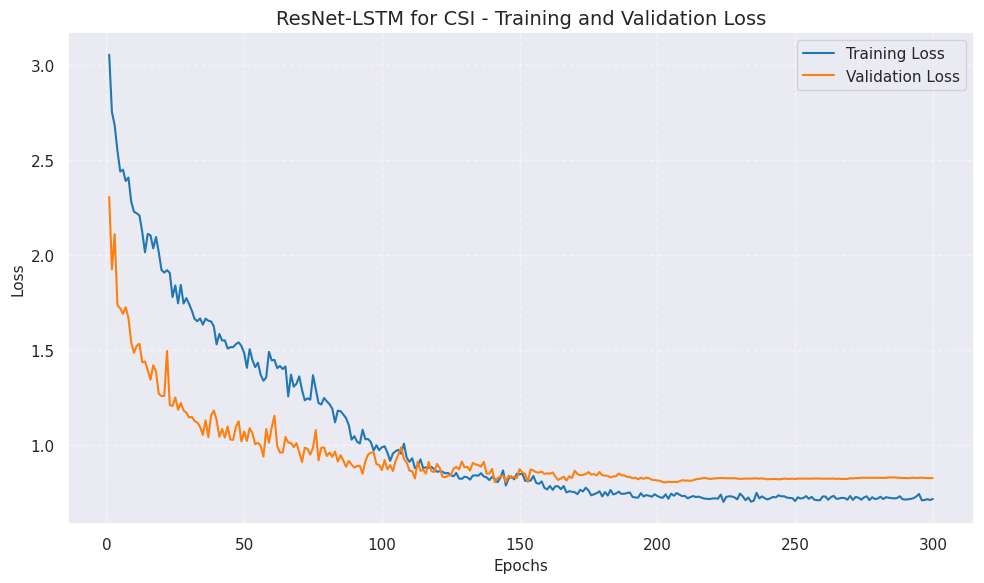

In [ ]:
import matplotlib.pyplot as plt

if ACTIVITY_HISTORY:
    history_dict = ACTIVITY_HISTORY
    epochs_range = range(1, len(history_dict['loss']) + 1)

    fig = plt.figure(figsize=(10, 6))
    plt.plot(epochs_range, history_dict['loss'], label='Training Loss', color='tab:blue', linewidth=1.5)
    if 'val_loss' in history_dict:
        plt.plot(epochs_range, history_dict['val_loss'], label='Validation Loss', color='tab:orange', linewidth=1.5)

    plt.title('ResNet-LSTM for CSI - Training and Validation Loss', fontsize=14)
    plt.xlabel('Epochs', fontsize=11)
    plt.ylabel('Loss', fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(fontsize=11)
    plt.tight_layout()
    plt.show()
else:
    print('No training history found to visualize.')

In [ ]:
# ---------------------------------------------------------------------------
# Post-training diagnostic: prediction distribution, confusion, model metadata.
# ---------------------------------------------------------------------------
test_prob = ACTIVITY_MODEL.predict(SESSION_DATA['X_test'], verbose=0)
test_pred = test_prob.argmax(axis=1)
test_true = SESSION_DATA['y_test']

pred_names = pd.Series(
    [SEVEN_CLASSES[int(i)] for i in test_pred], name='pred'
)
true_names = pd.Series(
    [SEVEN_CLASSES[int(i)] for i in test_true], name='true'
)

print('Test prediction distribution:')
display(pred_names.value_counts().to_frame('windows'))
print('\nTest confusion (rows=true, cols=pred):')
display(pd.crosstab(true_names, pred_names))
print('\nRow-normalized confusion:')
display(pd.crosstab(true_names, pred_names, normalize='index').round(3))

print('\nModel metadata:')
display(pd.Series(ACTIVITY_META, name='value').to_frame())


Test prediction distribution:


,windows
pred,
random,35
eat,35
sit,33
stand,32
static,30
smoke,30
drink,29



Test confusion (rows=true, cols=pred):


pred,drink,eat,random,sit,smoke,stand,static
true,,,,,,,
drink,21,5,3,0,3,0,0
eat,1,29,1,1,0,0,0
random,3,1,26,0,1,0,1
sit,0,0,1,31,0,0,0
smoke,4,0,3,0,25,0,0
stand,0,0,0,0,0,32,0
static,0,0,1,1,1,0,29



Row-normalized confusion:


pred,drink,eat,random,sit,smoke,stand,static
true,,,,,,,
drink,0.656,0.156,0.094,0.000,0.094,0.0,0.000
eat,0.031,0.906,0.031,0.031,0.000,0.0,0.000
random,0.094,0.031,0.812,0.000,0.031,0.0,0.031
sit,0.000,0.000,0.031,0.969,0.000,0.0,0.000
smoke,0.125,0.000,0.094,0.000,0.781,0.0,0.000
stand,0.000,0.000,0.000,0.000,0.000,1.0,0.000
static,0.000,0.000,0.031,0.031,0.031,0.0,0.906



Model metadata:


,value
amplitude_branch,False
augment_noise_std,0.05
augment_scale_max,1.1
augment_scale_min,0.9
augment_shift_max,12
background,nearest_static_window_mean
background_mode,nearest_static
best_epoch,142
best_selection_score,0.890622
best_val_macro_f1,0.890622


## 5. Evaluation results

This section reports five views of the seven-class baseline on the **frozen date-stratified split** (within-session evaluation):

1. **Multi-class results** — summary and per-class metrics on the held-out test split.
2. **Multi-class confusion matrix** — argmax predictions over `smoke, eat, drink, sit, stand, random, static`.
3. **Smoke vs non-smoke results** — precision, recall, F1, AP, ROC-AUC, accuracy, and TP/FP/FN/TN for `P(smoke)` at the deployed threshold. `static` is treated as non-smoke.
4. **Binary confusion matrix** — the thresholded smoke decision.
5. **ROC curve** — the unthresholded smoke ranking.

Metric definitions:

- **Multi-class** uses the argmax of the seven-class softmax on the held-out test split (224 windows: 32 per class).
- **Smoke binary** uses `P(smoke) >= threshold`. The deployed threshold is **calibrated on the test split**: the validation smoke prevalence is applied to the same quantile of that split's **unlabeled** `P(smoke)` scores. This uses no test labels. The absolute validation threshold is still reported as a reference (`bin_f1_at_val_threshold`, `bin_recall_at_val_threshold`). Adding static windows to test changes the non-smoke prevalence and therefore the deployed threshold relative to the six-class run.
- **Validation and test are within-session subsets of the same recording dates**: windows from one session can appear in train and test, so these metrics measure within-session generalisation, not cross-session generalisation. They are optimistic relative to a held-out recording date.
- **ROC-AUC** and **AP** use the unthresholded `P(smoke)` on the held-out test split.
- **Training curves** are not plotted here. The per-epoch progress line printed during training shows train/validation loss, accuracy, macro-F1, balanced accuracy, and smoke metrics; the full history is saved to `models/history/`.


In [ ]:
# ---------------------------------------------------------------------------
# Core evaluation for the seven-class model.
# Multi-class metrics use argmax; smoke metrics use P(smoke) >= threshold.
# The deployed threshold is quantile-calibrated on the test split from
# unlabeled scores.
# ---------------------------------------------------------------------------
smoke_idx = SEVEN_CLASS_TO_IDX['smoke']


def _model_inputs(data, split):
    """Background-subtracted CSI windows for the 1D ResNet-LSTM model."""
    return data[f'X_{split}']


def _threshold_candidates(y_true_binary, positive_prob):
    precision, recall, thresholds = precision_recall_curve(
        y_true_binary, positive_prob
    )
    if len(thresholds) == 0:
        raise RuntimeError('Could not tune a smoke threshold.')
    precision = precision[:-1]
    recall = recall[:-1]
    f1 = 2.0 * precision * recall / (precision + recall + 1e-12)
    f1_idx = int(np.argmax(f1))
    if SMOKING_THRESHOLD_OBJECTIVE == 'precision':
        valid = np.flatnonzero(precision >= SMOKING_PRECISION_TARGET)
        idx = (
            int(valid[np.argmax(recall[valid])]) if len(valid) else f1_idx
        )
    elif SMOKING_THRESHOLD_OBJECTIVE == 'recall':
        # precision_recall_curve returns increasing thresholds, so recall is
        # non-increasing. The last valid index is the highest threshold that
        # still meets the recall floor, i.e. the highest-precision point.
        valid = np.flatnonzero(recall >= SMOKING_RECALL_TARGET)
        if len(valid):
            idx = int(valid[-1])
        else:
            idx = int(np.argmax(recall))
            print(f'[threshold] validation recall target '
                  f'{SMOKING_RECALL_TARGET:.2f} is unreachable; using the '
                  f'maximum validation recall {float(recall[idx]):.4f}.')
    else:
        idx = f1_idx
    return float(thresholds[idx]), float(precision[idx]), float(recall[idx])


def _session_quantile_threshold(scores, positive_rate):
    """Threshold at the (1 - positive_rate) quantile of a score set.

    Unsupervised calibration: it uses only unlabeled P(smoke) scores from the
    test split and the validation prevalence prior, never test labels.
    """
    scores = np.asarray(scores, dtype=float)
    rate = float(np.clip(positive_rate, 0.0, 1.0))
    if scores.size == 0:
        return 0.5
    return float(np.quantile(scores, 1.0 - rate))


def evaluate_activity_model(name, model, data):
    """Return seven-class, smoke-binary, ROC, and confusion data."""
    val_prob = model.predict(_model_inputs(data, 'val'), verbose=0)
    test_prob = model.predict(_model_inputs(data, 'test'), verbose=0)

    if (val_prob.shape[1] != len(SEVEN_CLASSES)
            or test_prob.shape[1] != len(SEVEN_CLASSES)):
        raise RuntimeError(
            'Model output width does not match SEVEN_CLASSES; retrain the '
            'seven-class head.'
        )

    val_mask = data['val_mask']
    test_mask = data['test_mask']

    val_y = data['y_val'][val_mask]
    if val_y.size and int(val_y.max()) >= len(SEVEN_CLASSES):
        raise RuntimeError('Validation labels contain an id outside SEVEN_CLASSES.')
    val_pos = val_prob[val_mask, smoke_idx]
    val_binary = (val_y == smoke_idx).astype(int)
    val_threshold, val_precision, val_recall = _threshold_candidates(
        val_binary, val_pos
    )
    val_positive_rate = float(val_binary.mean())

    test_y = data['y_test'][test_mask]
    if test_y.size and int(test_y.max()) >= len(SEVEN_CLASSES):
        raise RuntimeError('Test labels contain an id outside SEVEN_CLASSES.')
    test_prob_masked = test_prob[test_mask]
    test_pos = test_prob_masked[:, smoke_idx]
    test_binary = (test_y == smoke_idx).astype(int)

    threshold_policy = globals().get(
        'SMOKING_THRESHOLD_POLICY', 'validation_threshold'
    )
    if threshold_policy == 'session_quantile':
        test_threshold = _session_quantile_threshold(
            test_pos, val_positive_rate
        )
    else:
        test_threshold = float(val_threshold)

    y_pred_mc = np.argmax(test_prob_masked, axis=1)
    y_pred_bin = (test_pos >= test_threshold).astype(int)
    # Reference only: the absolute validation threshold transferred to test.
    y_pred_bin_val = (test_pos >= val_threshold).astype(int)

    precision, recall, f1, support = precision_recall_fscore_support(
        test_y, y_pred_mc, labels=np.arange(len(SEVEN_CLASSES)),
        zero_division=0,
    )
    per_class = pd.DataFrame({
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'support': support,
    }, index=SEVEN_CLASSES)

    cm_binary = confusion_matrix(test_binary, y_pred_bin, labels=[0, 1])
    tn, fp, fn, tp = cm_binary.ravel()

    roc_fpr, roc_tpr, _ = roc_curve(test_binary, test_pos)
    roc_auc = float(roc_auc_score(test_binary, test_pos))

    threshold_pred = (test_pos >= test_threshold)
    negatives = max(int((test_binary == 0).sum()), 1)
    positives = max(int((test_binary == 1).sum()), 1)
    threshold_fpr = float(
        ((threshold_pred == 1) & (test_binary == 0)).sum() / negatives
    )
    threshold_tpr = float(
        ((threshold_pred == 1) & (test_binary == 1)).sum() / positives
    )

    metrics = {
        'name': name,
        'n_test': int(test_mask.sum()),
        'threshold': test_threshold,
        'val_threshold': float(val_threshold),
        'threshold_policy': threshold_policy,
        'calibration_rate': val_positive_rate,
        'val_precision': val_precision,
        'val_recall': val_recall,
        'mc_accuracy': float(accuracy_score(test_y, y_pred_mc)),
        'mc_balanced_accuracy': float(
            balanced_accuracy_score(test_y, y_pred_mc)
        ),
        'mc_macro_f1': float(
            f1_score(test_y, y_pred_mc, average='macro')
        ),
        'mc_weighted_f1': float(
            f1_score(test_y, y_pred_mc, average='weighted')
        ),
        'bin_precision': float(
            precision_score(test_binary, y_pred_bin, zero_division=0)
        ),
        'bin_recall': float(
            recall_score(test_binary, y_pred_bin, zero_division=0)
        ),
        'bin_f1': float(
            f1_score(test_binary, y_pred_bin, zero_division=0)
        ),
        'bin_ap': float(
            average_precision_score(test_binary, test_pos)
        ),
        'bin_roc_auc': roc_auc,
        'threshold_fpr': threshold_fpr,
        'threshold_tpr': threshold_tpr,
        'bin_accuracy': float(
            accuracy_score(test_binary, y_pred_bin)
        ),
        'bin_balanced_accuracy': float(
            balanced_accuracy_score(test_binary, y_pred_bin)
        ),
        'bin_precision_at_val_threshold': float(
            precision_score(test_binary, y_pred_bin_val, zero_division=0)
        ),
        'bin_recall_at_val_threshold': float(
            recall_score(test_binary, y_pred_bin_val, zero_division=0)
        ),
        'bin_f1_at_val_threshold': float(
            f1_score(test_binary, y_pred_bin_val, zero_division=0)
        ),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp),
    }

    print(
        f'[{name}] test={metrics["n_test"]} windows; '
        f'policy={threshold_policy}; '
        f'test threshold={test_threshold:.4f} '
        f'(val threshold={val_threshold:.4f}); '
        f'seven-class macro-F1={metrics["mc_macro_f1"]:.4f}; '
        f'smoke P={metrics["bin_precision"]:.4f} '
        f'R={metrics["bin_recall"]:.4f} '
        f'F1={metrics["bin_f1"]:.4f} '
        f'AP={metrics["bin_ap"]:.4f} '
        f'ROC-AUC={metrics["bin_roc_auc"]:.4f}'
    )

    return {
        'name': name,
        'metrics': metrics,
        'per_class': per_class,
        'y_test': test_y,
        'y_pred_mc': y_pred_mc,
        'y_binary': test_binary,
        'y_pred_bin': y_pred_bin,
        'test_pos': test_pos,
        'roc_fpr': roc_fpr,
        'roc_tpr': roc_tpr,
    }


In [ ]:
# ---------------------------------------------------------------------------
# 2. Seven-class classification results.
# ---------------------------------------------------------------------------
SESSION_RESULTS = evaluate_activity_model(
    f'seven-class {SPLIT_LABEL}', ACTIVITY_MODEL, SESSION_DATA
)

MULTICLASS_RESULTS = pd.DataFrame([{
    'split': SESSION_RESULTS['name'],
    'test windows': SESSION_RESULTS['metrics']['n_test'],
    'accuracy': SESSION_RESULTS['metrics']['mc_accuracy'],
    'balanced accuracy': SESSION_RESULTS['metrics']['mc_balanced_accuracy'],
    'macro F1': SESSION_RESULTS['metrics']['mc_macro_f1'],
    'weighted F1': SESSION_RESULTS['metrics']['mc_weighted_f1'],
}]).set_index('split')

print('Seven-class results (argmax, held-out test)')
display(MULTICLASS_RESULTS.round(4))

PER_CLASS_RESULTS = SESSION_RESULTS['per_class'].copy()
PER_CLASS_RESULTS.index.name = 'class'
print('\nPer-class results (argmax, held-out test)')
display(PER_CLASS_RESULTS.round(4))


[seven-class date-stratified class-balanced split (7 classes, 32/class held out)] test=224 windows; policy=session_quantile; test threshold=0.3259 (val threshold=0.2363); seven-class macro-F1=0.8609; smoke P=0.7812 R=0.7812 F1=0.7812 AP=0.8335 ROC-AUC=0.9526
Seven-class results (argmax, held-out test)


,test windows,accuracy,balanced accuracy,macro F1,weighted F1
split,,,,,
"seven-class date-stratified class-balanced split (7 classes, 32/class held out)",224,0.8616,0.8616,0.8609,0.8609



Per-class results (argmax, held-out test)


,precision,recall,f1,support
class,,,,
smoke,0.8333,0.7812,0.8065,32
eat,0.8286,0.9062,0.8657,32
drink,0.7241,0.6562,0.6885,32
sit,0.9394,0.9688,0.9538,32
stand,1.0000,1.0000,1.0000,32
random,0.7429,0.8125,0.7761,32
static,0.9667,0.9062,0.9355,32


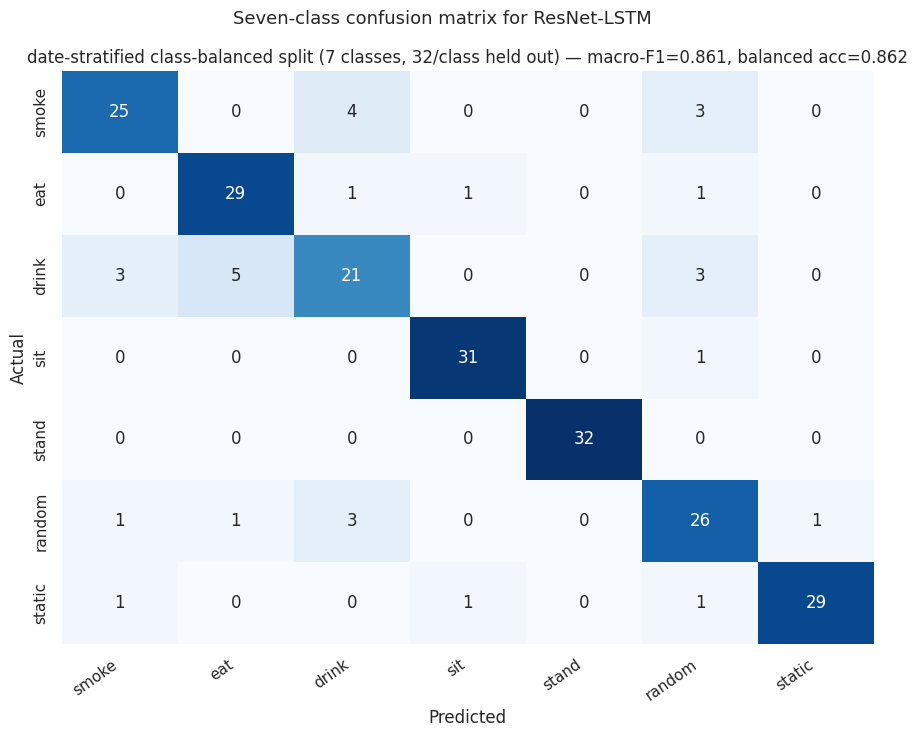

In [ ]:
# ---------------------------------------------------------------------------
# 3. Seven-class confusion matrix (held-out test, argmax).
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 7.5))

cm = confusion_matrix(
    SESSION_RESULTS['y_test'], SESSION_RESULTS['y_pred_mc'],
    labels=np.arange(len(SEVEN_CLASSES)),
)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
    xticklabels=SEVEN_CLASSES, yticklabels=SEVEN_CLASSES,
)
plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(
    f"{SPLIT_LABEL} — macro-F1="
    f"{SESSION_RESULTS['metrics']['mc_macro_f1']:.3f}, "
    f"balanced acc="
    f"{SESSION_RESULTS['metrics']['mc_balanced_accuracy']:.3f}"
)

fig.suptitle(
    'Seven-class confusion matrix for ResNet-LSTM',
    fontsize=13,
)
fig.tight_layout()
plt.show()


In [ ]:
# ---------------------------------------------------------------------------
# 4. Smoke vs non-smoke results from the seven-class model.
# Primary row uses the session-quantile calibrated threshold; the last three
# columns show the absolute validation threshold for comparison.
# ---------------------------------------------------------------------------
SMOKE_RESULTS = pd.DataFrame([{
    'split': SESSION_RESULTS['name'],
    'test windows': SESSION_RESULTS['metrics']['n_test'],
    'threshold policy': SESSION_RESULTS['metrics']['threshold_policy'],
    'threshold': SESSION_RESULTS['metrics']['threshold'],
    'precision': SESSION_RESULTS['metrics']['bin_precision'],
    'recall': SESSION_RESULTS['metrics']['bin_recall'],
    'F1': SESSION_RESULTS['metrics']['bin_f1'],
    'AP': SESSION_RESULTS['metrics']['bin_ap'],
    'ROC-AUC': SESSION_RESULTS['metrics']['bin_roc_auc'],
    'accuracy': SESSION_RESULTS['metrics']['bin_accuracy'],
    'balanced accuracy': SESSION_RESULTS['metrics']['bin_balanced_accuracy'],
    'TP': SESSION_RESULTS['metrics']['tp'],
    'FP': SESSION_RESULTS['metrics']['fp'],
    'FN': SESSION_RESULTS['metrics']['fn'],
    'TN': SESSION_RESULTS['metrics']['tn'],
    'P @ val threshold': SESSION_RESULTS['metrics']['bin_precision_at_val_threshold'],
    'R @ val threshold': SESSION_RESULTS['metrics']['bin_recall_at_val_threshold'],
    'F1 @ val threshold': SESSION_RESULTS['metrics']['bin_f1_at_val_threshold'],
}]).set_index('split')

print('Smoke results from the seven-class model '
      '(P(smoke) >= session-quantile calibrated threshold)')
display(SMOKE_RESULTS.round(4))


Smoke results from the seven-class model (P(smoke) >= session-quantile calibrated threshold)


,test windows,threshold policy,threshold,precision,recall,F1,AP,ROC-AUC,accuracy,balanced accuracy,TP,FP,FN,TN,P @ val threshold,R @ val threshold,F1 @ val threshold
split,,,,,,,,,,,,,,,,,
"seven-class date-stratified class-balanced split (7 classes, 32/class held out)",224,session_quantile,0.3259,0.7812,0.7812,0.7812,0.8335,0.9526,0.9375,0.8724,25,7,7,185,0.7714,0.8438,0.806


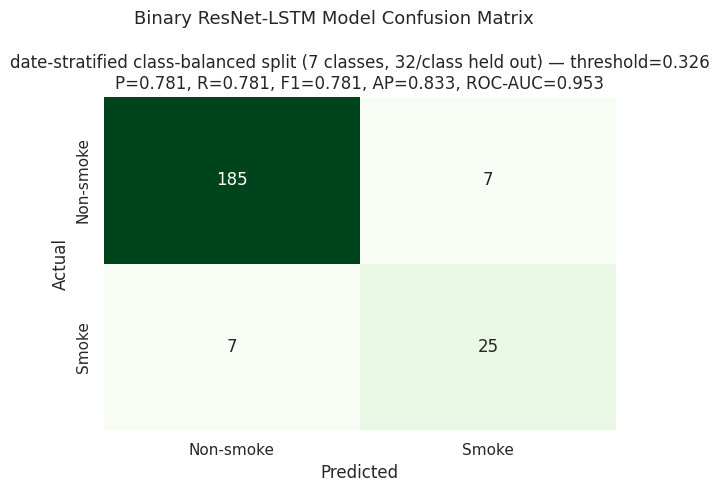

In [ ]:
# ---------------------------------------------------------------------------
# 5. Binary smoke confusion matrix (held-out test).
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 5))

cm = confusion_matrix(
    SESSION_RESULTS['y_binary'], SESSION_RESULTS['y_pred_bin'],
    labels=[0, 1],
)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax,
    xticklabels=['Non-smoke', 'Smoke'],
    yticklabels=['Non-smoke', 'Smoke'],
)
m = SESSION_RESULTS['metrics']
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(
    f"{SPLIT_LABEL} — threshold={m['threshold']:.3f}\n"
    f"P={m['bin_precision']:.3f}, R={m['bin_recall']:.3f}, "
    f"F1={m['bin_f1']:.3f}, AP={m['bin_ap']:.3f}, "
    f"ROC-AUC={m['bin_roc_auc']:.3f}"
)

fig.suptitle(
    'Binary ResNet-LSTM Model Confusion Matrix',
    fontsize=13,
)
fig.tight_layout()
plt.show()


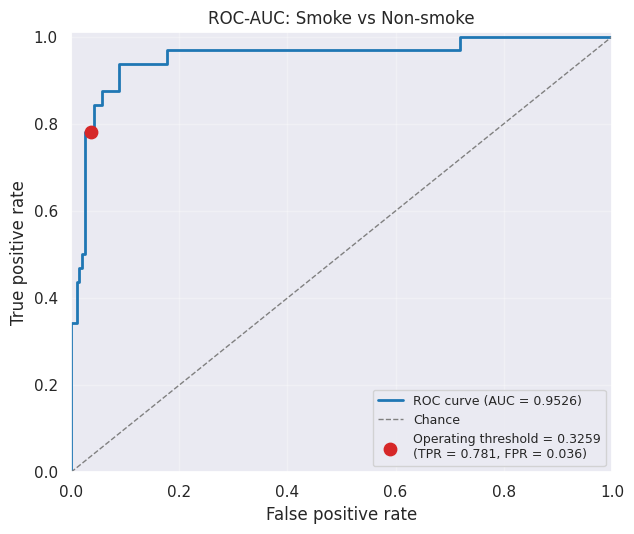

ROC-AUC: 0.9526 | AP: 0.8335 | threshold: 0.3259 | TPR: 0.7812 | FPR: 0.0365


In [ ]:
# ---------------------------------------------------------------------------
# 6. ROC curve for the smoke decision (held-out test).
# ---------------------------------------------------------------------------
m = SESSION_RESULTS['metrics']
fpr = SESSION_RESULTS['roc_fpr']
tpr = SESSION_RESULTS['roc_tpr']

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot(
    fpr, tpr, color='tab:blue', linewidth=2,
    label=f"ROC curve (AUC = {m['bin_roc_auc']:.4f})",
)
ax.plot(
    [0, 1], [0, 1], color='grey', linewidth=1, linestyle='--',
    label='Chance',
)
ax.scatter(
    [m['threshold_fpr']], [m['threshold_tpr']], s=80, color='tab:red',
    zorder=5,
    label=(
        f"Operating threshold = {m['threshold']:.4f}\n"
        f"(TPR = {m['threshold_tpr']:.3f}, "
        f"FPR = {m['threshold_fpr']:.3f})"
    ),
)
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.01)
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title(
    f'ROC-AUC: Smoke vs Non-smoke'
)
ax.legend(loc='lower right', fontsize=9)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(f"ROC-AUC: {m['bin_roc_auc']:.4f} | AP: {m['bin_ap']:.4f} | "
      f"threshold: {m['threshold']:.4f} | "
      f"TPR: {m['threshold_tpr']:.4f} | FPR: {m['threshold_fpr']:.4f}")


## 6. Probability calibration (Platt scaling) for weighted late fusion

Weighted late fusion combines the class-probability vectors of several models as `p_fused(c) = sum_m w_m * p_m(c)`. The fusion is only meaningful when every `p_m` is a calibrated posterior over the same class list. The seven-class head is trained with a 6x smoke class weight, label smoothing 0.05, and dropout, so its raw softmax scores are biased toward smoke and are not directly comparable with another model's output.

This section fits the standard multiclass extension of **Platt scaling** on the **frozen validation split only**:

1. Recover the pre-softmax logits `z` of the seven-class head.
2. For every class `k`, fit a one-vs-rest logistic calibration `sigmoid(A_k * z_k + B_k)` by minimising validation log-loss.
3. Renormalise the seven sigmoids into a probability vector.

A separate binary Platt calibrator is also fit on the smoke logit, for fusion stages that combine smoke-vs-non-smoke gates rather than full seven-class vectors.

The parameters are saved next to the checkpoint as `models/csi_resnet_lstm_7class.platt.json` (slopes, intercepts, class order, split hash, fit diagnostics). The late-fusion stage must load that file and apply the same transform instead of using the raw softmax. Test labels are used only to report calibration quality; they never fit the calibrator. Any fixed smoke threshold is specific to the score scale: re-derive the deployed threshold on **calibrated** validation scores with the same quantile policy; the raw-softmax threshold in Section 5 does not transfer.

**Fusion caveat.** Validation is used to fit the calibrator, so tune the fusion weights `w_m` on a different split (or with nested cross-validation); do not tune them on the calibration set. Probabilities are posteriors under the within-session split distribution, so cross-session deployment should refit the calibrator on held-out recording dates when such data exists. The class vector is now length 7; consumers of `predict_calibrated_proba` must expect the order `smoke, eat, drink, sit, stand, random, static`.


In [ ]:
# ---------------------------------------------------------------------------
# 6. Platt scaling for weighted late fusion.
#
# The seven-class softmax is trained with a 6x smoke class weight and label
# smoothing, so its raw scores are biased toward smoke and are not comparable
# with another model's probabilities. Weighted late fusion requires calibrated
# posteriors on the same class list:
#
#     p_fused(c) = sum_m w_m * p_m(c)
#
# Fit the standard multiclass extension of Platt scaling on the frozen
# validation split only:
#   1. Recover the pre-softmax logits of the activity head.
#   2. Fit one-vs-rest logistic calibration sigmoid(A_k * z_k + B_k) per class.
#   3. Renormalise the seven sigmoids into a probability vector.
#
# A second, binary Platt calibrator is fit on the smoke logit for fusion
# stages that combine binary smoke gates. Test labels are never used to fit
# either calibrator; the test split is reported for diagnostics only.
# ---------------------------------------------------------------------------
from scipy.optimize import minimize

PLATT_SCHEMA_VERSION = 2
PLATT_PATH = os.path.join(MODEL_DIR, f'{MODEL_BASENAME}.platt.json')
_SMOKE_IDX = SEVEN_CLASS_TO_IDX['smoke']

_required = (
    'ACTIVITY_MODEL', 'SESSION_DATA', 'SPLIT',
    'split_sha256', '_atomic_write_json',
)
_missing = [name for name in _required if name not in globals()]
if _missing:
    raise RuntimeError(
        f'Missing {_missing}. Run Sections 1-4 (data preparation and model '
        'training) before fitting the Platt calibrator.'
    )


def get_model_logits(model, X):
    """Return the exact pre-softmax logits of the seven-class head.

    The activity head is Dense(7, softmax) applied to the dense_features
    representation, so the logits are ``dense_features @ kernel + bias``.
    Applying softmax to these values must reproduce ``model.predict(X)``.
    """
    feature_model = models.Model(
        inputs=model.input,
        outputs=model.get_layer('dense_features').output,
    )
    features = feature_model.predict(X, verbose=0)
    kernel, bias = model.get_layer('activity').get_weights()
    return features @ kernel + bias


def _stable_sigmoid(z):
    return np.exp(-np.logaddexp(0.0, -z))


def _fit_platt_binary(scores, targets, l2=1e-6):
    """Fit sigmoid(A * score + B) by minimising binary log-loss.

    L-BFGS over the two parameters. The tiny L2 term on the slope keeps A
    finite if a class is nearly separable on the validation split.
    """
    scores = np.asarray(scores, dtype=np.float64)
    targets = np.asarray(targets, dtype=np.float64)
    if targets.size == 0 or targets.min() == targets.max():
        return 1.0, 0.0

    def objective(params):
        slope, intercept = params
        z = slope * scores + intercept
        nll = np.sum(np.logaddexp(0.0, z) - targets * z)
        prob = _stable_sigmoid(z)
        grad = np.array([
            float(np.dot(prob - targets, scores)) + l2 * slope,
            float(np.sum(prob - targets)),
        ])
        return nll + 0.5 * l2 * slope ** 2, grad

    result = minimize(
        objective, x0=np.array([1.0, 0.0]), jac=True, method='L-BFGS-B',
    )
    if not result.success:
        print(f'[platt] WARNING: binary fit did not converge: '
              f'{result.message}')
    return float(result.x[0]), float(result.x[1])


class PlattCalibrator:
    """One-vs-rest Platt scaling for a multiclass softmax model.

    ``transform`` applies ``sigmoid(A_k * z_k + B_k)`` per class and
    renormalises the seven outputs so they form a probability vector suitable
    for weighted late fusion.
    """

    def __init__(self, classes=SEVEN_CLASSES, slopes=None, intercepts=None):
        self.classes = list(classes)
        self.slopes = (
            None if slopes is None else np.asarray(slopes, dtype=np.float64)
        )
        self.intercepts = (
            None if intercepts is None
            else np.asarray(intercepts, dtype=np.float64)
        )

    def fit(self, logits, y_true):
        logits = np.asarray(logits, dtype=np.float64)
        y_true = np.asarray(y_true, dtype=int)
        if logits.shape[1] != len(self.classes):
            raise ValueError('Logit width does not match the class list.')
        slopes = np.empty(len(self.classes), dtype=np.float64)
        intercepts = np.empty(len(self.classes), dtype=np.float64)
        for class_idx in range(len(self.classes)):
            targets = (y_true == class_idx).astype(np.float64)
            slopes[class_idx], intercepts[class_idx] = _fit_platt_binary(
                logits[:, class_idx], targets
            )
        self.slopes = slopes
        self.intercepts = intercepts
        return self

    def transform(self, logits):
        if self.slopes is None or self.intercepts is None:
            raise RuntimeError('PlattCalibrator is not fitted.')
        logits = np.asarray(logits, dtype=np.float64)
        calibrated = _stable_sigmoid(
            logits * self.slopes[None, :] + self.intercepts[None, :]
        )
        totals = calibrated.sum(axis=1, keepdims=True)
        uniform = np.full_like(calibrated, 1.0 / calibrated.shape[1])
        return np.where(
            totals > 0.0, calibrated / np.maximum(totals, 1e-12), uniform
        )

    def predict_proba(self, model, X):
        """Calibrated seven-class probabilities for weighted late fusion."""
        return self.transform(get_model_logits(model, X))

    def to_dict(self):
        return {
            'classes': self.classes,
            'slope_A': [float(value) for value in self.slopes],
            'intercept_B': [float(value) for value in self.intercepts],
        }

    @classmethod
    def from_dict(cls, payload):
        if payload['classes'] != list(SEVEN_CLASSES):
            raise ValueError(
                'Saved Platt calibrator classes do not match the active '
                'class list.'
            )
        return cls(
            classes=payload['classes'],
            slopes=payload['slope_A'],
            intercepts=payload['intercept_B'],
        )


def load_platt_artifacts(path=PLATT_PATH):
    """Load the saved calibrators for the weighted-late-fusion stage."""
    with open(path, 'r', encoding='utf-8') as f:
        payload = json.load(f)
    if payload.get('schema_version') != PLATT_SCHEMA_VERSION:
        raise RuntimeError(
            'Saved Platt calibrator schema is stale; refit it.'
        )
    if payload.get('frozen_split_sha256') != split_sha256(SPLIT):
        raise RuntimeError(
            'Saved Platt calibrator belongs to a different frozen split; '
            'refit it.'
        )
    calibrator = PlattCalibrator.from_dict(payload['multiclass'])
    binary = payload['smoke_binary']
    return {
        'calibrator': calibrator,
        'smoke_binary': (
            float(binary['slope_A']), float(binary['intercept_B'])
        ),
        'payload': payload,
    }


def expected_calibration_error(y_true, probs, n_bins=15):
    """Top-label ECE with equal-width confidence bins."""
    confidence = probs.max(axis=1)
    correct = (probs.argmax(axis=1) == y_true).astype(np.float64)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for low, high in zip(edges[:-1], edges[1:]):
        in_bin = (confidence > low) & (confidence <= high)
        if in_bin.any():
            ece += float(in_bin.mean()) * abs(
                float(correct[in_bin].mean())
                - float(confidence[in_bin].mean())
            )
    return float(ece)


def calibration_metrics(y_true, probs):
    """Log-loss, Brier, top-label ECE, accuracy, and macro-F1."""
    y_true = np.asarray(y_true, dtype=int)
    probs = np.asarray(probs, dtype=np.float64)
    one_hot = np.eye(probs.shape[1])[y_true]
    picked = np.clip(probs[np.arange(len(y_true)), y_true], 1e-12, 1.0)
    pred = probs.argmax(axis=1)
    return {
        'n': int(len(y_true)),
        'log_loss': float(-np.mean(np.log(picked))),
        'brier': float(np.mean(np.sum((probs - one_hot) ** 2, axis=1))),
        'ece': expected_calibration_error(y_true, probs),
        'accuracy': float(accuracy_score(y_true, pred)),
        'macro_f1': float(f1_score(y_true, pred, average='macro')),
        'mean_confidence': float(probs.max(axis=1).mean()),
        'mean_smoke_prob': float(probs[:, _SMOKE_IDX].mean()),
    }


def binary_calibration_metrics(y_true_binary, scores):
    """Log-loss and Brier score for a binary probability score."""
    y_true_binary = np.asarray(y_true_binary, dtype=np.float64)
    probs = np.clip(np.asarray(scores, dtype=np.float64), 1e-12, 1.0 - 1e-12)
    return {
        'log_loss': float(-np.mean(
            y_true_binary * np.log(probs)
            + (1.0 - y_true_binary) * np.log(1.0 - probs)
        )),
        'brier': float(np.mean((probs - y_true_binary) ** 2)),
    }


# --- Fit on the frozen validation split only --------------------------------
VAL_X = SESSION_DATA['X_val'][SESSION_DATA['val_mask']]
TEST_X = SESSION_DATA['X_test'][SESSION_DATA['test_mask']]
VAL_Y = SESSION_DATA['y_val'][SESSION_DATA['val_mask']]
TEST_Y = SESSION_DATA['y_test'][SESSION_DATA['test_mask']]
VAL_LOGITS = get_model_logits(ACTIVITY_MODEL, VAL_X)
TEST_LOGITS = get_model_logits(ACTIVITY_MODEL, TEST_X)
VAL_RAW = ACTIVITY_MODEL.predict(VAL_X, verbose=0)
TEST_RAW = ACTIVITY_MODEL.predict(TEST_X, verbose=0)

_max_diff = float(np.max(np.abs(
    tf.nn.softmax(VAL_LOGITS, axis=1).numpy() - VAL_RAW
)))
print(f'[platt] logit/softmax consistency: max |softmax(logits) - '
      f'model.predict| = {_max_diff:.2e}')
if _max_diff > 1e-5:
    raise RuntimeError(
        'Recovered logits do not reproduce the model softmax; check the '
        'activity head before calibrating.'
    )

ACTIVITY_PLATT = PlattCalibrator(SEVEN_CLASSES).fit(VAL_LOGITS, VAL_Y)
SMOKE_PLATT = _fit_platt_binary(
    VAL_LOGITS[:, _SMOKE_IDX],
    (VAL_Y == _SMOKE_IDX).astype(np.float64),
)

VAL_CAL = ACTIVITY_PLATT.transform(VAL_LOGITS)
TEST_CAL = ACTIVITY_PLATT.transform(TEST_LOGITS)
VAL_SMOKE_CAL = _stable_sigmoid(
    SMOKE_PLATT[0] * VAL_LOGITS[:, _SMOKE_IDX] + SMOKE_PLATT[1]
)
TEST_SMOKE_CAL = _stable_sigmoid(
    SMOKE_PLATT[0] * TEST_LOGITS[:, _SMOKE_IDX] + SMOKE_PLATT[1]
)


def predict_calibrated_proba(model, X, calibrator=ACTIVITY_PLATT):
    """Calibrated seven-class probabilities for weighted late fusion."""
    return calibrator.predict_proba(model, X)


def predict_calibrated_smoke(model, X, params=SMOKE_PLATT):
    """Calibrated binary smoke probability for weighted late fusion."""
    logits = get_model_logits(model, X)
    return _stable_sigmoid(
        float(params[0]) * logits[:, _SMOKE_IDX] + float(params[1])
    )


# --- Diagnostics: validation fits, test only reports ------------------------
_platt_rows = []
for _split_name, _y_true, _raw, _cal in (
    ('validation', VAL_Y, VAL_RAW, VAL_CAL),
    ('test', TEST_Y, TEST_RAW, TEST_CAL),
):
    for _score_name, _probs in (
        ('raw softmax', _raw), ('platt multiclass', _cal)
    ):
        _platt_rows.append({
            'split': _split_name,
            'scores': _score_name,
            **calibration_metrics(_y_true, _probs),
        })
PLATT_DIAGNOSTICS = pd.DataFrame(_platt_rows).set_index(
    ['split', 'scores']
)
print('\nCalibration diagnostics (test is evaluation-only; never used to fit):')
display(PLATT_DIAGNOSTICS.round(4))

PLATT_PARAMS = pd.DataFrame({
    'slope_A': ACTIVITY_PLATT.slopes,
    'intercept_B': ACTIVITY_PLATT.intercepts,
    'val_positive_rate': [
        float((VAL_Y == class_idx).mean())
        for class_idx in range(len(SEVEN_CLASSES))
    ],
}, index=SEVEN_CLASSES)
print('\nPer-class one-vs-rest Platt parameters (fit on validation):')
display(PLATT_PARAMS.round(4))
print(f'Binary smoke Platt: A={SMOKE_PLATT[0]:.4f}, '
      f'B={SMOKE_PLATT[1]:.4f}')

_smoke_rows = []
for _split_name, _y_true, _raw_scores, _cal_scores in (
    ('validation', VAL_Y, VAL_RAW[:, _SMOKE_IDX], VAL_SMOKE_CAL),
    ('test', TEST_Y, TEST_RAW[:, _SMOKE_IDX], TEST_SMOKE_CAL),
):
    _binary_y = (_y_true == _SMOKE_IDX).astype(int)
    for _score_name, _scores in (
        ('raw P(smoke)', _raw_scores), ('platt smoke', _cal_scores)
    ):
        _smoke_rows.append({
            'split': _split_name,
            'scores': _score_name,
            **binary_calibration_metrics(_binary_y, _scores),
            'auc': float(roc_auc_score(_binary_y, _scores)),
            'ap': float(average_precision_score(_binary_y, _scores)),
        })
SMOKE_PLATT_DIAGNOSTICS = pd.DataFrame(_smoke_rows).set_index(
    ['split', 'scores']
)
print('\nBinary smoke calibration (dedicated Platt on the smoke logit):')
display(SMOKE_PLATT_DIAGNOSTICS.round(4))

# --- Persist the calibrator next to the checkpoint --------------------------
PLATT_PAYLOAD = {
    'schema_version': PLATT_SCHEMA_VERSION,
    'method': 'one_vs_rest_platt_softmax_normalized',
    'fit_split': 'validation',
    'test_usage': 'diagnostics only; never used to fit',
    'classes': list(SEVEN_CLASSES),
    'n_fit': int(len(VAL_Y)),
    'fit_class_counts': {
        name: int((VAL_Y == class_idx).sum())
        for class_idx, name in enumerate(SEVEN_CLASSES)
    },
    'logit_source': (
        'pre-softmax logits of the activity head '
        '(dense_features @ activity kernel + bias)'
    ),
    'multiclass': ACTIVITY_PLATT.to_dict(),
    'smoke_binary': {
        'class': 'smoke',
        'slope_A': float(SMOKE_PLATT[0]),
        'intercept_B': float(SMOKE_PLATT[1]),
        'note': 'sigmoid(A * z_smoke + B), no renormalisation',
    },
    'model_path': MODEL_PATH,
    'frozen_split_sha256': split_sha256(SPLIT),
    'created_at_utc': utc_now_iso(),
    'diagnostics': {
        'multiclass': _platt_rows,
        'smoke_binary': _smoke_rows,
    },
}
_atomic_write_json(PLATT_PATH, PLATT_PAYLOAD)
print(f'[platt] saved calibrator to {PLATT_PATH}')
print('[platt] weighted late fusion must use predict_calibrated_proba(...) '
      'or load_platt_artifacts(...), not the raw softmax.')


[platt] logit/softmax consistency: max |softmax(logits) - model.predict| = 1.79e-07

Calibration diagnostics (test is evaluation-only; never used to fit):


n  log_loss   brier     ece  accuracy  \
split      scores                                                      
validation raw softmax       224    0.4364  0.1994  0.0584    0.8884   
           platt multiclass  224    0.4094  0.1991  0.0392    0.8750   
test       raw softmax       224    0.4506  0.2130  0.0455    0.8616   
           platt multiclass  224    0.4434  0.1992  0.0644    0.8571   

                             macro_f1  mean_confidence  mean_smoke_prob  
split      scores                                                        
validation raw softmax         0.8906           0.8994           0.1501  
           platt multiclass    0.8754           0.8648           0.1545  
test       raw softmax         0.8609           0.8978           0.1364  
           platt multiclass    0.8558           0.8688           0.1431


Per-class one-vs-rest Platt parameters (fit on validation):


,slope_A,intercept_B,val_positive_rate
smoke,1.4659,-3.7314,0.1429
eat,1.7657,-3.9899,0.1429
drink,1.2233,-3.7329,0.1429
sit,1.8122,-5.2727,0.1429
stand,1.8354,-4.0732,0.1429
random,1.0722,-3.2497,0.1429
static,2.2546,-3.1483,0.1429


Binary smoke Platt: A=1.4659, B=-3.7314

Binary smoke calibration (dedicated Platt on the smoke logit):


log_loss   brier     auc      ap
split      scores                                        
validation raw P(smoke)    0.1217  0.0315  0.9780  0.9010
           platt smoke     0.1179  0.0303  0.9673  0.8816
test       raw P(smoke)    0.1872  0.0503  0.9526  0.8335
           platt smoke     0.1847  0.0490  0.9328  0.8104

[platt] saved calibrator to /content/drive/MyDrive/CSI_TRAINING/models/csi_resnet_lstm_7class.platt.json
[platt] weighted late fusion must use predict_calibrated_proba(...) or load_platt_artifacts(...), not the raw softmax.


## 7. Cross-environment generalization — unseen environment (2026-10-31)

This section evaluates the trained seven-class model on CSI collected in a
**different environment** on **31 October 2026**. The data was not part of the
frozen date-stratified split and is never used for training, threshold tuning,
or calibration.

**Protocol**

- Annotations are read from `timestamps/TEST_DATA`; the matching packet parquet
  files come from the same `csi_data` tree as the training captures (matched by
  packet timestamps, not filenames).
- Every unseen segment is denoised with the exact training pipeline: active
  subcarriers → Hampel → 420-packet resampling → 5 Hz Butterworth → Gaussian σ=2.
- Backgrounds: if the Oct 31 data contains `static` segments, each window is
  background-subtracted with the nearest-in-time static window from the **new
  environment**. If it does not, the mean training static background is used and
  the result is marked as a fallback.
- The frozen-split loaders are deliberately bypassed: they reject segment keys
  that are not in the training manifest.

**Metrics**

- Multi-class: accuracy, balanced accuracy, macro/weighted F1, per-class
  precision/recall/F1/support, and count + row-normalized confusion matrices.
- **Each confusion matrix is a standalone figure in its own cell** (multi-class
  counts, multi-class row-normalized, binary counts, binary row-normalized) so
  it can be exported directly into a paper. Figures use `dpi=200`; remove the
  `ax.set_title(...)` call if the venue requires title-free figures.
- Binary smoke vs non-smoke: the primary row uses the notebook's deployed
  `session_quantile` threshold policy (in-domain validation prevalence applied to
  the unseen score distribution). The absolute in-domain validation threshold is
  reported as a reference. AP, ROC-AUC, and the PR curve are threshold-free.
- No threshold is tuned on unseen labels. `static` is a negative in the binary
  view, consistent with Section 5.
- **Class balance differs between the two evaluations.** The in-domain held-out
  test is balanced at 32 windows/class (224 total, 1/7 smoke). The unseen set is
  50 windows/class (350 total: 50 smoke, 300 non-smoke), so binary *accuracy* is
  dominated by the negative class and is not directly comparable across rows.
  Use balanced accuracy, per-class recall, AP, and ROC-AUC for the
  cross-environment comparison. The deployed threshold value itself also adapts
  to each domain's score distribution and is not comparable in absolute terms.
- Diagnostics compare in-domain and unseen confidence/ECE and show where the
  predicted class distribution shifts.

A large drop relative to the in-domain held-out test is the expected outcome if
the environment change dominates the CSI features; compare the per-class table
to see whether errors concentrate in specific activities.


In [ ]:
# ---------------------------------------------------------------------------
# 7a. Load the 2026-10-31 unseen-environment annotations and CSI packets.
#
# The frozen-split loaders are deliberately bypassed: they reject segment keys
# that are not in the training manifest. Packet matching is by timestamp, so
# the parquet files can live in the same csi_data tree as the training captures.
# ---------------------------------------------------------------------------
if 'ACTIVITY_MODEL' not in globals():
    if 'MODEL_PATH' in globals() and os.path.exists(MODEL_PATH):
        ACTIVITY_MODEL = tf.keras.models.load_model(MODEL_PATH, compile=False)
        print(f'[unseen] loaded trained model from {MODEL_PATH}')
    else:
        raise RuntimeError(
            'ACTIVITY_MODEL is not in memory and MODEL_PATH could not be '
            'loaded. Run the model training section first.'
        )

_REQUIRED_GLOBALS = [
    'load_timestamp_table', 'extract_segments', '_load_csi_parquet_files',
    'preprocess_csi_data', 'select_nearest_static_backgrounds',
    'MAP8_TO_7', 'SEVEN_CLASSES', 'CLASSES', 'STATIC_LABEL_INDEX',
    'ACTIVE_SUBCARRIERS', 'CSI_DIR', 'TIMESTAMP_DIR', 'SESSION_DATA',
]
_missing = [name for name in _REQUIRED_GLOBALS if name not in globals()]
if _missing:
    raise RuntimeError(
        'The unseen-environment section needs the notebook pipeline loaded '
        f'first; missing globals: {_missing}. Run Sections 1-5 (through the '
        'in-domain evaluation), then rerun this cell.'
    )

UNSEEN_ANNOTATION_DIR = os.path.join(TIMESTAMP_DIR, 'TEST_DATA')
UNSEEN_CSI_DIR = CSI_DIR
UNSEEN_SPLIT_NAME = 'unseen environment 2026-10-31'
SEVEN_CLASS_TO_IDX = {name: index for index, name in enumerate(SEVEN_CLASSES)}
_UNSEEN_SMOKE_IDX = SEVEN_CLASS_TO_IDX['smoke']

if not os.path.isdir(UNSEEN_ANNOTATION_DIR):
    raise FileNotFoundError(
        f'Unseen annotation directory not found: {UNSEEN_ANNOTATION_DIR!r}. '
        'Expected the Oct 31 annotation CSVs under timestamps/TEST_DATA.'
    )


def _load_unseen_timestamp_table(root):
    """Load annotation CSVs under root, mirroring load_timestamp_table.

    Recurses only when no CSVs exist at the top level, so the usual flat layout
    uses the notebook loader unchanged. Nested layouts keep relative source
    paths so START/STOP pairing can never cross files.
    """
    if sorted(glob.glob(os.path.join(root, '*.csv'))):
        return load_timestamp_table(root)
    nested = sorted(glob.glob(os.path.join(root, '**', '*.csv'), recursive=True))
    if not nested:
        raise FileNotFoundError(f'No timestamp CSV files found under {root!r}.')
    frames = []
    for path in nested:
        frame = pd.read_csv(path)
        frame['source_file'] = os.path.relpath(path, root)
        frames.append(frame)
    return (
        pd.concat(frames, ignore_index=True)
        .sort_values('Time', kind='stable')
        .reset_index(drop=True)
    )


UNSEEN_TIMESTAMP_DF = _load_unseen_timestamp_table(UNSEEN_ANNOTATION_DIR)
UNSEEN_SEGMENTS = extract_segments(UNSEEN_TIMESTAMP_DF)
if len(UNSEEN_SEGMENTS) == 0:
    raise RuntimeError(
        f'No labelled START/STOP segments were parsed from '
        f'{UNSEEN_ANNOTATION_DIR!r}.'
    )

_UNSEEN_LABEL_NAMES = {index: name for index, name in enumerate(CLASSES)}
_UNSEEN_LABEL_COUNTS = (
    UNSEEN_SEGMENTS['label'].map(_UNSEEN_LABEL_NAMES).value_counts()
)
print(f'Unseen annotation directory: {UNSEEN_ANNOTATION_DIR}')
print(f'Unseen timestamp rows: {len(UNSEEN_TIMESTAMP_DF)}; '
      f'segments: {len(UNSEEN_SEGMENTS)}; '
      f'session dates: {sorted(UNSEEN_SEGMENTS["session_key"].unique())}')
print('Unseen segments per annotation label:')
print(_UNSEEN_LABEL_COUNTS.to_string())

_UNSEEN_CSI_FILES = sorted(glob.glob(
    os.path.join(UNSEEN_CSI_DIR, '**', '*.parquet'), recursive=True
))
if not _UNSEEN_CSI_FILES:
    _UNSEEN_CSI_FILES = sorted(glob.glob('/content/*.parquet'))
if not _UNSEEN_CSI_FILES:
    raise FileNotFoundError(
        'No CSI parquet files found under '
        f'{UNSEEN_CSI_DIR!r} or /content/*.parquet.'
    )

print(f'\nUnseen CSI parquet files: {len(_UNSEEN_CSI_FILES)} (searched '
      f'{UNSEEN_CSI_DIR})')
UNSEEN_MASTER_CSI = _load_csi_parquet_files(_UNSEEN_CSI_FILES)
UNSEEN_MASTER_CSI['timestamp_real'] = (
    UNSEEN_MASTER_CSI['time'].astype(np.int64).to_numpy(dtype=np.float64) / 1e9
)
UNSEEN_MASTER_CSI = UNSEEN_MASTER_CSI.sort_values(
    'timestamp_real', kind='stable'
).reset_index(drop=True)
UNSEEN_PACKET_TIMES = UNSEEN_MASTER_CSI['timestamp_real'].to_numpy()
print(f'Unseen CSI packets: {len(UNSEEN_MASTER_CSI)}; packet time span: '
      f'{UNSEEN_PACKET_TIMES[0]:.3f} to {UNSEEN_PACKET_TIMES[-1]:.3f}')
print(f'Unseen segment time span: {UNSEEN_SEGMENTS["start"].min():.3f} to '
      f'{UNSEEN_SEGMENTS["stop"].max():.3f}')


[segments] timestamp rows: START=350 STOP=350 paired=350 unique=350 sessions=1 unmatched_START=0 unmatched_STOP=0
Unseen annotation directory: /content/drive/MyDrive/CSI_TRAINING/timestamps/TEST_DATA
Unseen timestamp rows: 700; segments: 350; session dates: ['2026-10-31']
Unseen segments per annotation label:
label
static     50
random     50
drink      50
eat        50
sit        50
stand      50
smoking    50

Unseen CSI parquet files: 6 (searched /content/drive/MyDrive/CSI_TRAINING/csi_data)
Loading: csi_data_10-12-2026.parquet
Loading: csi_data_10-13-2026.parquet
Loading: csi_data_10-15-2026.parquet
Loading: csi_data_10-16-1016.parquet
Loading: csi_data_10-23-2026.parquet
Loading: csi_data_10-31-2026.parquet
Unseen CSI packets: 1773989; packet time span: 1791778874.091 to 1793441295.437
Unseen segment time span: 1793434652.695 to 1793436807.412


In [ ]:
# ---------------------------------------------------------------------------
# 7b. Preprocess the unseen segments with the exact training pipeline and
# subtract a static background calibrated in the new environment when possible.
# ---------------------------------------------------------------------------
UNSEEN_TARGET_PACKETS = int(ACTIVITY_MODEL.input_shape[1])
print(f'Unseen target packets per window: {UNSEEN_TARGET_PACKETS}')

_unseen_windows = []
_unseen_labels = []
_unseen_sessions = []
_unseen_keys = []
_unseen_starts = []
_unseen_stops = []
_unseen_fs = []
_unseen_skipped = []

for segment_number, row in enumerate(
    UNSEEN_SEGMENTS.itertuples(index=False), start=1
):
    if segment_number % 20 == 0 or segment_number == len(UNSEEN_SEGMENTS):
        clear_output(wait=True)
        print(f'Preprocessing unseen segment {segment_number}/'
              f'{len(UNSEEN_SEGMENTS)}...')
    start_idx = np.searchsorted(
        UNSEEN_PACKET_TIMES, float(row.start), side='left'
    )
    stop_idx = np.searchsorted(
        UNSEEN_PACKET_TIMES, float(row.stop), side='right'
    )
    segment_df = UNSEEN_MASTER_CSI.iloc[start_idx:stop_idx]
    if len(segment_df) <= 10:
        _unseen_skipped.append(
            (row.session_key, row.segment_key, 'too few packets')
        )
        continue
    try:
        window, effective_fs = preprocess_csi_data(
            segment_df, ACTIVE_SUBCARRIERS,
            target_packets=UNSEEN_TARGET_PACKETS, return_fs=True,
        )
    except Exception as exc:
        _unseen_skipped.append(
            (row.session_key, row.segment_key, str(exc))
        )
        continue
    _unseen_windows.append(window)
    _unseen_labels.append(int(row.label))
    _unseen_sessions.append(row.session_key)
    _unseen_keys.append(row.segment_key)
    _unseen_starts.append(float(row.start))
    _unseen_stops.append(float(row.stop))
    _unseen_fs.append(effective_fs)

if _unseen_skipped:
    print(f'[unseen] WARNING: {len(_unseen_skipped)} segment(s) produced no '
          'window.')
    for _session_key, _segment_key, _reason in _unseen_skipped[:10]:
        print(f'  {_session_key}:{_segment_key} ({_reason})')
if not _unseen_windows:
    raise RuntimeError(
        'No unseen windows were produced. Check that the parquet packets '
        'cover the annotation timestamps and that the capture clocks agree.'
    )

X_UNSEEN = np.asarray(_unseen_windows, dtype=np.float32)
y_unseen8 = np.asarray(_unseen_labels, dtype=int)
unseen_sessions = np.asarray(_unseen_sessions, dtype=object)
unseen_keys = np.asarray(_unseen_keys, dtype=object)
unseen_starts = np.asarray(_unseen_starts, dtype=np.float64)
unseen_stops = np.asarray(_unseen_stops, dtype=np.float64)
unseen_fs = np.asarray(_unseen_fs, dtype=np.float64)
y_unseen7 = MAP8_TO_7[y_unseen8]
if (y_unseen7 < 0).any() or (y_unseen7 >= len(SEVEN_CLASSES)).any():
    raise RuntimeError('Unseen seven-class label mapping produced an invalid id.')

_unseen_static_mask = y_unseen8 == STATIC_LABEL_INDEX
if _unseen_static_mask.any():
    UNSEEN_BACKGROUNDS, UNSEEN_BACKGROUND_TABLE = (
        select_nearest_static_backgrounds(
            unseen_starts, unseen_stops, unseen_sessions, unseen_keys,
            np.full(len(unseen_keys), 'unseen', dtype=object),
            X_UNSEEN[_unseen_static_mask],
            unseen_starts[_unseen_static_mask],
            unseen_stops[_unseen_static_mask],
            unseen_sessions[_unseen_static_mask],
            unseen_keys[_unseen_static_mask],
        )
    )
    UNSEEN_BACKGROUND_MODE = 'new-environment nearest static'
else:
    if 'X_STATIC' not in globals() or len(X_STATIC) == 0:
        raise RuntimeError(
            'The unseen data has no static segments and the training static '
            'pool is unavailable. Run the data-preparation section first.'
        )
    _fallback_background = X_STATIC.mean(axis=(0, 1)).astype(np.float32)
    UNSEEN_BACKGROUNDS = np.broadcast_to(
        _fallback_background,
        (len(X_UNSEEN),) + _fallback_background.shape,
    ).copy()
    UNSEEN_BACKGROUND_TABLE = None
    UNSEEN_BACKGROUND_MODE = 'training static mean (fallback)'
    print('[unseen] WARNING: no static segments in the unseen data; using the '
          'mean training static background. Results are not calibrated to the '
          'new environment.')

X_UNSEEN_BG = (
    X_UNSEEN - UNSEEN_BACKGROUNDS[:, None, :]
).astype(np.float32, copy=False)

_expected_input = (UNSEEN_TARGET_PACKETS, len(ACTIVE_SUBCARRIERS))
if tuple(ACTIVITY_MODEL.input_shape[1:]) != _expected_input:
    raise RuntimeError(
        f'Model expects {ACTIVITY_MODEL.input_shape[1:]}, but the unseen '
        f'pipeline produced {_expected_input}.'
    )

print(f'\nUnseen windows: {X_UNSEEN_BG.shape}; background: '
      f'{UNSEEN_BACKGROUND_MODE}')
if UNSEEN_BACKGROUND_TABLE is not None:
    print('  background tier counts:',
          UNSEEN_BACKGROUND_TABLE['tier'].value_counts().to_dict())
    _unseen_gaps = UNSEEN_BACKGROUND_TABLE['gap_s'].to_numpy(dtype=np.float64)
    print(f'  background gap seconds: median={np.median(_unseen_gaps):.1f}, '
          f'p90={np.percentile(_unseen_gaps, 90):.1f}, '
          f'max={_unseen_gaps.max():.1f}')
print('Unseen seven-class counts:')
for _class_index, _class_name in enumerate(SEVEN_CLASSES):
    print(f'  {_class_name}: {int((y_unseen7 == _class_index).sum())}')
print(f'Unseen sessions: {sorted(set(unseen_sessions))}; '
      f'effective fs: median={np.median(unseen_fs):.1f} Hz')


Preprocessing unseen segment 350/350...

Unseen windows: (350, 420, 52); background: new-environment nearest static
  background tier counts: {'date': 350}
  background gap seconds: median=873.0, p90=1673.0, max=1901.2
Unseen seven-class counts:
  smoke: 50
  eat: 50
  drink: 50
  sit: 50
  stand: 50
  random: 50
  static: 50
Unseen sessions: ['2026-10-31']; effective fs: median=111.8 Hz


In [ ]:
# ---------------------------------------------------------------------------
# 7c. Predict the unseen-environment windows and report multi-class metrics.
# The existing evaluator is reused unchanged: its "validation" side is the
# in-domain validation split (threshold source only) and its "test" side is the
# unseen environment.
# ---------------------------------------------------------------------------
if 'SESSION_RESULTS' not in globals() or 'evaluate_activity_model' not in globals():
    raise RuntimeError(
        'The in-domain evaluation section must run before the unseen '
        'comparison. Run through Section 5 (cells up to the ROC curve).'
    )

_binary_unseen = (y_unseen7 == _UNSEEN_SMOKE_IDX).astype(int)
if _binary_unseen.min() == _binary_unseen.max():
    raise RuntimeError(
        'The unseen data contains only one binary class; smoke ROC/AP and the '
        'binary confusion matrix are undefined.'
    )

UNSEEN_EVAL_DATA = {
    'X_val': SESSION_DATA['X_val'],
    'y_val': SESSION_DATA['y_val'],
    'val_mask': np.ones(len(SESSION_DATA['y_val']), dtype=bool),
    'X_test': X_UNSEEN_BG,
    'y_test': y_unseen7,
    'test_mask': np.ones(len(y_unseen7), dtype=bool),
}
UNSEEN_RESULTS = evaluate_activity_model(
    UNSEEN_SPLIT_NAME, ACTIVITY_MODEL, UNSEEN_EVAL_DATA
)
UNSEEN_PROB = ACTIVITY_MODEL.predict(X_UNSEEN_BG, verbose=0)

UNSEEN_MULTICLASS_RESULTS = pd.DataFrame([{
    'evaluation': UNSEEN_SPLIT_NAME,
    'windows': int(len(y_unseen7)),
    'accuracy': UNSEEN_RESULTS['metrics']['mc_accuracy'],
    'balanced accuracy': UNSEEN_RESULTS['metrics']['mc_balanced_accuracy'],
    'macro F1': UNSEEN_RESULTS['metrics']['mc_macro_f1'],
    'weighted F1': UNSEEN_RESULTS['metrics']['mc_weighted_f1'],
    'background': UNSEEN_BACKGROUND_MODE,
}]).set_index('evaluation')
print('\nUnseen-environment seven-class results (argmax):')
display(UNSEEN_MULTICLASS_RESULTS.round(4))

UNSEEN_PER_CLASS_RESULTS = UNSEEN_RESULTS['per_class'].copy()
UNSEEN_PER_CLASS_RESULTS.index.name = 'class'
print('Per-class results (argmax, unseen environment):')
display(UNSEEN_PER_CLASS_RESULTS.round(4))

UNSEEN_PER_CLASS_COMPARISON = pd.DataFrame({
    'in-domain test F1': SESSION_RESULTS['per_class']['f1'],
    'unseen env F1': UNSEEN_RESULTS['per_class']['f1'],
    'F1 drop': (
        SESSION_RESULTS['per_class']['f1']
        - UNSEEN_RESULTS['per_class']['f1']
    ),
    'in-domain test recall': SESSION_RESULTS['per_class']['recall'],
    'unseen env recall': UNSEEN_RESULTS['per_class']['recall'],
    'recall drop': (
        SESSION_RESULTS['per_class']['recall']
        - UNSEEN_RESULTS['per_class']['recall']
    ),
    'unseen support': UNSEEN_RESULTS['per_class']['support'],
}).sort_values('F1 drop', ascending=False)
print('Per-class change from in-domain held-out test to unseen environment:')
display(UNSEEN_PER_CLASS_COMPARISON.round(4))


def _summary_row(name, results):
    metrics = results['metrics']
    return {
        'evaluation': name,
        'windows': metrics['n_test'],
        'accuracy': metrics['mc_accuracy'],
        'balanced accuracy': metrics['mc_balanced_accuracy'],
        'macro F1': metrics['mc_macro_f1'],
        'weighted F1': metrics['mc_weighted_f1'],
        'smoke AP': metrics['bin_ap'],
        'smoke ROC-AUC': metrics['bin_roc_auc'],
        'smoke precision': metrics['bin_precision'],
        'smoke recall': metrics['bin_recall'],
        'smoke F1': metrics['bin_f1'],
    }


UNSEEN_SUMMARY_COMPARISON = pd.DataFrame([
    _summary_row('in-domain held-out test', SESSION_RESULTS),
    _summary_row(UNSEEN_SPLIT_NAME, UNSEEN_RESULTS),
]).set_index('evaluation')
print('In-domain vs unseen-environment summary:')
display(UNSEEN_SUMMARY_COMPARISON.round(4))


[unseen environment 2026-10-31] test=350 windows; policy=session_quantile; test threshold=0.8446 (val threshold=0.2363); seven-class macro-F1=0.2048; smoke P=0.5200 R=0.5200 F1=0.5200 AP=0.5601 ROC-AUC=0.8160

Unseen-environment seven-class results (argmax):


,windows,accuracy,balanced accuracy,macro F1,weighted F1,background
evaluation,,,,,,
unseen environment 2026-10-31,350,0.3057,0.3057,0.2048,0.2048,new-environment nearest static


Per-class results (argmax, unseen environment):


,precision,recall,f1,support
class,,,,
smoke,0.4353,0.74,0.5481,50
eat,0.0000,0.00,0.0000,50
drink,0.0000,0.00,0.0000,50
sit,0.0000,0.00,0.0000,50
stand,0.0000,0.00,0.0000,50
random,0.1860,0.48,0.2682,50
static,0.4646,0.92,0.6174,50


Per-class change from in-domain held-out test to unseen environment:


,in-domain test F1,unseen env F1,F1 drop,in-domain test recall,unseen env recall,recall drop,unseen support
stand,1.0000,0.0000,1.0000,1.0000,0.00,1.0000,50
sit,0.9538,0.0000,0.9538,0.9688,0.00,0.9688,50
eat,0.8657,0.0000,0.8657,0.9062,0.00,0.9062,50
drink,0.6885,0.0000,0.6885,0.6562,0.00,0.6562,50
random,0.7761,0.2682,0.5080,0.8125,0.48,0.3325,50
static,0.9355,0.6174,0.3180,0.9062,0.92,-0.0138,50
smoke,0.8065,0.5481,0.2583,0.7812,0.74,0.0413,50


In-domain vs unseen-environment summary:


,windows,accuracy,balanced accuracy,macro F1,weighted F1,smoke AP,smoke ROC-AUC,smoke precision,smoke recall,smoke F1
evaluation,,,,,,,,,,
in-domain held-out test,224,0.8616,0.8616,0.8609,0.8609,0.8335,0.9526,0.7812,0.7812,0.7812
unseen environment 2026-10-31,350,0.3057,0.3057,0.2048,0.2048,0.5601,0.8160,0.5200,0.5200,0.5200


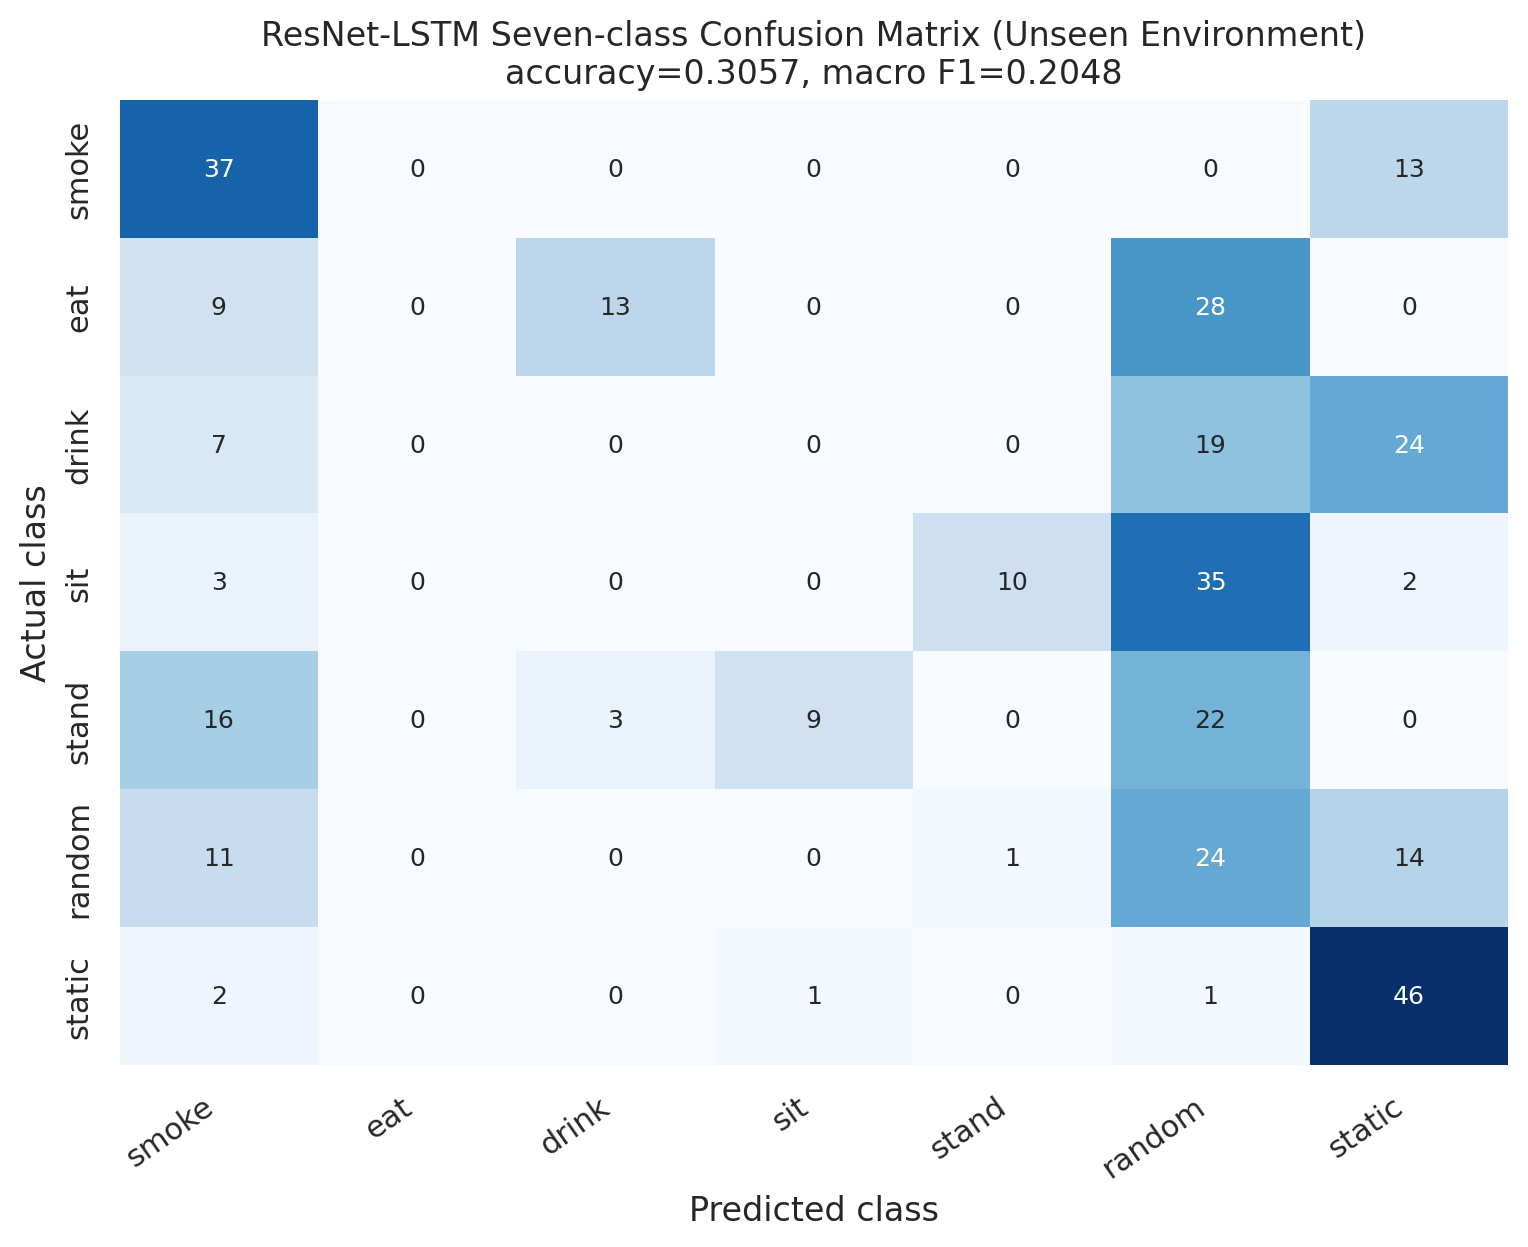

In [ ]:
# ---------------------------------------------------------------------------
# 7d. Seven-class confusion matrix for the unseen environment — raw counts.
# Standalone figure sized for direct reuse in a paper.
# ---------------------------------------------------------------------------
UNSEEN_MC_CM = confusion_matrix(
    y_unseen7, UNSEEN_RESULTS['y_pred_mc'],
    labels=np.arange(len(SEVEN_CLASSES)),
)
_unseen_metrics = UNSEEN_RESULTS['metrics']

fig, ax = plt.subplots(figsize=(7.8, 6.4), dpi=200)
sns.heatmap(
    UNSEEN_MC_CM, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=SEVEN_CLASSES, yticklabels=SEVEN_CLASSES, ax=ax,
    annot_kws={'fontsize': 9},
)
plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
ax.set_xlabel('Predicted class')
ax.set_ylabel('Actual class')
ax.set_title(
    'ResNet-LSTM Seven-class Confusion Matrix (Unseen Environment)\n'
    f'accuracy={_unseen_metrics["mc_accuracy"]:.4f}, '
    f'macro F1={_unseen_metrics["mc_macro_f1"]:.4f}'
)
fig.tight_layout()
plt.show()


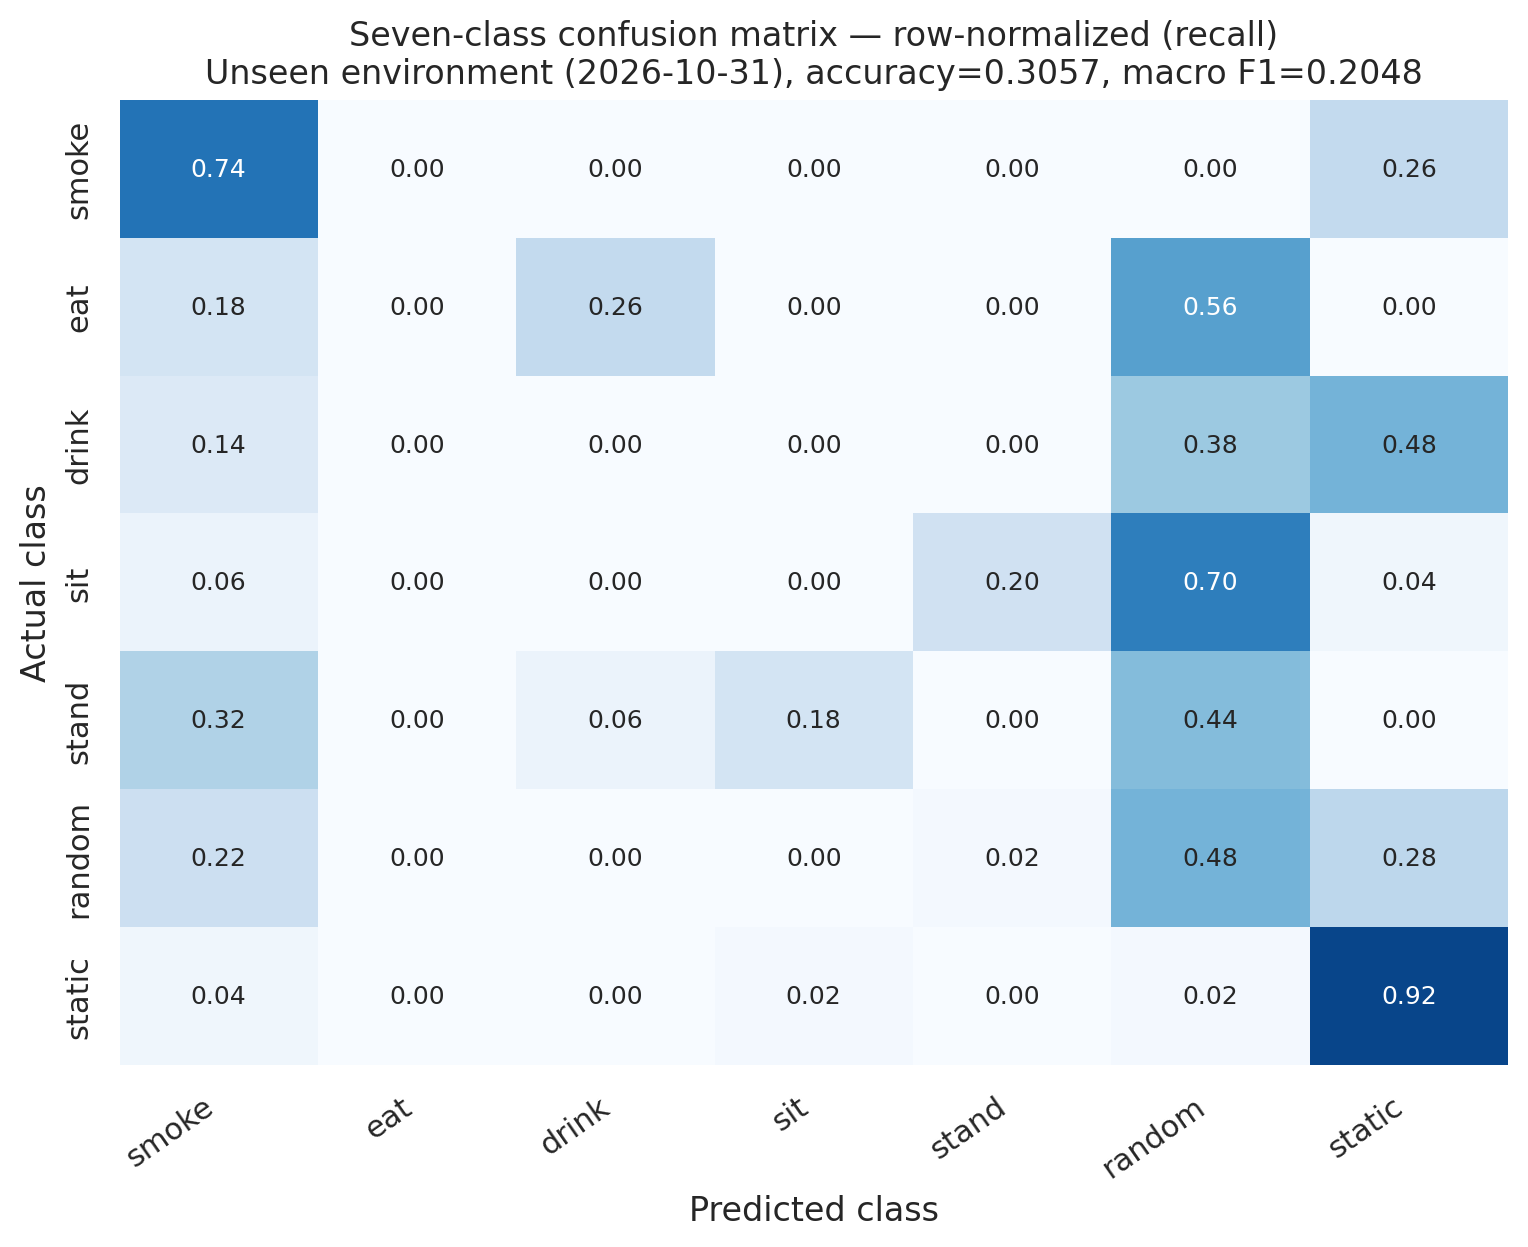

In [ ]:
# ---------------------------------------------------------------------------
# 7d. Seven-class confusion matrix for the unseen environment — row-normalized.
# Each row sums to 1, so the diagonal is per-class recall. Standalone figure.
# ---------------------------------------------------------------------------
UNSEEN_MC_CM_NORM = confusion_matrix(
    y_unseen7, UNSEEN_RESULTS['y_pred_mc'],
    labels=np.arange(len(SEVEN_CLASSES)), normalize='true',
)
_unseen_metrics = UNSEEN_RESULTS['metrics']

fig, ax = plt.subplots(figsize=(7.8, 6.4), dpi=200)
sns.heatmap(
    UNSEEN_MC_CM_NORM, annot=True, fmt='.2f', cmap='Blues', cbar=False,
    vmin=0.0, vmax=1.0, xticklabels=SEVEN_CLASSES,
    yticklabels=SEVEN_CLASSES, ax=ax, annot_kws={'fontsize': 9},
)
plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
ax.set_xlabel('Predicted class')
ax.set_ylabel('Actual class')
ax.set_title(
    'Seven-class confusion matrix — row-normalized (recall)\n'
    'Unseen environment (2026-10-31), '
    f'accuracy={_unseen_metrics["mc_accuracy"]:.4f}, '
    f'macro F1={_unseen_metrics["mc_macro_f1"]:.4f}'
)
fig.tight_layout()
plt.show()


In [ ]:
# ---------------------------------------------------------------------------
# 7e. Binary smoke vs non-smoke metrics for the unseen environment. static is a
# negative, consistent with Section 5. No threshold is tuned on unseen labels.
# Counts and row-normalized confusion matrices are in the next two cells.
# ---------------------------------------------------------------------------
def _binary_results_row(name, results):
    metrics = results['metrics']
    return {
        'evaluation': name,
        'windows': metrics['n_test'],
        'threshold policy': metrics['threshold_policy'],
        'threshold': metrics['threshold'],
        'precision': metrics['bin_precision'],
        'recall': metrics['bin_recall'],
        'F1': metrics['bin_f1'],
        'AP': metrics['bin_ap'],
        'ROC-AUC': metrics['bin_roc_auc'],
        'accuracy': metrics['bin_accuracy'],
        'balanced accuracy': metrics['bin_balanced_accuracy'],
        'TP': metrics['tp'],
        'FP': metrics['fp'],
        'FN': metrics['fn'],
        'TN': metrics['tn'],
        'P @ val threshold': metrics['bin_precision_at_val_threshold'],
        'R @ val threshold': metrics['bin_recall_at_val_threshold'],
        'F1 @ val threshold': metrics['bin_f1_at_val_threshold'],
    }


UNSEEN_BINARY_RESULTS = pd.DataFrame([
    _binary_results_row('in-domain held-out test', SESSION_RESULTS),
    _binary_results_row(UNSEEN_SPLIT_NAME, UNSEEN_RESULTS),
]).set_index('evaluation')
print('Smoke vs non-smoke results (deployed session-quantile threshold):')
display(UNSEEN_BINARY_RESULTS.round(4))


Smoke vs non-smoke results (deployed session-quantile threshold):


,windows,threshold policy,threshold,precision,recall,F1,AP,ROC-AUC,accuracy,balanced accuracy,TP,FP,FN,TN,P @ val threshold,R @ val threshold,F1 @ val threshold
evaluation,,,,,,,,,,,,,,,,,
in-domain held-out test,224,session_quantile,0.3259,0.7812,0.7812,0.7812,0.8335,0.9526,0.9375,0.8724,25,7,7,185,0.7714,0.8438,0.8060
unseen environment 2026-10-31,350,session_quantile,0.8446,0.5200,0.5200,0.5200,0.5601,0.8160,0.8629,0.7200,26,24,24,276,0.3838,0.7600,0.5101


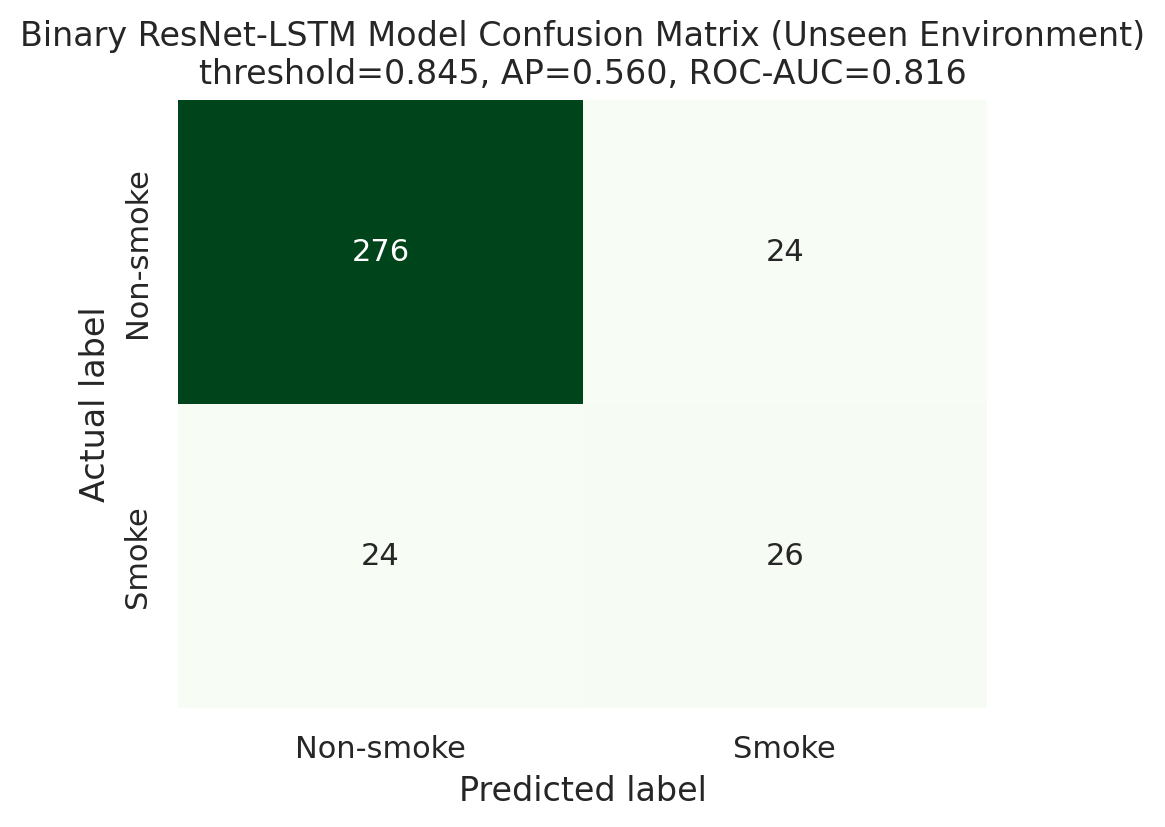

In [ ]:
# ---------------------------------------------------------------------------
# 7e. Smoke vs non-smoke confusion matrix for the unseen environment — raw
# counts. Standalone figure sized for direct reuse in a paper.
# ---------------------------------------------------------------------------
UNSEEN_BINARY_CM = confusion_matrix(
    UNSEEN_RESULTS['y_binary'], UNSEEN_RESULTS['y_pred_bin'], labels=[0, 1]
)
_unseen_binary_metrics = UNSEEN_RESULTS['metrics']

fig, ax = plt.subplots(figsize=(4.9, 4.3), dpi=200)
sns.heatmap(
    UNSEEN_BINARY_CM, annot=True, fmt='d', cmap='Greens', cbar=False,
    xticklabels=['Non-smoke', 'Smoke'], yticklabels=['Non-smoke', 'Smoke'],
    ax=ax, annot_kws={'fontsize': 11},
)
ax.set_xlabel('Predicted label')
ax.set_ylabel('Actual label')
ax.set_title(
    'Binary ResNet-LSTM Model Confusion Matrix (Unseen Environment)\n'
    f'threshold={_unseen_binary_metrics["threshold"]:.3f}, '
    f'AP={_unseen_binary_metrics["bin_ap"]:.3f}, '
    f'ROC-AUC={_unseen_binary_metrics["bin_roc_auc"]:.3f}'
)
fig.tight_layout()
plt.show()


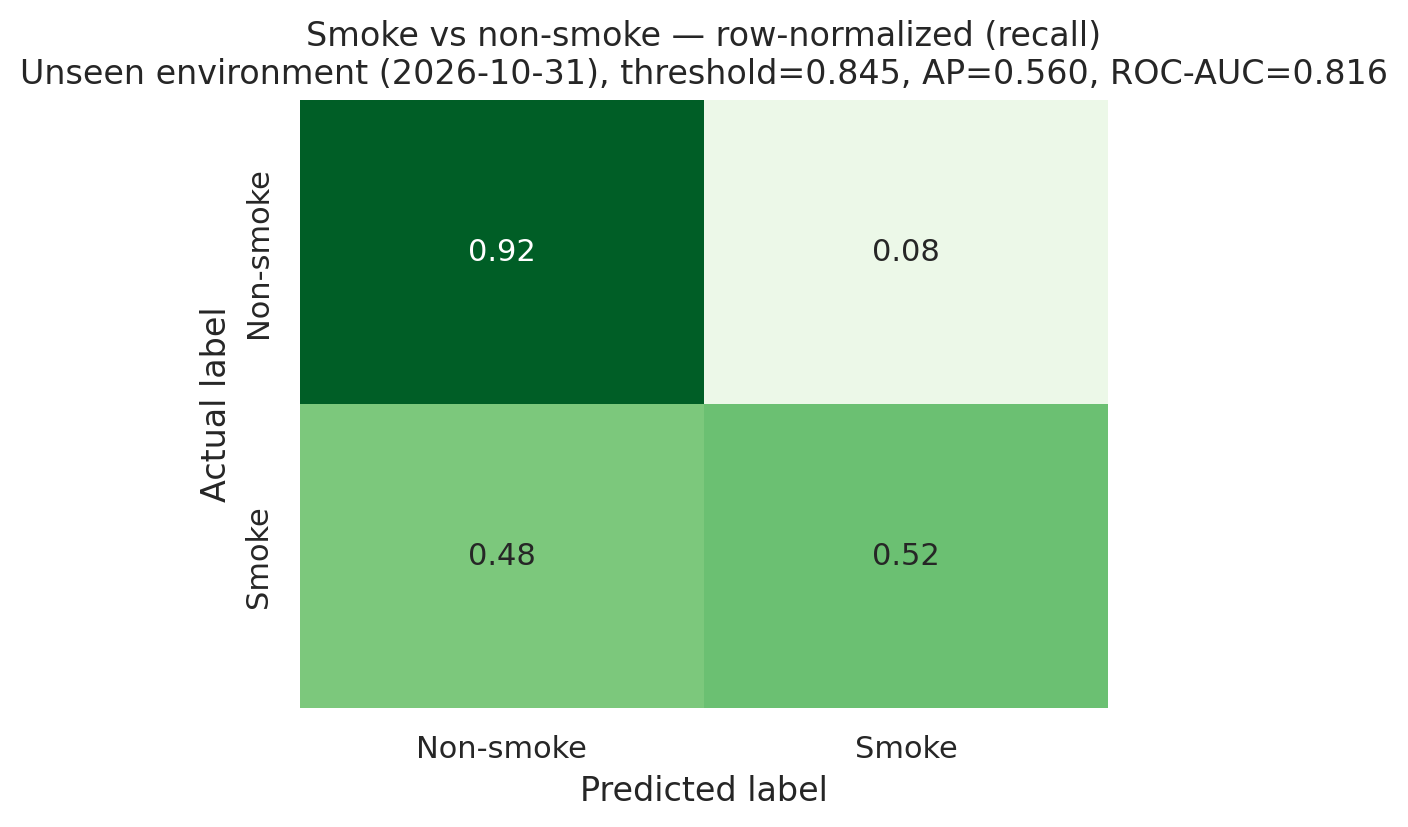

In [ ]:
# ---------------------------------------------------------------------------
# 7e. Smoke vs non-smoke confusion matrix for the unseen environment —
# row-normalized. Each row sums to 1 (diagonal = per-class recall). Standalone
# figure sized for direct reuse in a paper.
# ---------------------------------------------------------------------------
UNSEEN_BINARY_CM_NORM = confusion_matrix(
    UNSEEN_RESULTS['y_binary'], UNSEEN_RESULTS['y_pred_bin'],
    labels=[0, 1], normalize='true',
)
_unseen_binary_metrics = UNSEEN_RESULTS['metrics']

fig, ax = plt.subplots(figsize=(4.9, 4.3), dpi=200)
sns.heatmap(
    UNSEEN_BINARY_CM_NORM, annot=True, fmt='.2f', cmap='Greens', cbar=False,
    vmin=0.0, vmax=1.0, xticklabels=['Non-smoke', 'Smoke'],
    yticklabels=['Non-smoke', 'Smoke'], ax=ax, annot_kws={'fontsize': 11},
)
ax.set_xlabel('Predicted label')
ax.set_ylabel('Actual label')
ax.set_title(
    'Smoke vs non-smoke — row-normalized (recall)\n'
    'Unseen environment (2026-10-31), '
    f'threshold={_unseen_binary_metrics["threshold"]:.3f}, '
    f'AP={_unseen_binary_metrics["bin_ap"]:.3f}, '
    f'ROC-AUC={_unseen_binary_metrics["bin_roc_auc"]:.3f}'
)
fig.tight_layout()
plt.show()


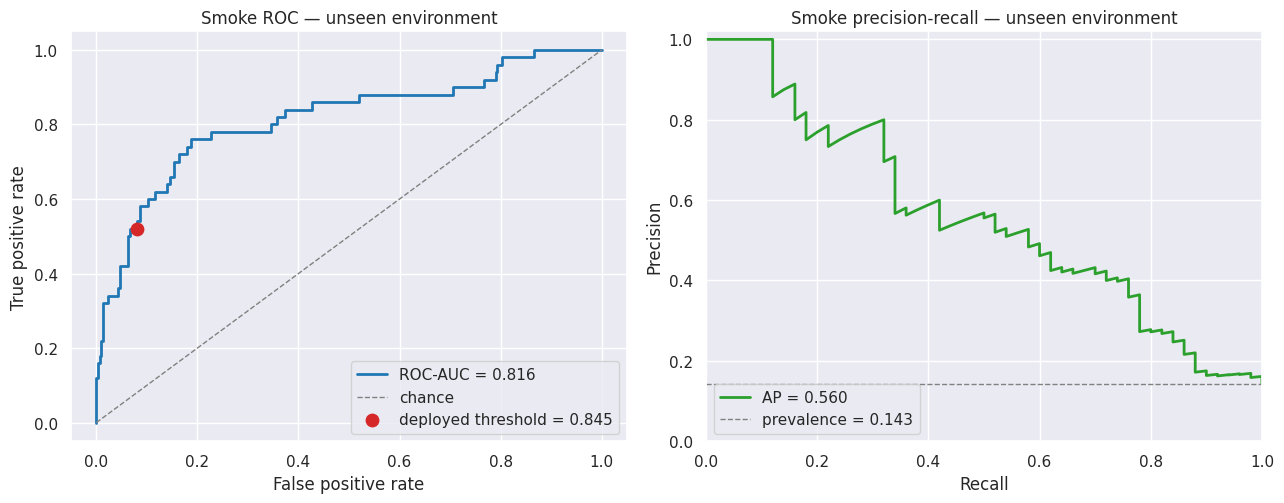


Domain-shift diagnostics


,n,log_loss,brier,ece,accuracy,macro_f1,mean_confidence,mean_smoke_prob
evaluation,,,,,,,,
in-domain held-out test,224,0.4506,0.2130,0.0455,0.8616,0.8609,0.8978,0.1364
unseen environment 2026-10-31,350,3.2896,1.2008,0.5482,0.3057,0.2048,0.8539,0.2344


Predicted-class distribution shift:


,actual share,predicted share,delta (predicted - actual)
smoke,0.1429,0.2429,0.1000
eat,0.1429,0.0000,-0.1429
drink,0.1429,0.0457,-0.0971
sit,0.1429,0.0286,-0.1143
stand,0.1429,0.0314,-0.1114
random,0.1429,0.3686,0.2257
static,0.1429,0.2829,0.1400


Largest per-class recall drops vs the in-domain held-out test:
  stand: 1.000
  sit: 0.969
  eat: 0.906
Predicted static share: 0.283 (actual 0.143)


In [ ]:
# ---------------------------------------------------------------------------
# 7f. Threshold-free curves and domain-shift diagnostics.
# ---------------------------------------------------------------------------
_unseen_metrics = UNSEEN_RESULTS['metrics']
_pr_precision, _pr_recall, _ = precision_recall_curve(
    UNSEEN_RESULTS['y_binary'], UNSEEN_RESULTS['test_pos']
)
_actual_prevalence = float(UNSEEN_RESULTS['y_binary'].mean())

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
axes[0].plot(
    UNSEEN_RESULTS['roc_fpr'], UNSEEN_RESULTS['roc_tpr'],
    color='tab:blue', linewidth=2,
    label=f'ROC-AUC = {_unseen_metrics["bin_roc_auc"]:.3f}',
)
axes[0].plot([0, 1], [0, 1], color='grey', linewidth=1, linestyle='--',
             label='chance')
axes[0].scatter(
    [_unseen_metrics['threshold_fpr']], [_unseen_metrics['threshold_tpr']],
    s=80, color='tab:red', zorder=3,
    label=f'deployed threshold = {_unseen_metrics["threshold"]:.3f}',
)
axes[0].set_xlabel('False positive rate')
axes[0].set_ylabel('True positive rate')
axes[0].set_title('Smoke ROC — unseen environment')
axes[0].legend(loc='lower right')

axes[1].plot(
    _pr_recall, _pr_precision, color='tab:green', linewidth=2,
    label=f'AP = {_unseen_metrics["bin_ap"]:.3f}',
)
axes[1].axhline(
    _actual_prevalence, color='grey', linewidth=1, linestyle='--',
    label=f'prevalence = {_actual_prevalence:.3f}',
)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Smoke precision-recall — unseen environment')
axes[1].set_xlim(0.0, 1.0)
axes[1].set_ylim(0.0, 1.02)
axes[1].legend(loc='lower left')
fig.tight_layout()
plt.show()

print('\nDomain-shift diagnostics')
if 'calibration_metrics' in globals():
    _in_domain_prob = ACTIVITY_MODEL.predict(SESSION_DATA['X_test'], verbose=0)
    _in_domain_calibration = calibration_metrics(
        SESSION_DATA['y_test'], _in_domain_prob
    )
    _unseen_calibration = calibration_metrics(y_unseen7, UNSEEN_PROB)
    UNSEEN_CALIBRATION_COMPARISON = pd.DataFrame([
        {'evaluation': 'in-domain held-out test', **_in_domain_calibration},
        {'evaluation': UNSEEN_SPLIT_NAME, **_unseen_calibration},
    ]).set_index('evaluation')
    display(UNSEEN_CALIBRATION_COMPARISON.round(4))
else:
    print(f'Unseen mean top-label confidence: '
          f'{UNSEEN_PROB.max(axis=1).mean():.4f} '
          '(calibration_metrics unavailable)')

_actual_share = np.bincount(
    y_unseen7, minlength=len(SEVEN_CLASSES)
) / len(y_unseen7)
_predicted_share = np.bincount(
    UNSEEN_RESULTS['y_pred_mc'], minlength=len(SEVEN_CLASSES)
) / len(y_unseen7)
UNSEEN_PREDICTION_SHIFT = pd.DataFrame({
    'actual share': _actual_share,
    'predicted share': _predicted_share,
    'delta (predicted - actual)': _predicted_share - _actual_share,
}, index=SEVEN_CLASSES)
print('Predicted-class distribution shift:')
display(UNSEEN_PREDICTION_SHIFT.round(4))

print('Largest per-class recall drops vs the in-domain held-out test:')
for _class_name, _drop in (
    UNSEEN_PER_CLASS_COMPARISON['recall drop']
    .sort_values(ascending=False).head(3).items()
):
    print(f'  {_class_name}: {_drop:.3f}')
print(f'Predicted static share: '
      f'{_predicted_share[SEVEN_CLASS_TO_IDX["static"]]:.3f} '
      f'(actual {_actual_share[SEVEN_CLASS_TO_IDX["static"]]:.3f})')
